In [2]:
!pip install chromadb sentence-transformers python-docx openpyxl rank-bm25 google-generativeai Pillow

  Using cached python_docx-1.2.0-py3-none-any.whl.metadata (2.0 kB)
INFO: pip is looking at multiple versions of google-api-core to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of google-api-core to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of google-api-core[grpc] to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of google-api-core[grpc] to determine which version is compatible with other requirements. This could take a while.
  Using cached pyasn1_modules-0.4.2-py3-none-any.whl.metadata (3.5 kB)
INFO: pip is looking at multiple versions of googleapis-common-protos to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of grpcio-status to determ

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.21.0 requires protobuf<8.0.0,>=6.31.1, but you have protobuf 5.29.6 which is incompatible.


In [5]:
pip install google-genai

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.4 MB 837.5 kB/s eta 0:00:02
   --------------- ------------------------ 0.5/1.4 MB 837.5 kB/s eta 0:00:02
   ----------------------- ---------------- 0.8/1.4 MB 684.4 kB/s eta 0:00:01
   ----------------------- ---------------- 0.8/1.4 MB 684.4 kB/s eta 0:00:01
   ------------------------------ --------- 1.0/1.4 MB 679.7 kB/s eta 0:00:01
   ------------------------------ --------- 1.0/1.4 MB 679.7 kB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 648.0 kB/s eta 0:00:00
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ---- --------------------------------

  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 5.35.0 requires pydantic<2.12,>=2.0, but you have pydantic 2.14.3 which is incompatible.


In [6]:
import os
import json
import re
from pathlib import Path
from abc import ABC, abstractmethod

from docx import Document
import openpyxl
from PIL import Image
import io

from sentence_transformers import SentenceTransformer
import google.genai as genai  # ← تغيّر هنا
import chromadb
from rank_bm25 import BM25Okapi
import numpy as np

print("✅ كل المكتبات اتحملت!")

✅ كل المكتبات اتحملت!


In [7]:
# ============================================
# 🏗️ Abstraction Layer
# ============================================
class VectorDB(ABC):
    
    @abstractmethod
    def add(self, ids, embeddings, documents, metadatas):
        pass
    
    @abstractmethod
    def search(self, query_embedding, n_results, filters):
        pass
    
    @abstractmethod
    def count(self):
        pass
    
    @abstractmethod
    def delete(self, ids):
        pass


# ============================================
# 🟢 Chroma Implementation
# ============================================
class ChromaDB(VectorDB):
    
    def __init__(self, path: str):
        self.client = chromadb.PersistentClient(path=path)
        self.collection = self.client.get_or_create_collection(
            name="wfm_documents",
            metadata={"hnsw:space": "cosine"}
        )
        print(f"✅ ChromaDB جاهز!")
    
    def add(self, ids, embeddings, documents, metadatas):
        self.collection.add(
            ids=ids,
            embeddings=embeddings,
            documents=documents,
            metadatas=metadatas
        )
    
    def search(self, query_embedding, n_results=10, filters=None):
        return self.collection.query(
            query_embeddings=[query_embedding],
            n_results=n_results,
            where=filters
        )
    
    def count(self):
        return self.collection.count()
    
    def delete(self, ids):
        self.collection.delete(ids=ids)


# ============================================
# 🔵 Qdrant Implementation (للمستقبل)
# ============================================
class QdrantDB(VectorDB):
    
    def __init__(self, path: str):
        pass
    
    def add(self, ids, embeddings, documents, metadatas):
        pass
    
    def search(self, query_embedding, n_results=10, filters=None):
        pass
    
    def count(self):
        pass
    
    def delete(self, ids):
        pass


print("✅ Abstraction Layer جاهز!")

✅ Abstraction Layer جاهز!


In [ ]:
# ============================================
# ⚙️ Configuration
# ============================================
CONFIG = {
    # المسارات
    "model_path":    r"D:\internship\rag\model",
    "docs_path":     r"D:\internship\rag\p\WFM_CLEAN",
    "chroma_path":   r"D:\internship\rag\chroma_db",
    "images_path":   r"D:\internship\rag\images",
    "metadata_path": r"D:\internship\rag\metadata",

    # Gemini API
    "gemini_api_key": "",

    # Chunking
    "chunk_size":    500,
    "chunk_overlap": 50,

    # Search
    "top_k": 10,
    "rrf_k": 60,
}

# إنشاء الفولدرات
for key in ["chroma_path", "images_path", "metadata_path"]:
    os.makedirs(CONFIG[key], exist_ok=True)
    print(f"📁 {key}: {CONFIG[key]}")

print("\n✅ Configuration جاهز!")

📁 chroma_path: D:\internship\rag\chroma_db
📁 images_path: D:\internship\rag\images
📁 metadata_path: D:\internship\rag\metadata

✅ Configuration جاهز!


In [12]:
from sentence_transformers import SentenceTransformer

# المسار
MODEL_PATH = r"D:\internship\rag\model"

# تحميل وحفظ
print("⏳ جاري تحميل الـ Model...")
model = SentenceTransformer("all-MiniLM-L6-v2")
model.save(MODEL_PATH)
print(f"✅ Model اتحفظ في: {MODEL_PATH}")

⏳ جاري تحميل الـ Model...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Model اتحفظ في: D:\internship\rag\model


In [13]:
# تأكد من المسار
import os
files = os.listdir(MODEL_PATH)
print(f"📁 الملفات في المسار:")
for f in files:
    print(f"   - {f}")

📁 الملفات في المسار:
   - 1_Pooling
   - 2_Normalize
   - config.json
   - config_sentence_transformers.json
   - model.safetensors
   - modules.json
   - README.md
   - sentence_bert_config.json
   - tokenizer.json
   - tokenizer_config.json


In [17]:
# ============================================
# 🧠 تحميل الـ Models
# ============================================

# Local Model للـ Indexing والـ Query
print("⏳ Loading Local Model...")
local_model = SentenceTransformer(
    CONFIG["model_path"],
    local_files_only=True
)
print(f"✅ Local Model جاهز!")
print(f"📊 Dimension: 384")

# ============================================
# 🧪 تجربة بسيطة
# ============================================
test_local = local_model.encode("Hello World")
print(f"\n🧪 Local Model Test:")
print(f"   Dimension: {len(test_local)}")

print("\n✅ Model جاهز!")

⏳ Loading Local Model...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

✅ Local Model جاهز!
📊 Dimension: 384

🧪 Local Model Test:
   Dimension: 384

✅ Model جاهز!


In [18]:
# ============================================
# 🗄️ إنشاء الـ Vector DB
# ============================================

db = ChromaDB(path=CONFIG["chroma_path"])

print(f"📊 Documents في الـ DB: {db.count()}")

✅ ChromaDB جاهز!
📊 Documents في الـ DB: 0


In [19]:
# ============================================
# 📄 قراءة ملفات Word
# ============================================
def read_docx(file_path: str) -> dict:
    
    doc = Document(file_path)
    
    result = {
        "sections": [],
        "tables":   [],
        "images":   [],
    }
    
    current_section = {
        "heading": "Introduction",
        "level":   0,
        "content": []
    }
    
    for para in doc.paragraphs:
        
        text = para.text.strip()
        if not text:
            continue
        
        # لو heading
        if para.style.name.startswith("Heading"):
            # حفظ الـ section القديم
            if current_section["content"]:
                result["sections"].append(
                    current_section.copy()
                )
            # بدأ section جديد
            level = para.style.name[-1]
            current_section = {
                "heading": text,
                "level":   int(level),
                "content": []
            }
        else:
            current_section["content"].append(text)
    
    # حفظ آخر section
    if current_section["content"]:
        result["sections"].append(current_section)
    
    # قراءة الجداول
    for table in doc.tables:
        rows = []
        for row in table.rows:
            cells = [
                cell.text.strip() 
                for cell in row.cells
            ]
            if any(cells):
                rows.append(cells)
        
        if not rows:
            continue
        
        # تحويل لـ Markdown
        md = "| " + " | ".join(rows[0]) + " |\n"
        md += "| " + " | ".join(
            ["---"] * len(rows[0])
        ) + " |\n"
        for row in rows[1:]:
            md += "| " + " | ".join(row) + " |\n"
        
        result["tables"].append(md)
        result["sections"][-1]["content"].append(md)
    
    # قراءة الصور
    for i, rel in enumerate(doc.part.rels.values()):
        if "image" in rel.reltype:
            try:
                image_data = rel.target_part.blob
                image_name = f"{Path(file_path).stem}_img_{i+1}.png"
                image_path = os.path.join(
                    CONFIG["images_path"],
                    image_name
                )
                image = Image.open(io.BytesIO(image_data))
                image.save(image_path)
                
                result["images"].append({
                    "image_id":   f"{Path(file_path).stem}_img_{i+1}",
                    "image_path": image_path,
                    "image_name": image_name,
                })
            except Exception as e:
                print(f"⚠️ Image error: {e}")
    
    return result


# ============================================
# 📊 قراءة ملفات Excel
# ============================================
def read_xlsx(file_path: str) -> dict:
    
    wb = openpyxl.load_workbook(file_path)
    
    result = {
        "sections": [],
        "tables":   [],
        "images":   []
    }
    
    for sheet_name in wb.sheetnames:
        ws = wb[sheet_name]
        
        rows = []
        for row in ws.iter_rows(values_only=True):
            clean_row = [
                str(cell) if cell else ""
                for cell in row
            ]
            if any(clean_row):
                rows.append(clean_row)
        
        if not rows:
            continue
        
        # تحويل لـ Markdown
        md = "| " + " | ".join(rows[0]) + " |\n"
        md += "| " + " | ".join(
            ["---"] * len(rows[0])
        ) + " |\n"
        for row in rows[1:]:
            md += "| " + " | ".join(row) + " |\n"
        
        result["sections"].append({
            "heading": sheet_name,
            "level":   1,
            "content": [md]
        })
        result["tables"].append(md)
    
    return result


# ============================================
# 🧪 تجربة
# ============================================
test_file = list(Path(CONFIG["docs_path"]).rglob("*.docx"))[0]
print(f"🧪 Testing with: {test_file.name}")

test_content = read_docx(str(test_file))
print(f"✅ Sections: {len(test_content['sections'])}")
print(f"✅ Tables:   {len(test_content['tables'])}")
print(f"✅ Images:   {len(test_content['images'])}")

print("\n✅ Document Readers جاهزين!")

🧪 Testing with: (CR-2023-83)WFM Customer Care Portal FRS - v(0.3).docx
✅ Sections: 13
✅ Tables:   3
✅ Images:   7

✅ Document Readers جاهزين!


In [21]:
# ============================================
# ✂️ Structure-Aware Chunking
# ============================================
def chunk_document(
    doc_content: dict,
    file_info: dict
) -> list:
    
    chunks = []
    chunk_id = 0
    
    for section in doc_content["sections"]:
        
        heading = section["heading"]
        content = "\n".join(section["content"])
        
        if not content.strip():
            continue
        
        words = content.split()
        start = 0
        
        while start < len(words):
            
            end = min(
                start + CONFIG["chunk_size"],
                len(words)
            )
            
            chunk_text = " ".join(words[start:end])
            full_chunk = f"{heading}\n\n{chunk_text}"
            
            chunks.append({
                "chunk_id":  f"{file_info['cr_number']}_{chunk_id}",
                "text":      full_chunk,
                "heading":   heading,
                "cr_number": file_info["cr_number"],
                "category":  file_info["category"],
                "doc_type":  file_info["type"],
                "version":   file_info["version"],
                "filename":  file_info["filename"],
            })
            
            chunk_id += 1
            
            # ← الحل هنا
            if end >= len(words):
                break
            
            start = end - CONFIG["chunk_overlap"]
    
    # إضافة الصور
    for image in doc_content["images"]:
        chunks.append({
            "chunk_id":   f"{file_info['cr_number']}_img_{chunk_id}",
            "text":       f"Image: {image['image_name']}",
            "heading":    "Image",
            "cr_number":  file_info["cr_number"],
            "category":   file_info["category"],
            "doc_type":   "Image",
            "version":    file_info["version"],
            "filename":   file_info["filename"],
            "image_path": image["image_path"],
            "is_image":   True
        })
        chunk_id += 1
    
    return chunks


# ============================================
# 🧪 تجربة
# ============================================
test_chunks = chunk_document(
    test_content,
    {
        "cr_number": "CR-2023-83",
        "category":  "Work_Orders",
        "type":      "FRS_BPD",
        "version":   "v0.3",
        "filename":  test_file.name
    }
)

text_chunks  = [c for c in test_chunks if not c.get("is_image")]
image_chunks = [c for c in test_chunks if c.get("is_image")]

print(f"✅ Text Chunks:  {len(text_chunks)}")
print(f"✅ Image Chunks: {len(image_chunks)}")
print(f"\n🧪 Sample Chunk:")
print(f"   Heading: {text_chunks[0]['heading']}")
print(f"   Text:    {text_chunks[0]['text'][:100]}...")

print("\n✅ Chunking جاهز!")

✅ Text Chunks:  13
✅ Image Chunks: 7

🧪 Sample Chunk:
   Heading: Purpose
   Text:    Purpose

The purpose of this document is to specify the functional requirement specification of the ...

✅ Chunking جاهز!


In [26]:
# ============================================
# ✂️ Structure-Aware Chunking
# ============================================
def chunk_document(
    doc_content: dict,
    file_info: dict,
    file_index: int  # ← رقم فريد لكل ملف
) -> list:
    
    chunks = []
    chunk_id = 0
    
    for section in doc_content["sections"]:
        
        heading = section["heading"]
        content = "\n".join(section["content"])
        
        if not content.strip():
            continue
        
        words = content.split()
        start = 0
        
        while start < len(words):
            
            end = min(
                start + CONFIG["chunk_size"],
                len(words)
            )
            
            chunk_text = " ".join(words[start:end])
            full_chunk = f"{heading}\n\n{chunk_text}"
            
            chunks.append({
                # ← file_index بيضمن التفرد
                "chunk_id":  f"file{file_index}_chunk{chunk_id}",
                "text":      full_chunk,
                "heading":   heading,
                "cr_number": file_info["cr_number"],
                "category":  file_info["category"],
                "doc_type":  file_info["type"],
                "version":   file_info["version"],
                "filename":  file_info["filename"],
            })
            
            chunk_id += 1
            
            if end >= len(words):
                break
            
            start = end - CONFIG["chunk_overlap"]
    
    # إضافة الصور
    for image in doc_content["images"]:
        chunks.append({
            "chunk_id":   f"file{file_index}_img{chunk_id}",
            "text":       f"Image: {image['image_name']}",
            "heading":    "Image",
            "cr_number":  file_info["cr_number"],
            "category":   file_info["category"],
            "doc_type":   "Image",
            "version":    file_info["version"],
            "filename":   file_info["filename"],
            "image_path": image["image_path"],
            "is_image":   True
        })
        chunk_id += 1
    
    return chunks

print("✅ Chunking جاهز!")

✅ Chunking جاهز!


In [ ]:
# ============================================
# 📥 Indexing كل الملفات
# ============================================
def index_all_files():
    
    with open("cleaned/final_files.json", "r",
              encoding="utf-8") as f:
        final_files = json.load(f)
    
    print(f"📂 هنعمل Index لـ {len(final_files)} ملف\n")
    
    all_chunks         = []
    all_image_metadata = []
    errors             = []
    
    for i, file_info in enumerate(final_files):
        
        filename = file_info["filename"]
        ext      = file_info["extension"]
        
        file_path = os.path.join(
            CONFIG["docs_path"],
            file_info["category"],
            file_info["cr_number"],
            file_info["type"],
            filename
        )
        
        if not os.path.exists(file_path):
            errors.append(filename)
            continue
        
        print(f"[{i+1}/{len(final_files)}] {filename[:50]}")
        
        try:
            if ext == ".docx":
                content = read_docx(file_path)
            elif ext == ".xlsx":
                content = read_xlsx(file_path)
            else:
                continue
            
            # ← بنضيف i كـ file_index
            chunks = chunk_document(content, file_info, i)
            
            text_chunks  = [c for c in chunks if not c.get("is_image")]
            image_chunks = [c for c in chunks if c.get("is_image")]
            
            all_chunks.extend(text_chunks)
            all_image_metadata.extend(image_chunks)
            
            print(f"   ✅ {len(text_chunks)} chunks | 🖼️ {len(image_chunks)} images")
            
        except Exception as e:
            print(f"   ❌ Error: {e}")
            errors.append(filename)
    
    print(f"\n📊 Total chunks: {len(all_chunks)}")
    print(f"🖼️  Total images: {len(all_image_metadata)}")
    print(f"❌ Errors:       {len(errors)}")
    
    # Embedding وحفظ في Chroma
    print("\n⏳ جاري الـ Embedding...")
    
    batch_size = 50
    
    for i in range(0, len(all_chunks), batch_size):
        batch     = all_chunks[i:i+batch_size]
        texts     = [c["text"]     for c in batch]
        ids       = [c["chunk_id"] for c in batch]
        metadatas = [{
            "cr_number": c["cr_number"],
            "category":  c["category"],
            "doc_type":  c["doc_type"],
            "version":   c["version"],
            "filename":  c["filename"],
            "heading":   c["heading"],
        } for c in batch]
        
        embeddings = local_model.encode(
            texts,
            normalize_embeddings=True
        ).tolist()
        
        db.add(
            ids=ids,
            embeddings=embeddings,
            documents=texts,
            metadatas=metadatas
        )
        
        print(f"   ✅ Batch {i//batch_size + 1}/{len(all_chunks)//batch_size + 1}")
    
    # حفظ Metadata الصور
    with open(
        f"{CONFIG['metadata_path']}/images_metadata.json",
        "w", encoding="utf-8"
    ) as f:
        json.dump(
            all_image_metadata, f,
            ensure_ascii=False, indent=2
        )
    
    print(f"\n✅ Indexing خلص!")
    print(f"📊 Total in DB: {db.count()}")
    
    return all_chunks, all_image_metadata




# شغّل الـ Indexing
all_chunks, all_images = index_all_files()

✅ ChromaDB جاهز!
📂 هنعمل Index لـ 143 ملف

[3/143] (CR-2024-136)WFM BOX Complain CR (V0.1).docx
   ✅ 8 chunks | 🖼️ 2 images
[4/143] WFM - SA Post Production - Modify SA APIs CR v3 -.
   ✅ 8 chunks | 🖼️ 1 images
[5/143] (CR-2024-170) WFM Detect Enterprise Work Orders CR
   ✅ 2 chunks | 🖼️ 0 images
[6/143] FTTH_Portal_Add_ODN_network_type_ATPs(v1.0).docx
   ✅ 7 chunks | 🖼️ 3 images
[7/143] ODN IOT TC(V1.0).xlsx
   ✅ 3 chunks | 🖼️ 0 images
[8/143] (CR-2025-202)_FTTH_Portal_Add_ODN_network_type_CR.
   ✅ 5 chunks | 🖼️ 1 images
[9/143] WFM Detect Enterprise Migration CR ATPs (v1.0).doc
   ✅ 2 chunks | 🖼️ 3 images
[10/143] (CR-2025-203) WFM Detect Enterprise Migration CR (
   ✅ 2 chunks | 🖼️ 0 images
[11/143] WFM_Remove Reservation Activity-damaged port.docx
   ✅ 11 chunks | 🖼️ 1 images
[12/143] CR-2025-209 WFM_Enterprise_Maintenance_(v0.5).docx
   ✅ 17 chunks | 🖼️ 12 images
[15/143] CR-2025-213  Avail fail scenario in data maintenan
   ✅ 4 chunks | 🖼️ 1 images
[16/143] CR-2025-214   Remove p

In [28]:
# ============================================
# 🔍 Hybrid Search
# ============================================

# BM25 Index
print("⏳ Building BM25 Index...")
all_texts  = [c["text"] for c in all_chunks]
tokenized  = [t.lower().split() for t in all_texts]
bm25       = BM25Okapi(tokenized)
print("✅ BM25 Index جاهز!")


def rrf_fusion(dense_ids, bm25_ids, k=60):
    scores = {}
    for rank, doc_id in enumerate(dense_ids, 1):
        scores[doc_id] = scores.get(doc_id, 0) + 1/(k+rank)
    for rank, doc_id in enumerate(bm25_ids, 1):
        scores[doc_id] = scores.get(doc_id, 0) + 1/(k+rank)
    return sorted(scores, key=scores.get, reverse=True)


def hybrid_search(query, top_k=5, category=None):
    
    print(f"\n🔍 Query: {query}")
    
    # 1. Dense Search
    query_embedding = local_model.encode(
        query,
        normalize_embeddings=True
    ).tolist()
    
    filters = {"category": category} if category else None
    
    dense_results = db.search(
        query_embedding=query_embedding,
        n_results=top_k * 2,
        filters=filters
    )
    
    dense_ids  = dense_results["ids"][0]
    dense_docs = dense_results["documents"][0]
    dense_meta = dense_results["metadatas"][0]
    
    # 2. BM25 Search
    bm25_scores = bm25.get_scores(query.lower().split())
    bm25_top    = np.argsort(-bm25_scores)[:top_k * 2]
    bm25_ids    = [all_chunks[i]["chunk_id"] for i in bm25_top]
    
    # 3. RRF Fusion
    fused_ids = rrf_fusion(dense_ids, bm25_ids)
    
    # 4. جمع النتائج
    results = []
    seen    = set()
    
    for chunk_id in fused_ids[:top_k]:
        if chunk_id in dense_ids and chunk_id not in seen:
            idx = dense_ids.index(chunk_id)
            results.append({
                "chunk_id": chunk_id,
                "text":     dense_docs[idx],
                "metadata": dense_meta[idx],
            })
            seen.add(chunk_id)
    
    return results


def search_and_display(query, category=None):
    
    results = hybrid_search(query, category=category)
    
    print(f"\n📊 النتائج ({len(results)}):")
    print("=" * 50)
    
    for i, r in enumerate(results, 1):
        print(f"\n[{i}] 📄 {r['metadata']['filename'][:50]}")
        print(f"    CR#:      {r['metadata']['cr_number']}")
        print(f"    Category: {r['metadata']['category']}")
        print(f"    Heading:  {r['metadata']['heading']}")
        print(f"    Text:     {r['text'][:150]}...")


print("✅ Search جاهز!")

⏳ Building BM25 Index...
✅ BM25 Index جاهز!
✅ Search جاهز!


In [29]:
# ============================================
# 🧪 تجربة الـ Search
# ============================================

# سؤال 1: عام
search_and_display(
    "What is the automatic scheduling enhancement?"
)


🔍 Query: What is the automatic scheduling enhancement?

📊 النتائج (5):

[1] 📄 (CR-2024-152)WFM FO Scheduling - Modify Time Inter
    CR#:      CR-2024-152
    Category: Scheduling
    Heading:  Impact on Automatic Scheduling
    Text:     Impact on Automatic Scheduling

Automatic scheduling selects the first free time slot starting from the next day In case this free time slot is within...

[2] 📄 (CR-2025-220)WFM Automatic Scheduling Enhancement 
    CR#:      CR-2025-220
    Category: Scheduling
    Heading:  Automatic scheduling
    Text:     Automatic scheduling

Automatic scheduling for FO FTTH installation and FO maintenance cannot assign scheduling date after X days from order creation ...

[3] 📄 (PM-2024-126)WFM Scheduling Portal - FO Maintenanc
    CR#:      PM-2024-126
    Category: Scheduling
    Heading:  Re-Open Work Order
    Text:     Re-Open Work Order

If FCC requests to re-open work order (Send re-open flag), order is considered as critical and automatic scheduling is

In [30]:
# سؤال 2: بـ Category Filter
search_and_display(
    "force close work order",
    category="Work_Orders"
)


🔍 Query: force close work order

📊 النتائج (3):

[1] 📄 CR-2025-214   Remove permission for all FME to clo
    CR#:      CR-2025-214
    Category: Work_Orders
    Heading:  Scope of Work
    Text:     Scope of Work

The scope of this document modifies above all maintenance reopened work orders workflow as flows. In case reopen, If the FME selects an...

[2] 📄 CR-2025-214   Remove permission for all FME to clo
    CR#:      CR-2025-214
    Category: Work_Orders
    Heading:  Desired Behavior
    Text:     Desired Behavior

Modify all maintenance work orders reopened orders workflow Voice Overlapping If the user selects any mentioned scenario that leads ...

[3] 📄 (CR-2026-265) FTTH WCAP Re-open work orders(0.2) .
    CR#:      CR-2026-265
    Category: Work_Orders
    Heading:  Scope of Work
    Text:     Scope of Work

Modify the FME task in "FTTH Wrong Card and Port" work order for re-opened orders as follows: In case discovery validation success (Dat...


In [41]:
def generate_answer(query: str, chunks: list) -> str:
    
    context = ""
    for i, chunk in enumerate(chunks, 1):
        context += f"\n[Source {i}]\n{chunk['text']}\n"
    
    prompt = f"""
You are a WFM (Workforce Management) expert assistant.

INSTRUCTIONS:
- Answer based on the provided sources below
- Be specific and detailed
- Quote relevant parts from the sources
- If information is partial, share what you found
- Only say "I don't have information" if sources have NO relation to the question

SOURCES:
{context}

QUESTION: {query}

DETAILED ANSWER:
"""
    
    for model_name in MODELS_TO_TRY:
        try:
            response = client.models.generate_content(
                model=model_name,
                contents=prompt
            )
            print(f"✅ Used: {model_name}")
            return response.text
        except Exception as e:
            print(f"⚠️ {model_name} failed: {str(e)[:50]}")
            continue
    
    return "❌ كل الـ Models مش متاحة دلوقتي"


def ask(query: str, category: str = None):
    
    chunks = hybrid_search(query, category=category)
    
    print(f"\n🔍 Query: {query}")
    print(f"\n📚 Context from {len(chunks)} chunks")
    print("\n🤖 Answer:")
    print("=" * 50)
    
    answer = generate_answer(query, chunks)
    print(answer)
    
    print("\n📄 Sources:")
    seen = set()
    for chunk in chunks:
        fname = chunk['metadata']['filename']
        if fname not in seen:
            print(f"   - {fname[:60]}")
            seen.add(fname)

print("✅ LLM جاهز!")

✅ LLM جاهز!


In [42]:
# ============================================
# 🧪 تجربة الـ RAG الكامل
# ============================================

ask("What is the automatic scheduling enhancement?")


🔍 Query: What is the automatic scheduling enhancement?

🔍 Query: What is the automatic scheduling enhancement?

📚 Context from 5 chunks

🤖 Answer:
✅ Used: models/gemini-3.8-flash
Based on the provided sources, the **automatic scheduling enhancement** automates visit scheduling with customers for FO FTTH installation and FO maintenance orders across several functional areas:

---

### 1. The "X Days" Scheduling Window & Slot Selection
* **Next-Day Start and X-Days Constraint:** Automatic scheduling *"selects the first free time slot starting from the next day"* [Source 1] and *"cannot assign scheduling date after X days from order creation (selects the first available time interval with free time slots in the next X days)"* [Source 2]. 
* **Calculation of Days:** *"X days are calculated from work order creation"* [Source 4].
* **Configurable Days:** The number of days is configurable via SR:
  * *"initially set to 3 for installation orders"* [Source 2].
  * *"initially set to 5 for mai

In [6]:
# ============================================
# 🚀 FULL SETUP CELL
# ============================================
import os
import json
import re
import io
import numpy as np
import torch
from pathlib import Path
from abc import ABC, abstractmethod
from transformers import pipeline

from sentence_transformers import SentenceTransformer
import chromadb
from rank_bm25 import BM25Okapi

# ============================================
# ⚙️ Configuration
# ============================================
CONFIG = {
    "model_path":    r"D:\internship\rag\model",
    "gen_model_path":r"D:\internship\rag\gen_model",
    "chroma_path":   r"D:\internship\rag\chroma_db",
    "images_path":   r"D:\internship\rag\images",
    "metadata_path": r"D:\internship\rag\metadata",
    "chunk_size":    500,
    "chunk_overlap": 50,
    "top_k":         5,
    "rrf_k":         60,
}

# ============================================
# 🏗️ Abstraction Layer
# ============================================
class VectorDB(ABC):
    @abstractmethod
    def add(self, ids, embeddings, documents, metadatas):
        pass
    @abstractmethod
    def search(self, query_embedding, n_results, filters):
        pass
    @abstractmethod
    def count(self):
        pass
    @abstractmethod
    def delete(self, ids):
        pass

class ChromaDB(VectorDB):
    def __init__(self, path: str):
        self.client = chromadb.PersistentClient(path=path)
        self.collection = self.client.get_or_create_collection(
            name="wfm_documents",
            metadata={"hnsw:space": "cosine"}
        )
    def add(self, ids, embeddings, documents, metadatas):
        self.collection.add(
            ids=ids,
            embeddings=embeddings,
            documents=documents,
            metadatas=metadatas
        )
    def search(self, query_embedding, n_results=10, filters=None):
        return self.collection.query(
            query_embeddings=[query_embedding],
            n_results=n_results,
            where=filters
        )
    def count(self):
        return self.collection.count()
    def delete(self, ids):
        self.collection.delete(ids=ids)

class QdrantDB(VectorDB):
    def __init__(self, path: str):
        pass
    def add(self, ids, embeddings, documents, metadatas):
        pass
    def search(self, query_embedding, n_results=10, filters=None):
        pass
    def count(self):
        pass
    def delete(self, ids):
        pass

# ============================================
# 🧠 تحميل الـ Models
# ============================================
print("⏳ Loading Embedding Model...")
local_model = SentenceTransformer(
    CONFIG["model_path"],
    local_files_only=True
)
print("✅ Embedding Model جاهز!")

print("⏳ Loading Generation Model...")
generator = pipeline(
    "text-generation",
    model=CONFIG["gen_model_path"],
    device=0 if torch.cuda.is_available() else -1,
    torch_dtype=torch.float16
)
print("✅ Generation Model جاهز!")

# ============================================
# 🗄️ تحميل الـ DB
# ============================================
print("⏳ Loading DB...")
db = ChromaDB(path=CONFIG["chroma_path"])
print(f"✅ DB جاهز! ({db.count()} chunks)")

# ============================================
# 📦 تحميل الـ Chunks
# ============================================
print("⏳ Loading chunks...")
all_chunks = []
total      = db.count()

results = db.search(
    query_embedding=local_model.encode(
        "work order",
        normalize_embeddings=True
    ).tolist(),
    n_results=total,
    filters=None
)

for i in range(len(results["ids"][0])):
    all_chunks.append({
        "chunk_id": results["ids"][0][i],
        "text":     results["documents"][0][i],
        "filename": results["metadatas"][0][i]["filename"],
        "category": results["metadatas"][0][i]["category"],
        "cr_number":results["metadatas"][0][i]["cr_number"],
        "heading":  results["metadatas"][0][i]["heading"],
    })

print(f"✅ Loaded: {len(all_chunks)} chunks")

# ============================================
# 🔍 BM25
# ============================================
print("⏳ Building BM25...")
tokenized = [c["text"].lower().split() for c in all_chunks]
bm25      = BM25Okapi(tokenized)
print("✅ BM25 جاهز!")

# ============================================
# 🔍 Search Functions
# ============================================
def rrf_fusion(dense_ids, bm25_ids, k=60):
    scores = {}
    for rank, doc_id in enumerate(dense_ids, 1):
        scores[doc_id] = scores.get(doc_id, 0) + 1/(k+rank)
    for rank, doc_id in enumerate(bm25_ids, 1):
        scores[doc_id] = scores.get(doc_id, 0) + 1/(k+rank)
    return sorted(scores, key=scores.get, reverse=True)

def hybrid_search(query, top_k=5, category=None):
    query_embedding = local_model.encode(
        query, normalize_embeddings=True
    ).tolist()
    filters     = {"category": category} if category else None
    dense_res   = db.search(query_embedding, top_k*2, filters)
    dense_ids   = dense_res["ids"][0]
    dense_docs  = dense_res["documents"][0]
    dense_meta  = dense_res["metadatas"][0]
    bm25_scores = bm25.get_scores(query.lower().split())
    bm25_top    = np.argsort(-bm25_scores)[:top_k*2]
    bm25_ids    = [all_chunks[i]["chunk_id"] for i in bm25_top]
    fused_ids   = rrf_fusion(dense_ids, bm25_ids)
    results = []
    seen    = set()
    for chunk_id in fused_ids[:top_k]:
        if chunk_id in dense_ids and chunk_id not in seen:
            idx = dense_ids.index(chunk_id)
            results.append({
                "chunk_id": chunk_id,
                "text":     dense_docs[idx],
                "metadata": dense_meta[idx],
            })
            seen.add(chunk_id)
    return results

# ============================================
# 🤖 Generate Answer
# ============================================
def generate_answer_local(query: str, chunks: list) -> str:
    context = ""
    for i, chunk in enumerate(chunks, 1):
        context += f"\n[{i}] {chunk['text'][:300]}\n"
    
    messages = [
        {
            "role": "system",
            "content": (
                "You are a WFM expert assistant. "
                "Answer based ONLY on the provided context. "
                "Be concise and specific."
            )
        },
        {
            "role": "user",
            "content": f"Context:\n{context}\n\nQuestion: {query}"
        }
    ]
    
    prompt = generator.tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    
    response = generator(
        prompt,
        max_new_tokens=300,
        do_sample=False,
        temperature=None,
        top_p=None
    )
    
    full_text = response[0]['generated_text']
    answer    = full_text.split("<|assistant|>")[-1].strip()
    return answer

def ask(query: str, category: str = None):
    chunks = hybrid_search(query, category=category)
    print(f"\n🔍 Query: {query}")
    print(f"📚 Context: {len(chunks)} chunks")
    print("\n🤖 Answer:")
    print("=" * 50)
    answer = generate_answer_local(query, chunks)
    print(answer)
    print("\n📄 Sources:")
    seen = set()
    for chunk in chunks:
        fname = chunk['metadata']['filename']
        if fname not in seen:
            print(f"   - {fname[:60]}")
            seen.add(fname)

print("\n✅ كل حاجة جاهزة!")
print(f"📊 Chunks: {len(all_chunks)}")
print("🚀 جاهز للاستخدام!")

⏳ Loading Embedding Model...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

✅ Embedding Model جاهز!
⏳ Loading Generation Model...


Loading weights:   0%|          | 0/201 [00:04<?, ?it/s]

✅ Generation Model جاهز!
⏳ Loading DB...
✅ DB جاهز! (957 chunks)
⏳ Loading chunks...
✅ Loaded: 957 chunks
⏳ Building BM25...
✅ BM25 جاهز!

✅ كل حاجة جاهزة!
📊 Chunks: 957
🚀 جاهز للاستخدام!


In [8]:
ask("What is the automatic scheduling enhancement?")

[transformers] Both `max_new_tokens` (=300) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



🔍 Query: What is the automatic scheduling enhancement?
📚 Context: 5 chunks

🤖 Answer:
The automatic scheduling enhancement is to allow automatic scheduling to select the first available time slot starting from the next day, regardless of the X days window. This ensures that the time slots are available for the FO FTTH installation and FO maintenance orders, even if they are beyond the X days window.

📄 Sources:
   - (CR-2024-152)WFM FO Scheduling - Modify Time Intervals Confi
   - (CR-2025-220)WFM Automatic Scheduling Enhancement CR (V0.2).
   - (PM-2024-126)WFM Scheduling Portal - FO Maintenance FRS (V0.


In [9]:
# ============================================
# 🧪 Test Set يدوي
# ============================================

test_set = [
    {
        "question": "What is the automatic scheduling enhancement?",
        "relevant_chunks": ["CR-2025-220"],
        "category": "Scheduling"
    },
    {
        "question": "What is force close work order?",
        "relevant_chunks": ["CR-2023-83"],
        "category": "Work_Orders"
    },
    {
        "question": "What is FTTH maintenance?",
        "relevant_chunks": ["PM-2024-168"],
        "category": "Maintenance"
    },
    {
        "question": "What is reserve activation no free port?",
        "relevant_chunks": ["CR-2025-226"],
        "category": "Installation"
    },
    {
        "question": "What is KPI report for team leader?",
        "relevant_chunks": ["CR-2025-218"],
        "category": "Dashboard_Reports"
    }
]

os.makedirs("evaluation", exist_ok=True)

# ============================================
# 📊 Evaluation Metrics
# ============================================
import time

def evaluate_retrieval(test_set, k=5):
    """
    Recall@k, Precision@k, MRR
    """
    
    recall_scores    = []
    precision_scores = []
    mrr_scores       = []
    latency_scores   = []
    
    print("🔍 Evaluating Retrieval...")
    print("=" * 50)
    
    for i, test in enumerate(test_set):
        
        query    = test["question"]
        relevant = test["relevant_chunks"]
        
        # قياس الوقت
        start = time.time()
        chunks = hybrid_search(query, top_k=k)
        end   = time.time()
        
        latency = end - start
        latency_scores.append(latency)
        
        # الـ CR numbers في النتائج
        retrieved_crs = [
            c["metadata"]["cr_number"]
            for c in chunks
        ]
        
        # Recall@k
        hits    = sum(1 for r in relevant if r in retrieved_crs)
        recall  = hits / len(relevant)
        recall_scores.append(recall)
        
        # Precision@k
        precision = hits / k
        precision_scores.append(precision)
        
        # MRR
        mrr = 0
        for rank, cr in enumerate(retrieved_crs, 1):
            if cr in relevant:
                mrr = 1 / rank
                break
        mrr_scores.append(mrr)
        
        print(f"\n[{i+1}] {query[:50]}")
        print(f"   Recall@{k}:    {recall:.2f}")
        print(f"   Precision@{k}: {precision:.2f}")
        print(f"   MRR:          {mrr:.2f}")
        print(f"   Latency:      {latency:.2f}s")
        print(f"   Retrieved:    {retrieved_crs}")
    
    # المتوسطات
    results = {
        "Recall@k":    round(np.mean(recall_scores), 3),
        "Precision@k": round(np.mean(precision_scores), 3),
        "MRR":         round(np.mean(mrr_scores), 3),
        "Avg_Latency": round(np.mean(latency_scores), 3),
        "k":           k
    }
    
    print("\n" + "=" * 50)
    print("📊 FINAL RESULTS:")
    print("=" * 50)
    for metric, value in results.items():
        print(f"   {metric}: {value}")
    
    return results


# شغّل الـ Evaluation
eval_results = evaluate_retrieval(test_set, k=5)

# حفظ النتائج
with open("evaluation/retrieval_results.json", "w",
          encoding="utf-8") as f:
    json.dump(eval_results, f, 
              ensure_ascii=False, indent=2)

print("\n✅ Results saved!")

🔍 Evaluating Retrieval...

[1] What is the automatic scheduling enhancement?
   Recall@5:    1.00
   Precision@5: 0.20
   MRR:          0.50
   Latency:      0.29s
   Retrieved:    ['CR-2024-152', 'CR-2025-220', 'PM-2024-126', 'PM-2024-126', 'PM-2024-126']

[2] What is force close work order?
   Recall@5:    1.00
   Precision@5: 0.20
   MRR:          1.00
   Latency:      4.46s
   Retrieved:    ['CR-2023-83', 'CR-2023-83', 'PM-2025-212', 'CR-2024-155', 'CR-2024-131']

[3] What is FTTH maintenance?
   Recall@5:    1.00
   Precision@5: 0.20
   MRR:          0.50
   Latency:      0.35s
   Retrieved:    ['PM-2024-171', 'PM-2024-168', 'CR-2025-222']

[4] What is reserve activation no free port?
   Recall@5:    1.00
   Precision@5: 0.20
   MRR:          0.50
   Latency:      0.18s
   Retrieved:    ['CR-2025-230', 'CR-2025-226', 'CR-2025-208', 'CR-2025-208', 'CR-2024-164']

[5] What is KPI report for team leader?
   Recall@5:    1.00
   Precision@5: 0.20
   MRR:          1.00
   Latency:     

In [10]:
# ============================================
# 📊 Answer Quality Evaluation
# ============================================
import time

def evaluate_answers(test_set):
    """
    Faithfulness + Relevance
    """
    
    results = []
    
    print("🤖 Evaluating Answer Quality...")
    print("=" * 50)
    
    for i, test in enumerate(test_set):
        
        query = test["question"]
        
        # توليد الإجابة
        start  = time.time()
        chunks = hybrid_search(query, top_k=5)
        answer = generate_answer_local(query, chunks)
        end    = time.time()
        
        latency = end - start
        
        # تقييم يدوي بسيط
        # هنشوف لو الإجابة فيها كلمات من الـ context
        context_words = set(
            " ".join([c["text"] for c in chunks])
            .lower().split()
        )
        answer_words = set(answer.lower().split())
        
        # Faithfulness = كام كلمة في الإجابة موجودة في الـ context
        common       = context_words & answer_words
        faithfulness = len(common) / max(len(answer_words), 1)
        faithfulness = min(faithfulness, 1.0)
        
        # Relevance = هل الإجابة بتجاوب السؤال
        query_words  = set(query.lower().split())
        relevance    = len(
            query_words & answer_words
        ) / max(len(query_words), 1)
        relevance    = min(relevance, 1.0)
        
        results.append({
            "question":     query,
            "answer":       answer[:200],
            "faithfulness": round(faithfulness, 3),
            "relevance":    round(relevance, 3),
            "latency":      round(latency, 2)
        })
        
        print(f"\n[{i+1}] {query[:50]}")
        print(f"   Faithfulness: {faithfulness:.2f}")
        print(f"   Relevance:    {relevance:.2f}")
        print(f"   Latency:      {latency:.2f}s")
        print(f"   Answer:       {answer[:100]}...")
    
    # المتوسطات
    avg_faith = np.mean([r["faithfulness"] for r in results])
    avg_rel   = np.mean([r["relevance"]    for r in results])
    avg_lat   = np.mean([r["latency"]      for r in results])
    
    print("\n" + "=" * 50)
    print("📊 ANSWER QUALITY RESULTS:")
    print("=" * 50)
    print(f"   Avg Faithfulness: {avg_faith:.3f}")
    print(f"   Avg Relevance:    {avg_rel:.3f}")
    print(f"   Avg Latency:      {avg_lat:.3f}s")
    
    # حفظ
    with open("evaluation/answer_results.json", "w",
              encoding="utf-8") as f:
        json.dump({
            "results":          results,
            "avg_faithfulness": round(avg_faith, 3),
            "avg_relevance":    round(avg_rel, 3),
            "avg_latency":      round(avg_lat, 3)
        }, f, ensure_ascii=False, indent=2)
    
    print("\n✅ Results saved!")
    return results


# شغّل الـ Evaluation
answer_results = evaluate_answers(test_set)

🤖 Evaluating Answer Quality...


[transformers] Both `max_new_tokens` (=300) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



[1] What is the automatic scheduling enhancement?
   Faithfulness: 0.81
   Relevance:    0.67
   Latency:      57.66s
   Answer:       The automatic scheduling enhancement is to allow automatic scheduling to select the first available ...


[transformers] Both `max_new_tokens` (=300) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=300) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



[2] What is force close work order?
   Faithfulness: 0.60
   Relevance:    0.67
   Latency:      50.80s
   Answer:       A force close work order is a work order that is automatically closed by the Workforce Management (W...


[transformers] Both `max_new_tokens` (=300) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



[3] What is FTTH maintenance?
   Faithfulness: 0.65
   Relevance:    0.50
   Latency:      62.06s
   Answer:       FTTH (Fiber-to-the-Home) maintenance is the process of maintaining and repairing fiber-optic cables ...


[transformers] Both `max_new_tokens` (=300) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



[4] What is reserve activation no free port?
   Faithfulness: 0.75
   Relevance:    0.71
   Latency:      45.00s
   Answer:       The reserve activation no free port is a behavior that applies when a fix crossconnection subprocess...

[5] What is KPI report for team leader?
   Faithfulness: 0.72
   Relevance:    0.71
   Latency:      60.28s
   Answer:       The KPI report for team leader is a report that calculates final score based on accumulated KPIs of ...

📊 ANSWER QUALITY RESULTS:
   Avg Faithfulness: 0.707
   Avg Relevance:    0.652
   Avg Latency:      55.160s

✅ Results saved!


In [11]:
# ============================================
# 🤖 Generate Answer المحسّنة
# ============================================

def generate_answer_local(query: str, chunks: list) -> dict:
    
    # =============================
    # 1. تجميع الـ context
    # =============================
    context      = ""
    image_paths  = []
    
    for i, chunk in enumerate(chunks, 1):
        context += f"\n[{i}] {chunk['text'][:500]}\n"
    
    # =============================
    # 2. دور على صور متعلقة
    # =============================
    # لود الـ images metadata
    images_meta_path = os.path.join(
        CONFIG["metadata_path"],
        "images_metadata.json"
    )
    
    if os.path.exists(images_meta_path):
        with open(images_meta_path, "r",
                  encoding="utf-8") as f:
            images_metadata = json.load(f)
        
        # CRs في النتائج
        result_crs = set(
            c["metadata"]["cr_number"]
            for c in chunks
        )
        
        # لاقي الصور المتعلقة
        for img in images_metadata:
            if img.get("cr_number") in result_crs:
                img_path = img.get("image_path", "")
                if os.path.exists(img_path):
                    image_paths.append({
                        "path":     img_path,
                        "cr":       img.get("cr_number"),
                        "filename": img.get("image_name")
                    })
    
    # =============================
    # 3. توليد الإجابة
    # =============================
    messages = [
        {
            "role": "system",
            "content": (
                "You are a WFM expert assistant. "
                "Answer based ONLY on the provided context. "
                "Be detailed and complete. "
                "Do not cut your answer short."
            )
        },
        {
            "role": "user",
            "content": (
                f"Context:\n{context}\n\n"
                f"Question: {query}\n\n"
                "Provide a complete and detailed answer:"
            )
        }
    ]
    
    prompt = generator.tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    
    response = generator(
        prompt,
        max_new_tokens=1000,  # ← زودنا
        do_sample=False,
        temperature=None,
        top_p=None
    )
    
    full_text = response[0]['generated_text']
    answer    = full_text.split("<|assistant|>")[-1].strip()
    
    return {
        "answer":      answer,
        "images":      image_paths[:3],  # أول 3 صور بس
        "num_images":  len(image_paths)
    }


def ask(query: str, category: str = None):
    
    chunks = hybrid_search(query, category=category)
    
    print(f"\n🔍 Query: {query}")
    print(f"📚 Context: {len(chunks)} chunks")
    print("\n🤖 Answer:")
    print("=" * 50)
    
    result = generate_answer_local(query, chunks)
    
    # طباعة الإجابة
    print(result["answer"])
    
    # طباعة الصور
    if result["images"]:
        print(f"\n🖼️ Related Images ({result['num_images']} found):")
        for img in result["images"]:
            print(f"   - {img['filename']}")
            print(f"     CR: {img['cr']}")
            print(f"     Path: {img['path']}")
            
            # عرض الصورة في Jupyter
            try:
                from IPython.display import display, Image as IPImage
                display(IPImage(filename=img['path'], width=400))
            except Exception as e:
                print(f"   ⚠️ Can't display: {e}")
    else:
        print("\n🖼️ No related images found")
    
    # Sources
    print("\n📄 Sources:")
    seen = set()
    for chunk in chunks:
        fname = chunk['metadata']['filename']
        if fname not in seen:
            print(f"   - {fname[:60]}")
            seen.add(fname)


print("✅ Updated ask() جاهز!")

✅ Updated ask() جاهز!



🔍 Query: What is the FTTH maintenance process flow?
📚 Context: 4 chunks

🤖 Answer:


[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


The FTTH maintenance process flow is as follows:

1. FTTH Data & Voice Down Abanoub - Fahd FTTH High Attenuation Fahd FTTH Wrong Card & Port Kotb FTTH Change ONT Location Mai

a. FTTH Data & Voice Down Abanoub - This step involves the maintenance team performing a data and voice down abanoub on FTTH devices.

b. Fahd FTTH High Attenuation Fahd FTTH Wrong Card & Port Kotb FTTH Change ONT Location Mai

a. Fahd FTTH High Attenuation - This step involves the maintenance team performing a high attenuation on FTTH devices.

b. Fahd FTTH Wrong Card & Port Kotb FTTH Change ONT Location Mai

a. Fahd FTTH Wrong Card & Port Kotb - This step involves the maintenance team performing a wrong card or port change on FTTH devices.

c. Port Kotb FTTH Change ONT Location Mai

a. Port Kotb FTTH - This step involves the maintenance team performing a change on the ONT location for FTTH devices.

d. Change ONT Location Mai

a. Change ONT Location - This step involves the maintenance team performing an ONT lo

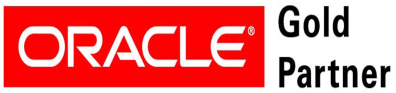

   - None
     CR: PM-2024-168
     Path: D:\internship\rag\images\PM-2024-168   WFM PH2 FO Technical Maintenance BPD (V3.5)_img_2.png


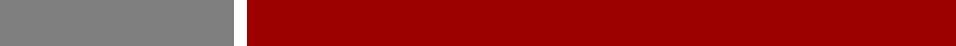

   - None
     CR: PM-2024-168
     Path: D:\internship\rag\images\PM-2024-168   WFM PH2 FO Technical Maintenance BPD (V3.5)_img_5.png


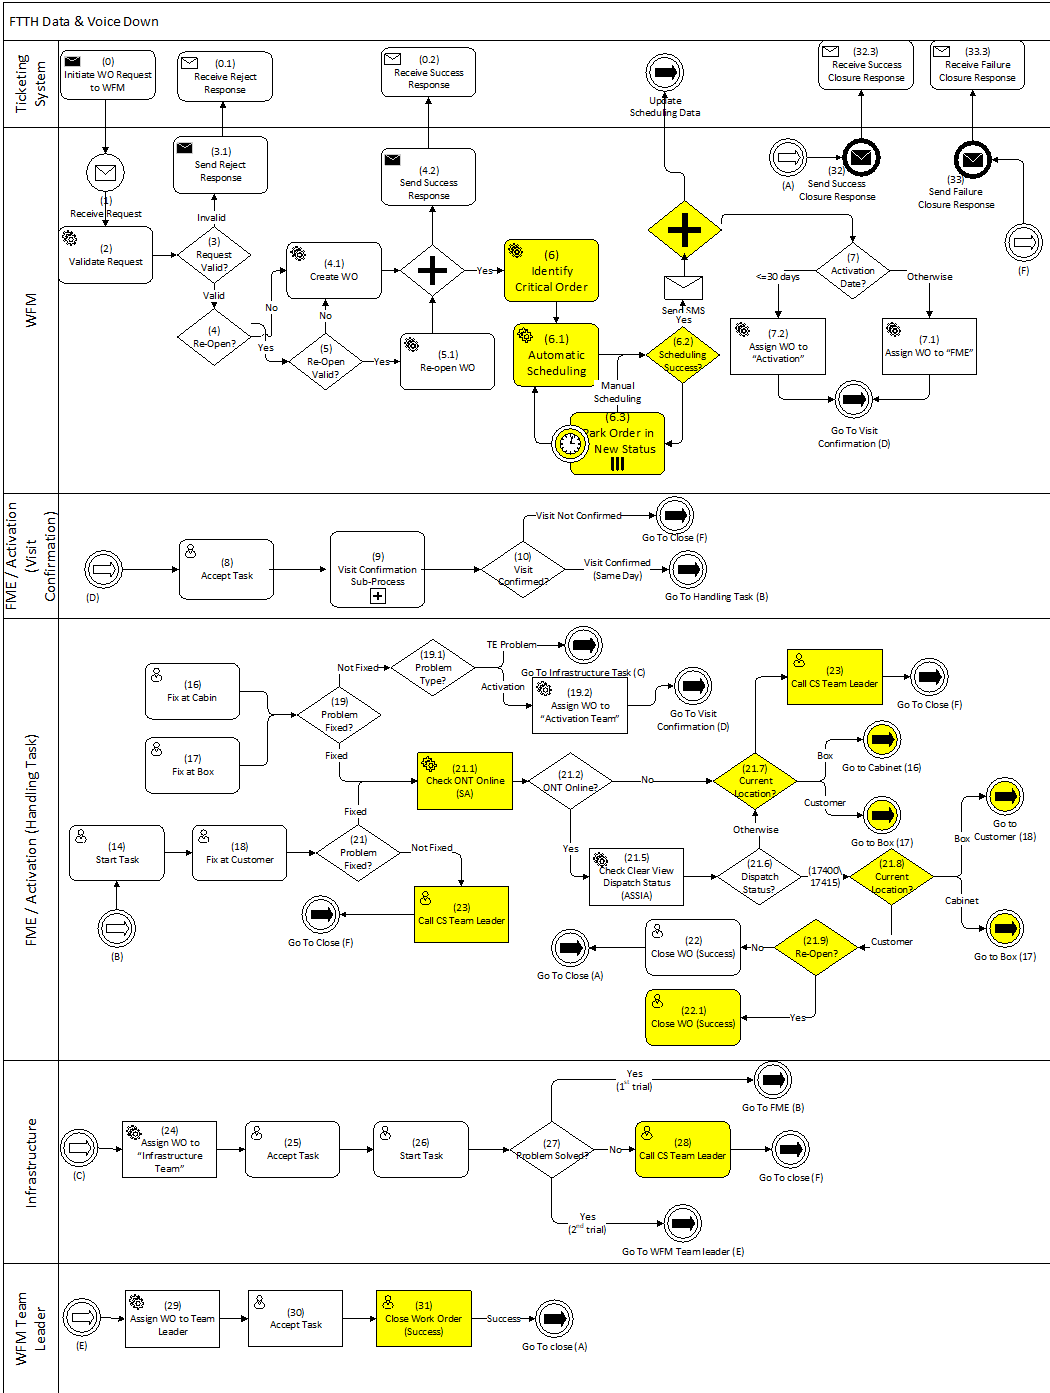


📄 Sources:
   - PM-2024-168   WFM PH2 FO Technical Maintenance BPD (V3.5).do
   - WFM - CS FTTH Maintenance Reporting(V0.5).docx
   - (CR-2025-_222) Technical_Solution for FTTH_Maintenance_Add_N


In [12]:
ask("What is the FTTH maintenance process flow?")

In [15]:
def generate_answer_local(query: str, chunks: list) -> dict:
    
    context     = ""
    image_paths = []
    
    for i, chunk in enumerate(chunks, 1):
        context += f"\n[{i}] {chunk['text'][:500]}\n"
    
    # =============================
    # دور على صور متعلقة
    # =============================
    images_meta_path = os.path.join(
        CONFIG["metadata_path"],
        "images_metadata.json"
    )
    
    if os.path.exists(images_meta_path):
        with open(images_meta_path, "r",
                  encoding="utf-8") as f:
            images_metadata = json.load(f)
        
        # CRs في النتائج
        result_crs = set(
            c["metadata"]["cr_number"]
            for c in chunks
        )
        
        # كلمات من السؤال
        query_keywords = set(query.lower().split())
        
        for img in images_metadata:
            if img.get("cr_number") in result_crs:
                img_path = img.get("image_path", "")
                img_name = img.get("image_name") or \
                           img.get("image_id", "Unknown")
                
                if os.path.exists(img_path):
                    try:
                        from PIL import Image as PILImage
                        with PILImage.open(img_path) as im:
                            w, h = im.size
                            
                            # فلتر:
                            # 1. الصورة كبيرة (Process Flow)
                            # 2. مش مربعة (مش Logo)
                            # 3. Landscape أو Portrait كبير
                            is_large    = w > 500 and h > 500
                            is_not_logo = abs(w-h) > 100
                            is_flow     = w > 800 or h > 800
                            
                            if is_large and (is_not_logo or is_flow):
                                image_paths.append({
                                    "path":     img_path,
                                    "cr":       img.get("cr_number"),
                                    "filename": img_name,
                                    "size":     f"{w}x{h}"
                                })
                    except:
                        pass
    
    # Sort: الأكبر الأول (غالباً Process Flow)
    image_paths.sort(
        key=lambda x: int(x["size"].split("x")[0]),
        reverse=True
    )
    
    # =============================
    # توليد الإجابة
    # =============================
    messages = [
        {
            "role": "system",
            "content": (
                "You are a WFM expert assistant. "
                "Answer based ONLY on the provided context. "
                "Be detailed and complete. "
                "Never repeat the question. "
                "Start your answer directly."
            )
        },
        {
            "role": "user",
            "content": (
                f"Context:\n{context}\n\n"
                f"Question: {query}"
            )
        }
    ]
    
    prompt = generator.tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    
    response = generator(
        prompt,
        max_new_tokens=1000,
        do_sample=False,
        temperature=None,
        top_p=None
    )
    
    full_text = response[0]['generated_text']
    answer    = full_text.split("<|assistant|>")[-1].strip()
    
    return {
        "answer":     answer,
        "images":     image_paths[:2],  # أحسن 2 صور بس
        "num_images": len(image_paths)
    }


def ask(query: str, category: str = None):
    
    chunks = hybrid_search(query, category=category)
    
    print(f"\n🔍 Query: {query}")
    print(f"📚 Context: {len(chunks)} chunks")
    print("\n🤖 Answer:")
    print("=" * 50)
    
    result = generate_answer_local(query, chunks)
    print(result["answer"])
    
    # الصور
    if result["images"]:
        print(f"\n🖼️ Process Flow Diagrams ({result['num_images']} found):")
        from IPython.display import display, Image as IPImage
        for img in result["images"]:
            print(f"\n   📌 CR: {img['cr']}")
            print(f"      Size: {img['size']}")
            try:
                display(IPImage(
                    filename=img['path'],
                    width=600
                ))
            except Exception as e:
                print(f"      ⚠️ {e}")
    else:
        print("\n🖼️ No Process Flow Diagrams found")
    
    # Sources
    print("\n📄 Sources:")
    seen = set()
    for chunk in chunks:
        fname = chunk['metadata']['filename']
        if fname not in seen:
            print(f"   - {fname[:60]}")
            seen.add(fname)

print("✅ Updated ask() جاهز!")

✅ Updated ask() جاهز!



🔍 Query: What is the FTTH maintenance process flow?
📚 Context: 4 chunks

🤖 Answer:


[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


The FTTH maintenance process flow is described in the context of the provided context. The provided context describes the business scope, the scope of the document, and the business process procedures required to automate the FTTH maintenance workforce management processes performed by the FO team. The provided context also includes the business scope, the scope of the document, and the business process procedures required to automate the FTTH maintenance workforce management processes performed by the FO team. The provided context also includes the FTTH maintenance process flow, which is the description of the business process procedures required to automate the FTTH maintenance workforce management processes performed by the FO team.

🖼️ Process Flow Diagrams (5 found):

   📌 CR: CR-2025-222
      Size: 1280x603


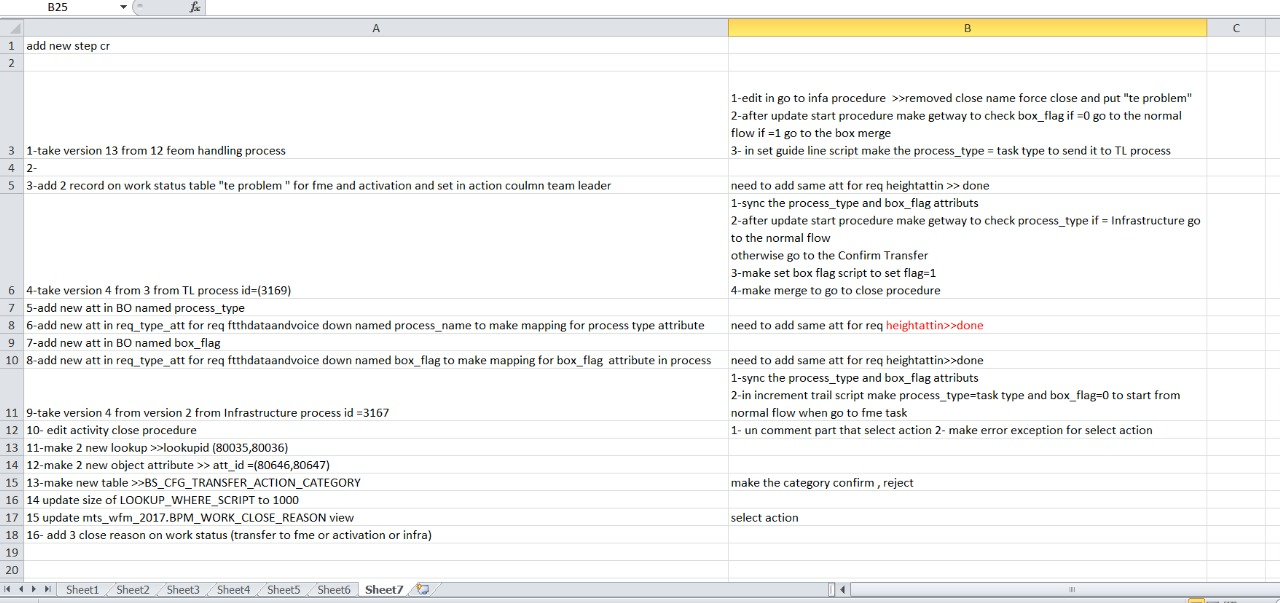


   📌 CR: PM-2024-168
      Size: 1054x1311


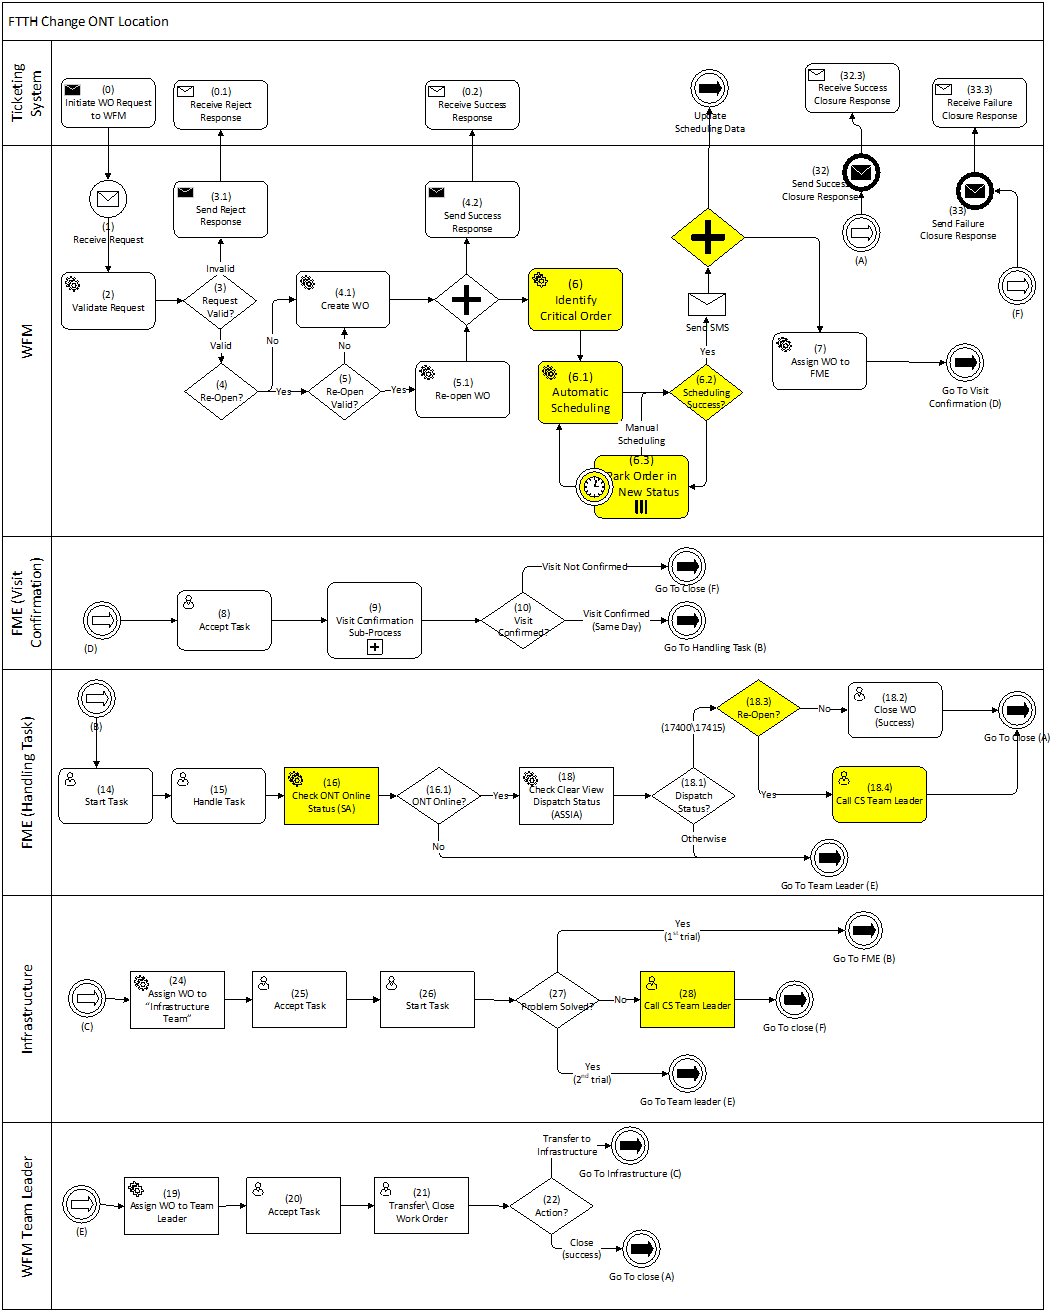


📄 Sources:
   - PM-2024-168   WFM PH2 FO Technical Maintenance BPD (V3.5).do
   - WFM - CS FTTH Maintenance Reporting(V0.5).docx
   - (CR-2025-_222) Technical_Solution for FTTH_Maintenance_Add_N


In [16]:
ask("What is the FTTH maintenance process flow?")

In [17]:
# ============================================
# 🧪 20 Test Questions + Full Evaluation
# ============================================
import time
import numpy as np
import json
import os

test_set = [
    # Scheduling (5 أسئلة)
    {
        "question": "What is the automatic scheduling enhancement?",
        "relevant_crs": ["CR-2025-220"],
        "category": "Scheduling"
    },
    {
        "question": "How does WFM handle no free slots in scheduling?",
        "relevant_crs": ["CR-2025-220"],
        "category": "Scheduling"
    },
    {
        "question": "What are the time slot configuration rules?",
        "relevant_crs": ["CR-2024-152"],
        "category": "Scheduling"
    },
    {
        "question": "How does automatic scheduling work for maintenance orders?",
        "relevant_crs": ["PM-2024-126"],
        "category": "Scheduling"
    },
    {
        "question": "What is the CS scheduling reports amendment?",
        "relevant_crs": ["CR-2024-103"],
        "category": "Scheduling"
    },

    # Maintenance (4 أسئلة)
    {
        "question": "What is the FTTH maintenance process flow?",
        "relevant_crs": ["PM-2024-168"],
        "category": "Maintenance"
    },
    {
        "question": "How to handle ONT status response in FTTH?",
        "relevant_crs": ["PM-2025-225"],
        "category": "Maintenance"
    },
    {
        "question": "What is enterprise maintenance in WFM?",
        "relevant_crs": ["CR-2025-209"],
        "category": "Maintenance"
    },
    {
        "question": "How to remove cabinet task from FME?",
        "relevant_crs": ["PM-2025-216"],
        "category": "Maintenance"
    },

    # Installation (3 أسئلة)
    {
        "question": "What is reserve activation no free port?",
        "relevant_crs": ["CR-2025-226"],
        "category": "Installation"
    },
    {
        "question": "How does FTTH migration work for unreached customers?",
        "relevant_crs": ["PM-2024-173"],
        "category": "Installation"
    },
    {
        "question": "What is the priority flag for installation orders?",
        "relevant_crs": ["CR-2026-251"],
        "category": "Installation"
    },

    # Service Activation (3 أسئلة)
    {
        "question": "How to fix cross connection in WFM?",
        "relevant_crs": ["CR-2024-157"],
        "category": "Service_Activation"
    },
    {
        "question": "What is wrong card and port CR?",
        "relevant_crs": ["CR-2024-166"],
        "category": "Service_Activation"
    },
    {
        "question": "How to remove reservation activity from WFM?",
        "relevant_crs": ["CR-2024-164"],
        "category": "Service_Activation"
    },

    # Dashboard (2 أسئلة)
    {
        "question": "What is KPI report for team leader?",
        "relevant_crs": ["CR-2025-218"],
        "category": "Dashboard_Reports"
    },
    {
        "question": "What is WFM operations monitoring dashboard?",
        "relevant_crs": ["CR-2024-131"],
        "category": "Dashboard_Reports"
    },

    # Work Orders (2 أسئلة)
    {
        "question": "What is force close work order in customer care portal?",
        "relevant_crs": ["CR-2023-83"],
        "category": "Work_Orders"
    },
    {
        "question": "How to add temp assigned serials to pending tasks?",
        "relevant_crs": ["CR-2025-228"],
        "category": "Work_Orders"
    },

    # User Management (1 سؤال)
    {
        "question": "What is desktop users login modification?",
        "relevant_crs": ["CR-2023-76"],
        "category": "User_Management"
    },
]

# ============================================
# 📊 Full Evaluation
# ============================================
os.makedirs("evaluation", exist_ok=True)

def full_evaluation(test_set, k=5):
    
    retrieval_results = []
    answer_results    = []
    
    print("🚀 Starting Full Evaluation...")
    print(f"📊 Total Questions: {len(test_set)}")
    print("=" * 60)
    
    for i, test in enumerate(test_set):
        
        query    = test["question"]
        relevant = test["relevant_crs"]
        category = test["category"]
        
        print(f"\n[{i+1}/{len(test_set)}] {query[:55]}")
        print(f"   Category: {category}")
        
        # =============================
        # Retrieval Evaluation
        # =============================
        ret_start = time.time()
        chunks    = hybrid_search(
            query, 
            top_k=k,
            category=category
        )
        ret_end   = time.time()
        ret_lat   = ret_end - ret_start
        
        retrieved_crs = [
            c["metadata"]["cr_number"]
            for c in chunks
        ]
        
        # Recall@k
        hits      = sum(1 for r in relevant if r in retrieved_crs)
        recall    = hits / len(relevant)
        
        # Precision@k
        precision = hits / k if k > 0 else 0
        
        # MRR
        mrr = 0
        for rank, cr in enumerate(retrieved_crs, 1):
            if cr in relevant:
                mrr = 1 / rank
                break
        
        retrieval_results.append({
            "question":    query,
            "category":    category,
            "recall":      round(recall, 3),
            "precision":   round(precision, 3),
            "mrr":         round(mrr, 3),
            "latency":     round(ret_lat, 3),
            "retrieved":   retrieved_crs,
            "relevant":    relevant
        })
        
        print(f"   Recall@{k}: {recall:.2f} | "
              f"Precision: {precision:.2f} | "
              f"MRR: {mrr:.2f} | "
              f"Lat: {ret_lat:.2f}s")
        
        # =============================
        # Answer Evaluation
        # =============================
        ans_start = time.time()
        result    = generate_answer_local(query, chunks)
        ans_end   = time.time()
        ans_lat   = ans_end - ans_start
        
        answer = result["answer"]
        
        # Faithfulness
        context_words  = set(
            " ".join([c["text"] for c in chunks])
            .lower().split()
        )
        answer_words   = set(answer.lower().split())
        common         = context_words & answer_words
        faithfulness   = min(
            len(common) / max(len(answer_words), 1), 
            1.0
        )
        
        # Relevance
        query_words  = set(query.lower().split())
        relevance    = min(
            len(query_words & answer_words) / 
            max(len(query_words), 1),
            1.0
        )
        
        answer_results.append({
            "question":     query,
            "category":     category,
            "answer":       answer[:300],
            "faithfulness": round(faithfulness, 3),
            "relevance":    round(relevance, 3),
            "latency":      round(ans_lat, 3),
            "num_images":   result["num_images"]
        })
        
        print(f"   Faith: {faithfulness:.2f} | "
              f"Rel: {relevance:.2f} | "
              f"Lat: {ans_lat:.2f}s | "
              f"Imgs: {result['num_images']}")
    
    # =============================
    # Final Summary
    # =============================
    print("\n" + "=" * 60)
    print("📊 FINAL EVALUATION RESULTS")
    print("=" * 60)
    
    # Retrieval Averages
    avg_recall    = np.mean([r["recall"]    for r in retrieval_results])
    avg_precision = np.mean([r["precision"] for r in retrieval_results])
    avg_mrr       = np.mean([r["mrr"]       for r in retrieval_results])
    avg_ret_lat   = np.mean([r["latency"]   for r in retrieval_results])
    
    # Answer Averages
    avg_faith     = np.mean([r["faithfulness"] for r in answer_results])
    avg_rel       = np.mean([r["relevance"]    for r in answer_results])
    avg_ans_lat   = np.mean([r["latency"]      for r in answer_results])
    
    print(f"\n🔍 RETRIEVAL QUALITY (k={k}):")
    print(f"   Recall@{k}:    {avg_recall:.3f}")
    print(f"   Precision@{k}: {avg_precision:.3f}")
    print(f"   MRR:           {avg_mrr:.3f}")
    print(f"   Avg Latency:   {avg_ret_lat:.3f}s")
    
    print(f"\n🤖 ANSWER QUALITY:")
    print(f"   Faithfulness:  {avg_faith:.3f}")
    print(f"   Relevance:     {avg_rel:.3f}")
    print(f"   Avg Latency:   {avg_ans_lat:.3f}s")
    
    # By Category
    print(f"\n📁 BY CATEGORY (Recall@{k}):")
    categories = set(r["category"] for r in retrieval_results)
    for cat in sorted(categories):
        cat_results = [
            r for r in retrieval_results 
            if r["category"] == cat
        ]
        cat_recall = np.mean([r["recall"] for r in cat_results])
        cat_mrr    = np.mean([r["mrr"]    for r in cat_results])
        print(f"   {cat:<25} Recall: {cat_recall:.2f} | MRR: {cat_mrr:.2f}")
    
    # حفظ النتائج
    final = {
        "summary": {
            "total_questions": len(test_set),
            "k": k,
            "retrieval": {
                "recall":    round(avg_recall, 3),
                "precision": round(avg_precision, 3),
                "mrr":       round(avg_mrr, 3),
                "latency":   round(avg_ret_lat, 3)
            },
            "answer_quality": {
                "faithfulness": round(avg_faith, 3),
                "relevance":    round(avg_rel, 3),
                "latency":      round(avg_ans_lat, 3)
            }
        },
        "retrieval_details": retrieval_results,
        "answer_details":    answer_results
    }
    
    with open("evaluation/full_evaluation.json", "w",
              encoding="utf-8") as f:
        json.dump(final, f, ensure_ascii=False, indent=2)
    
    print("\n✅ Results saved in evaluation/full_evaluation.json")
    return final


# شغّل الـ Evaluation
eval_final = full_evaluation(test_set, k=5)

🚀 Starting Full Evaluation...
📊 Total Questions: 20

[1/20] What is the automatic scheduling enhancement?
   Category: Scheduling
   Recall@5: 1.00 | Precision: 0.20 | MRR: 0.50 | Lat: 6.73s


[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


   Faith: 0.60 | Rel: 0.67 | Lat: 377.52s | Imgs: 4

[2/20] How does WFM handle no free slots in scheduling?
   Category: Scheduling


[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


   Recall@5: 1.00 | Precision: 0.20 | MRR: 0.50 | Lat: 0.87s
   Faith: 0.89 | Rel: 0.67 | Lat: 74.86s | Imgs: 4

[3/20] What are the time slot configuration rules?
   Category: Scheduling


[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


... (29 outputs left out)

[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


   Faith: 0.24 | Rel: 0.75 | Lat: 337.21s | Imgs: 0

[20/20] What is desktop users login modification?
   Category: User_Management


[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


   Recall@5: 1.00 | Precision: 0.20 | MRR: 1.00 | Lat: 0.33s
   Faith: 0.74 | Rel: 1.00 | Lat: 67.30s | Imgs: 0

📊 FINAL EVALUATION RESULTS

🔍 RETRIEVAL QUALITY (k=5):
   Recall@5:    0.800
   Precision@5: 0.160
   MRR:           0.667
   Avg Latency:   0.647s

🤖 ANSWER QUALITY:
   Faithfulness:  0.630
   Relevance:     0.686
   Avg Latency:   142.076s

📁 BY CATEGORY (Recall@5):
   Dashboard_Reports         Recall: 1.00 | MRR: 1.00
   Installation              Recall: 1.00 | MRR: 0.83
   Maintenance               Recall: 0.75 | MRR: 0.75
   Scheduling                Recall: 1.00 | MRR: 0.67
   Service_Activation        Recall: 0.33 | MRR: 0.33
   User_Management           Recall: 1.00 | MRR: 1.00
   Work_Orders               Recall: 0.50 | MRR: 0.25

✅ Results saved in evaluation/full_evaluation.json


🚀 Starting Full Evaluation...
📊 Total Questions: 20

[1/20] What is the automatic scheduling enhancement?
Category: Scheduling

📊 Retrieval Metrics:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        0.50
   Latency:    4.20s

🤖 Answer:
----------------------------------------


[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


The automatic scheduling enhancement is described in the context of automatic scheduling for FO FTTH installation and FO maintenance. It involves selecting the first available time interval with free time slots in the next X days, regardless of whether this free time slot is within the X days window or beyond it. The automatic scheduling ensures that the first available time interval is used for scheduling, regardless of the configuration of the X days window. The automatic scheduling is performed according to the following rules:

1. If the order is created on a Sunday and the number of days is configured to 3, automatic scheduling can only assign scheduling date in the next 3 days (Monday, Tuesday, or Wednesday).

2. If the order is created on a Monday and the number of days is configured to 3, automatic scheduling can only assign scheduling date in the next 3 days (Monday, Tuesday, or Wednesday).

3. If the order is created on a Tuesday and the number of days is configured to 3, aut

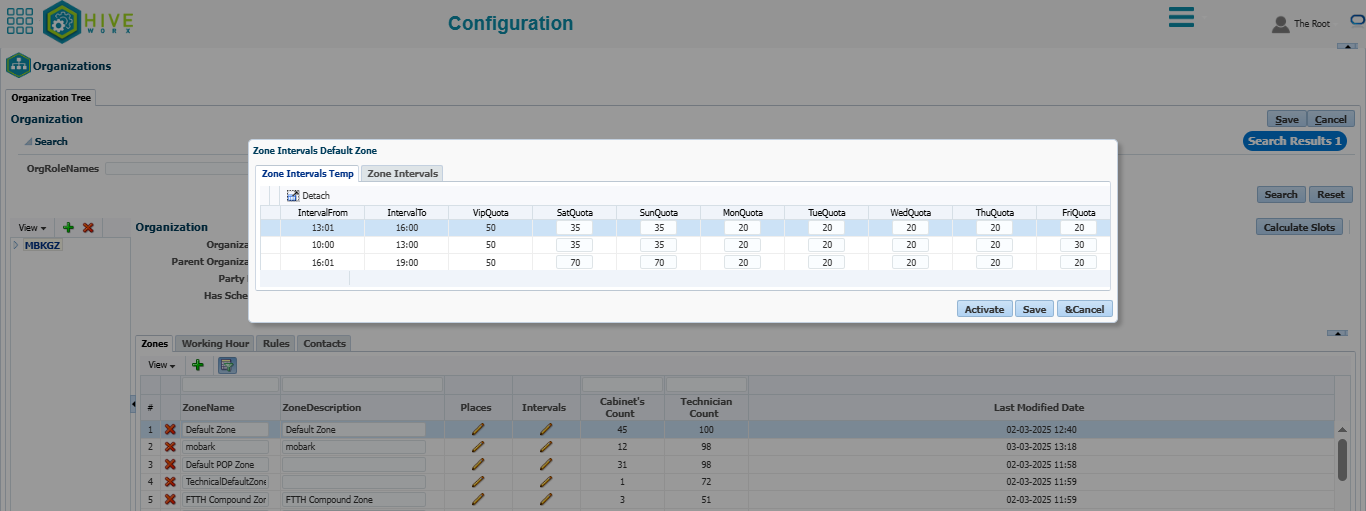

   CR: CR-2025-220 | Size: 1148x602


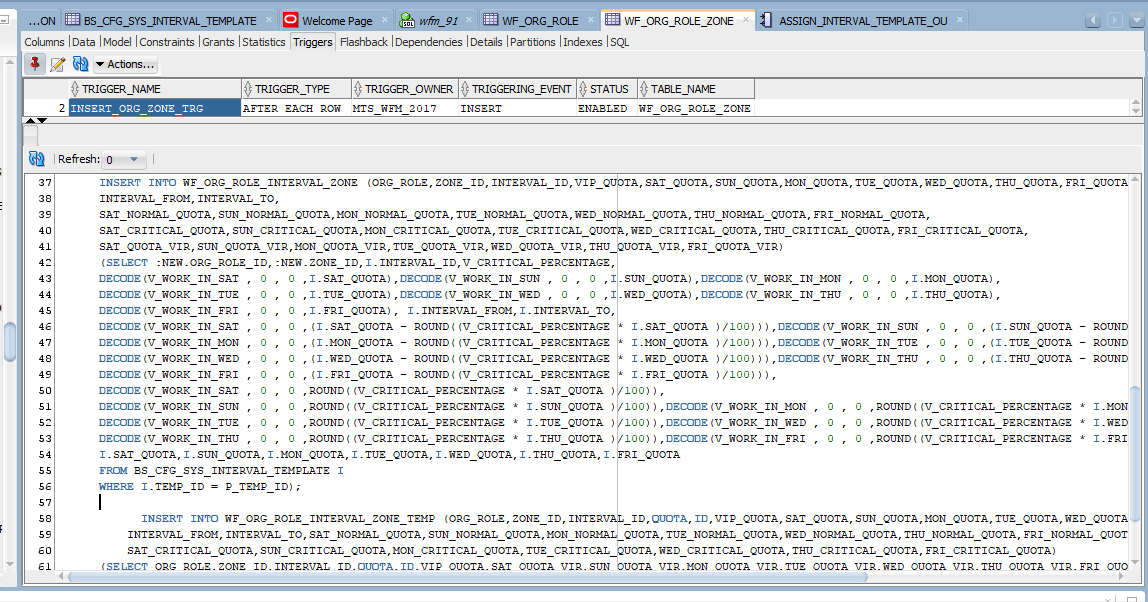


📄 Sources:
   - (CR-2024-152)WFM FO Scheduling - Modify Time Intervals Confi
   - (CR-2025-220)WFM Automatic Scheduling Enhancement CR (V0.2).
   - (PM-2024-126)WFM Scheduling Portal - FO Maintenance FRS (V0.

[2/20] How does WFM handle no free slots in scheduling?
Category: Scheduling

📊 Retrieval Metrics:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        0.50
   Latency:    3.11s

🤖 Answer:
----------------------------------------


[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


To handle no free slots in scheduling, WFM configures a percentage of slots reserved per each organization unit/zone for critical orders. These slots are reserved based on the configured percentage of slots for critical orders. If no free normal slots are available, WFM searches for free critical slots in the next time interval and continues searching with the same sequence in time intervals for the configured X days. If no critical slots are available, WFM will not validate slot availability and will not schedule the visit. Users can only manually schedule a visit in the next 3 days.

📊 Answer Metrics:
   Faithfulness: 0.89
   Relevance:    0.67
   Latency:      76.08s

🖼️ Related Images (4 found):
   CR: CR-2025-220 | Size: 1366x511


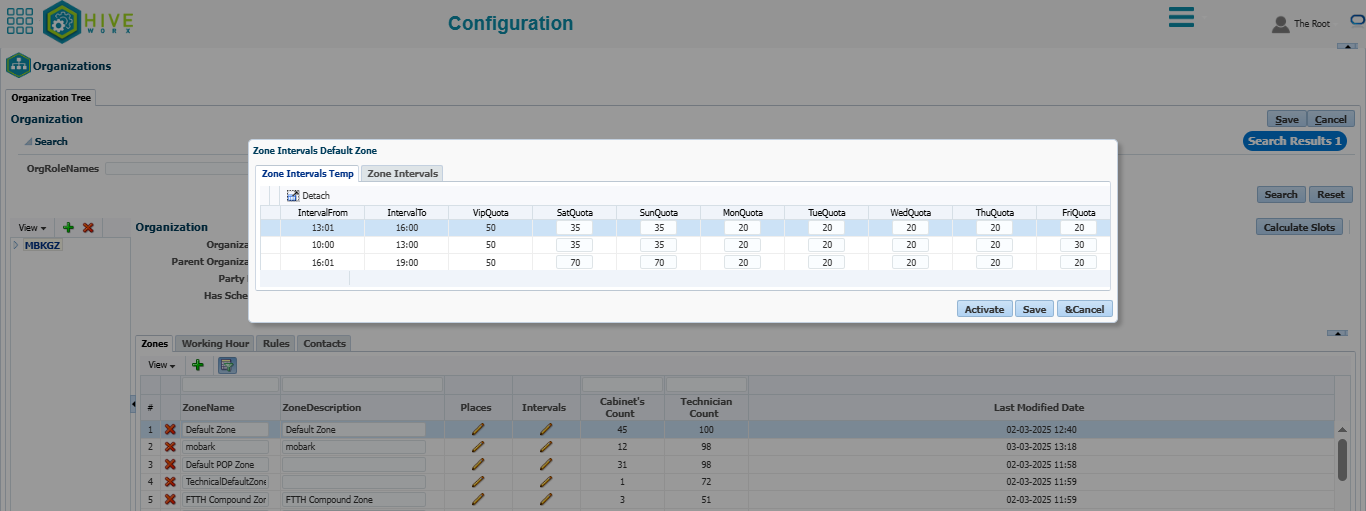

   CR: CR-2025-220 | Size: 1148x602


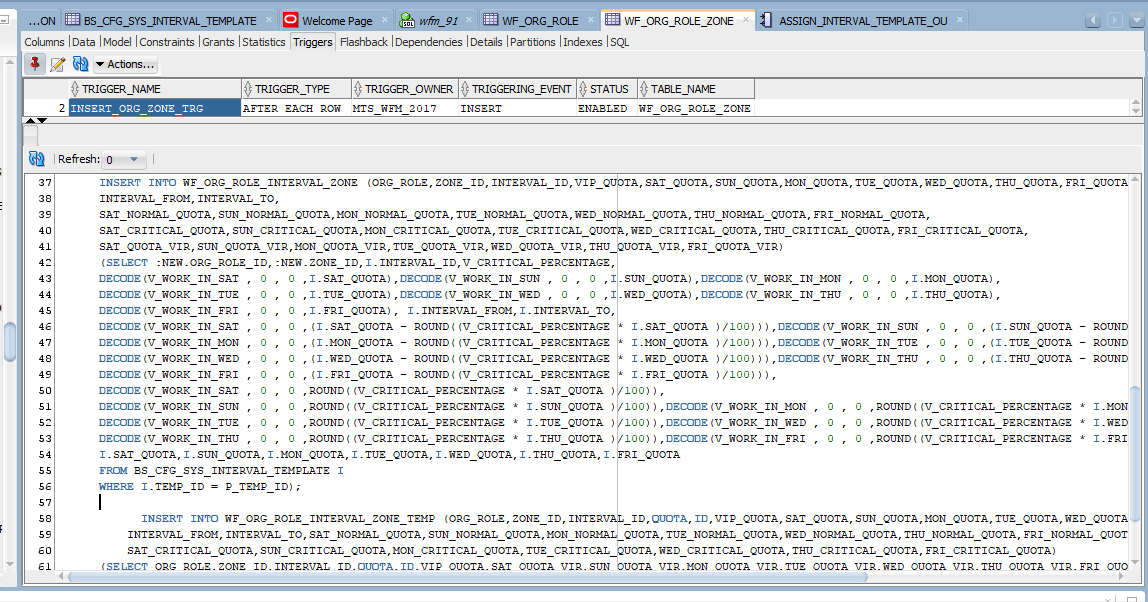


📄 Sources:
   - (PM-2024-126)WFM Scheduling Portal - FO Maintenance FRS (V0.
   - (CR-2025-220)WFM Automatic Scheduling Enhancement CR (V0.2).

[3/20] What are the time slot configuration rules?
Category: Scheduling


[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



📊 Retrieval Metrics:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        1.00
   Latency:    0.32s

🤖 Answer:
----------------------------------------
The provided context mentions that the current behavior involves the following time slot configuration:

- Four time slots (10:12 - 12:2 - 2:4 - 4:6)
- Split configuring time slots permission to 2 separate permissions: Increase time slots and Decrease time slots.
- User should have both permissions to be able to increase and decrease time slots.

📊 Answer Metrics:
   Faithfulness: 0.84
   Relevance:    0.43
   Latency:      54.74s

🖼️ Related Images (1 found):
   CR: PM-2024-126 | Size: 1080x543


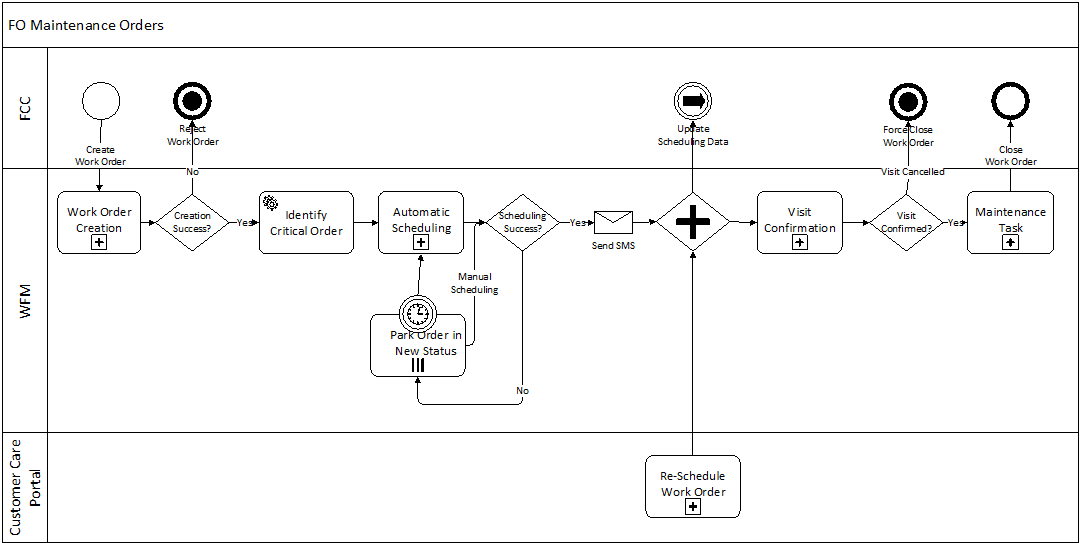

[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



📄 Sources:
   - (CR-2024-152)WFM FO Scheduling - Modify Time Intervals Confi
   - (PM-2024-126)WFM Scheduling Portal - FO Maintenance FRS (V0.

[4/20] How does automatic scheduling work for maintenance orders?
Category: Scheduling

📊 Retrieval Metrics:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        1.00
   Latency:    0.07s

🤖 Answer:
----------------------------------------
Automatic scheduling works by applying scheduling rules to FO maintenance orders based on the business flow required to automate the scheduling process. The following are the components and business flow required to automate the scheduling process:

1. Data & Voice Down: This component is responsible for receiving and processing data from the customer's end.

2. Data Down: This component is responsible for receiving and processing data from the customer's end.

3. WFM Visit Confirmation Process: This component is responsible for confirming the visit and scheduling the work order.

4. External Scheduling Por

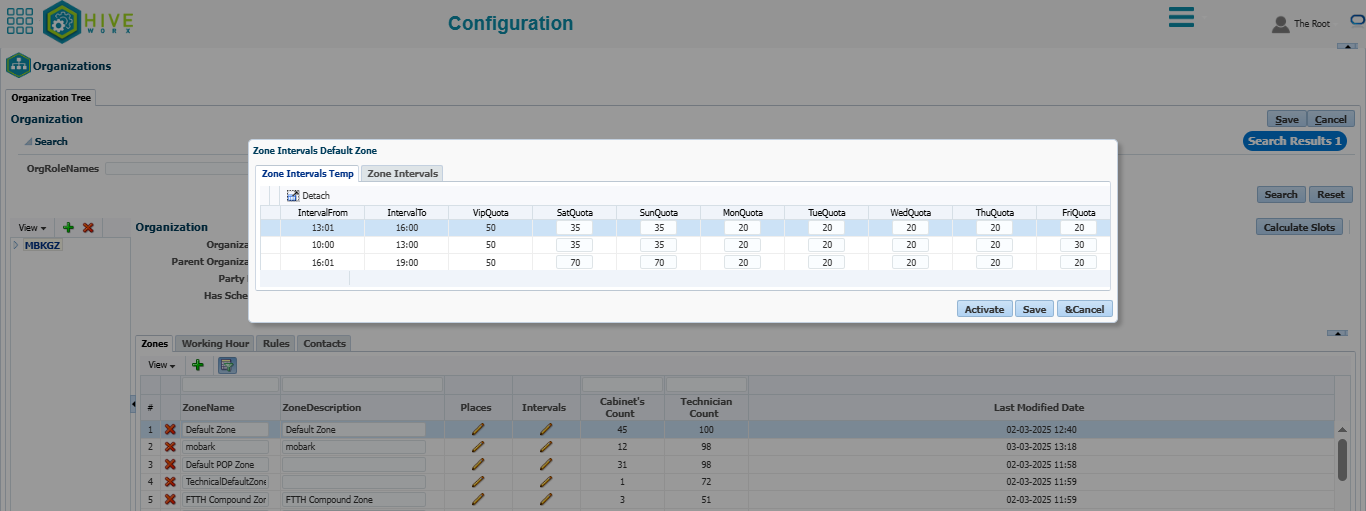

   CR: CR-2025-220 | Size: 1148x602


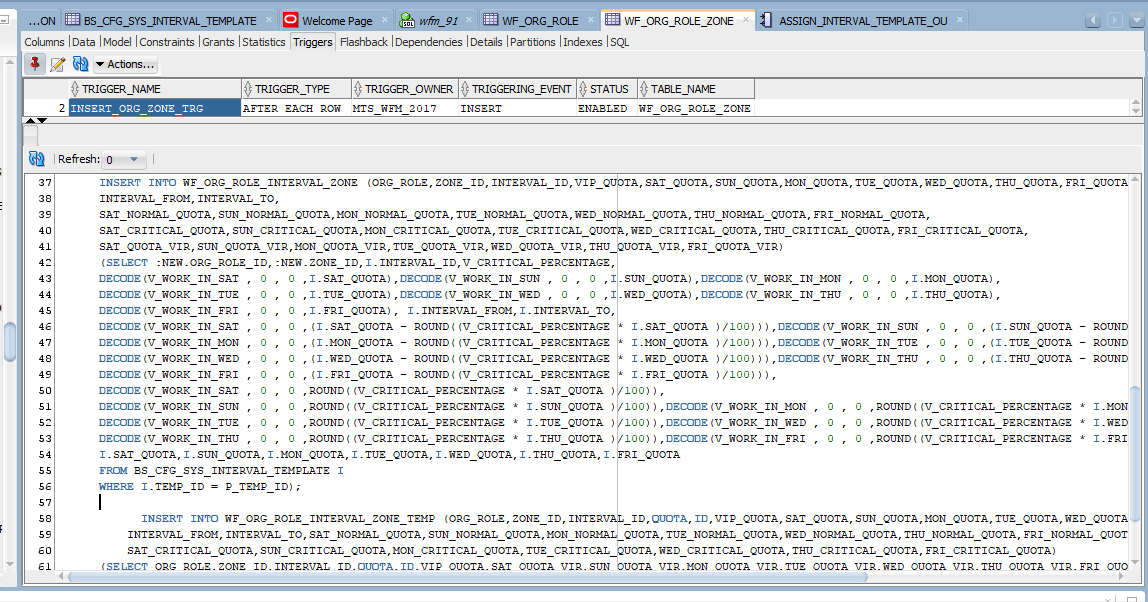


📄 Sources:
   - (PM-2024-126)WFM Scheduling Portal - FO Maintenance FRS (V0.
   - CR-2025-229 WFM Automatic Scheduling Enhancement CR Amendmen
   - (CR-2025-220)WFM Automatic Scheduling Enhancement CR (V0.2).

[5/20] What is the CS scheduling reports amendment?
Category: Scheduling

📊 Retrieval Metrics:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        0.33
   Latency:    0.34s

🤖 Answer:
----------------------------------------


[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


The CS scheduling reports amendment is to modify the input parameters for the Scheduling Logs Report, Work Order Details Report, and Introduction reports to include the creation date and schedule date ranges. The original scheduling time interval will be held in the original scheduled time interval parameter, while the first scheduled time interval will be held in the scheduled time interval parameter. The report is added successfully with all filtering criteria, and the data appears within the specified range correctly. Test procedures are performed to ensure that all orders in progress before the slot end time are included in the report, their scheduling status is "within schedule," and rescheduling by is added to the report. Test data is provided to ensure that the end to end time, handling time, and rescheduled by are added to the report. The objective is to add end to end time, handling time, and rescheduled by to the report. The end to end time, handling time, and rescheduled by 

[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


The FTTH maintenance process flow is described in the context of the provided context. The provided context describes the business scope, the scope of the document, and the business process procedures required to automate the FTTH maintenance workforce management processes performed by the FO team. The provided context also includes the business scope, the scope of the document, and the business process procedures required to automate the FTTH maintenance workforce management processes performed by the FO team. The provided context also includes the FTTH maintenance process flow, which is the description of the business process procedures required to automate the FTTH maintenance workforce management processes performed by the FO team.

📊 Answer Metrics:
   Faithfulness: 0.62
   Relevance:    0.71
   Latency:      64.34s

🖼️ Related Images (5 found):
   CR: CR-2025-222 | Size: 1280x603


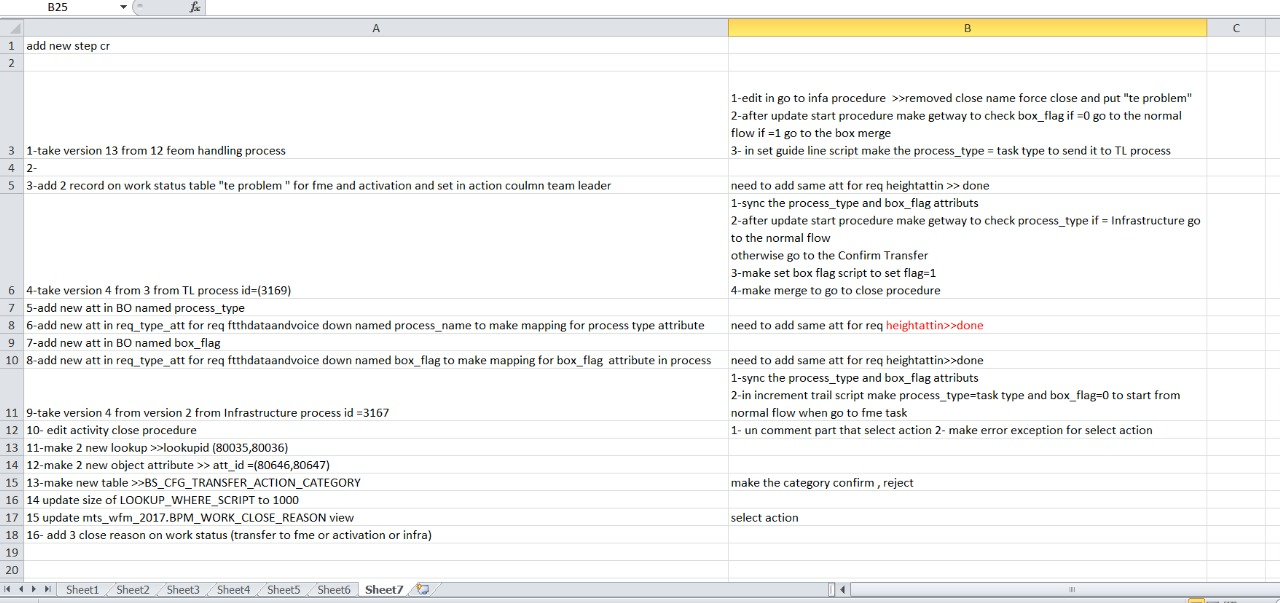

   CR: PM-2024-168 | Size: 1054x1311


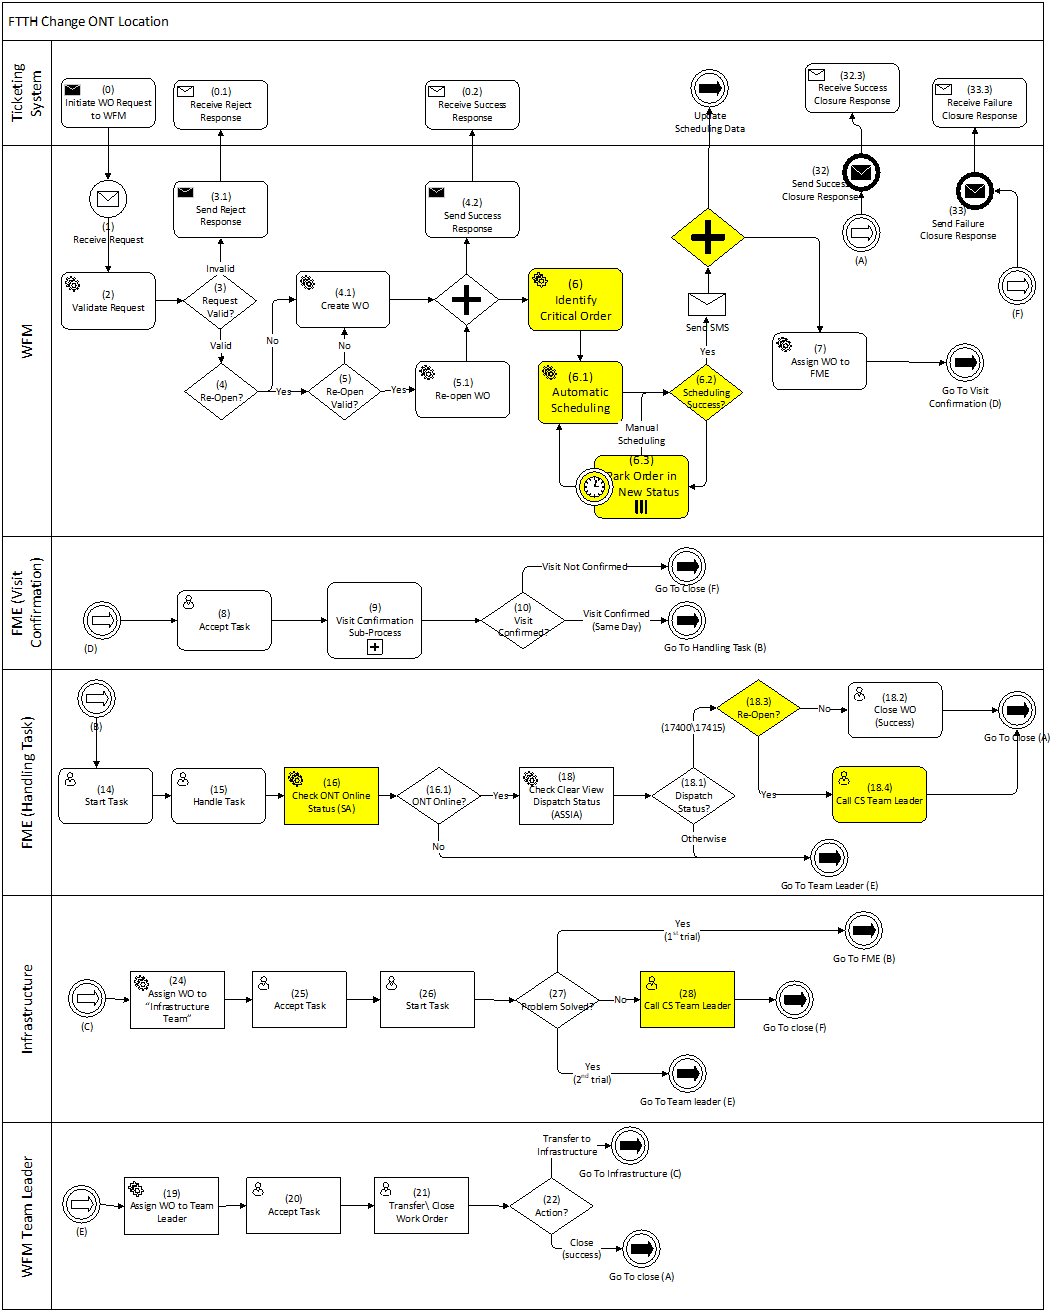


📄 Sources:
   - PM-2024-168   WFM PH2 FO Technical Maintenance BPD (V3.5).do
   - WFM - CS FTTH Maintenance Reporting(V0.5).docx
   - (CR-2025-_222) Technical_Solution for FTTH_Maintenance_Add_N

[7/20] How to handle ONT status response in FTTH?
Category: Maintenance


[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



📊 Retrieval Metrics:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        1.00
   Latency:    0.44s

🤖 Answer:
----------------------------------------
To handle ONT status response in FTTH, you can modify the FTTH ONT Status integration to handle vendor-specific responses for defining ONT status based on "MSAN Vendor ID" attribute. Here's how:

1. Description:

Modify the FTTH ONT Status integration to handle vendor-specific responses for defining ONT status based on "MSAN Vendor ID" attribute.

2. Introduction:

Modify the FTTH Services ATPs Represented by: Software Quality Control | Ver # | Implemented By | Revision Date | Approved By | Approval Date | Reason |

3. Objective:

To verify that the WFM Team Leader must explicitly ACCEPT the Transfer to Infrastructure when an FME tas

4. Introduction:

code. The activation Click on (Submit) Button.

5. Test Procedures:

The FME choose (Is Problem Fixed = Problem Fixed). The FME Click on “Submit” Button. Refresh the form.

6. Call ONT 

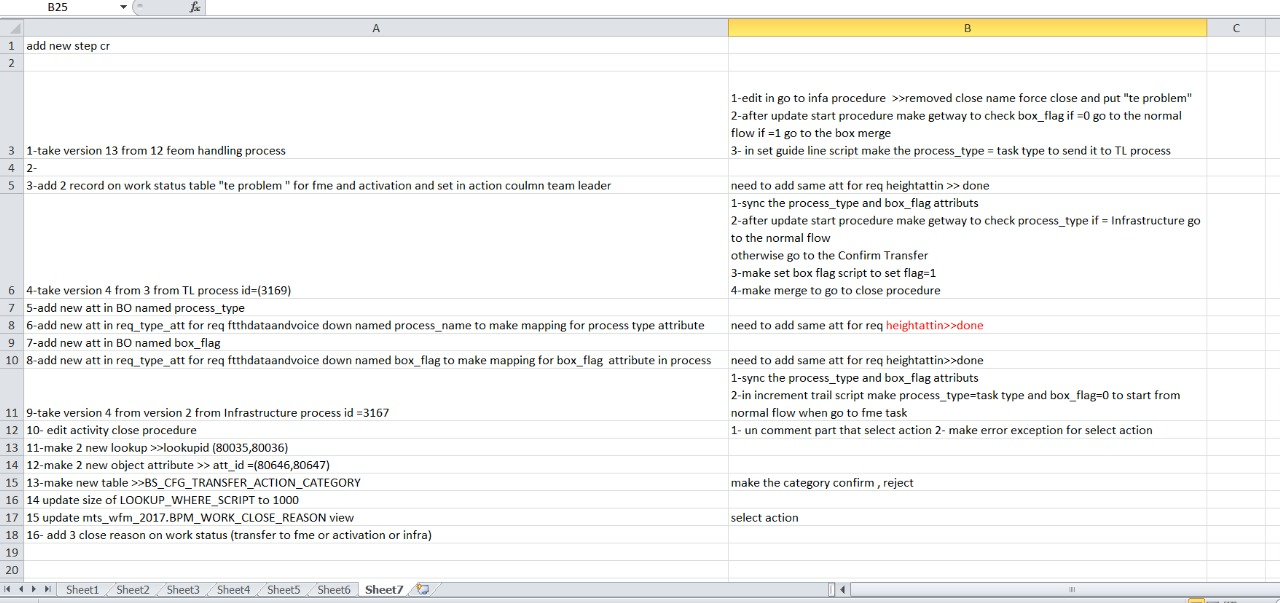

   CR: CR-2025-222 | Size: 1050x1503


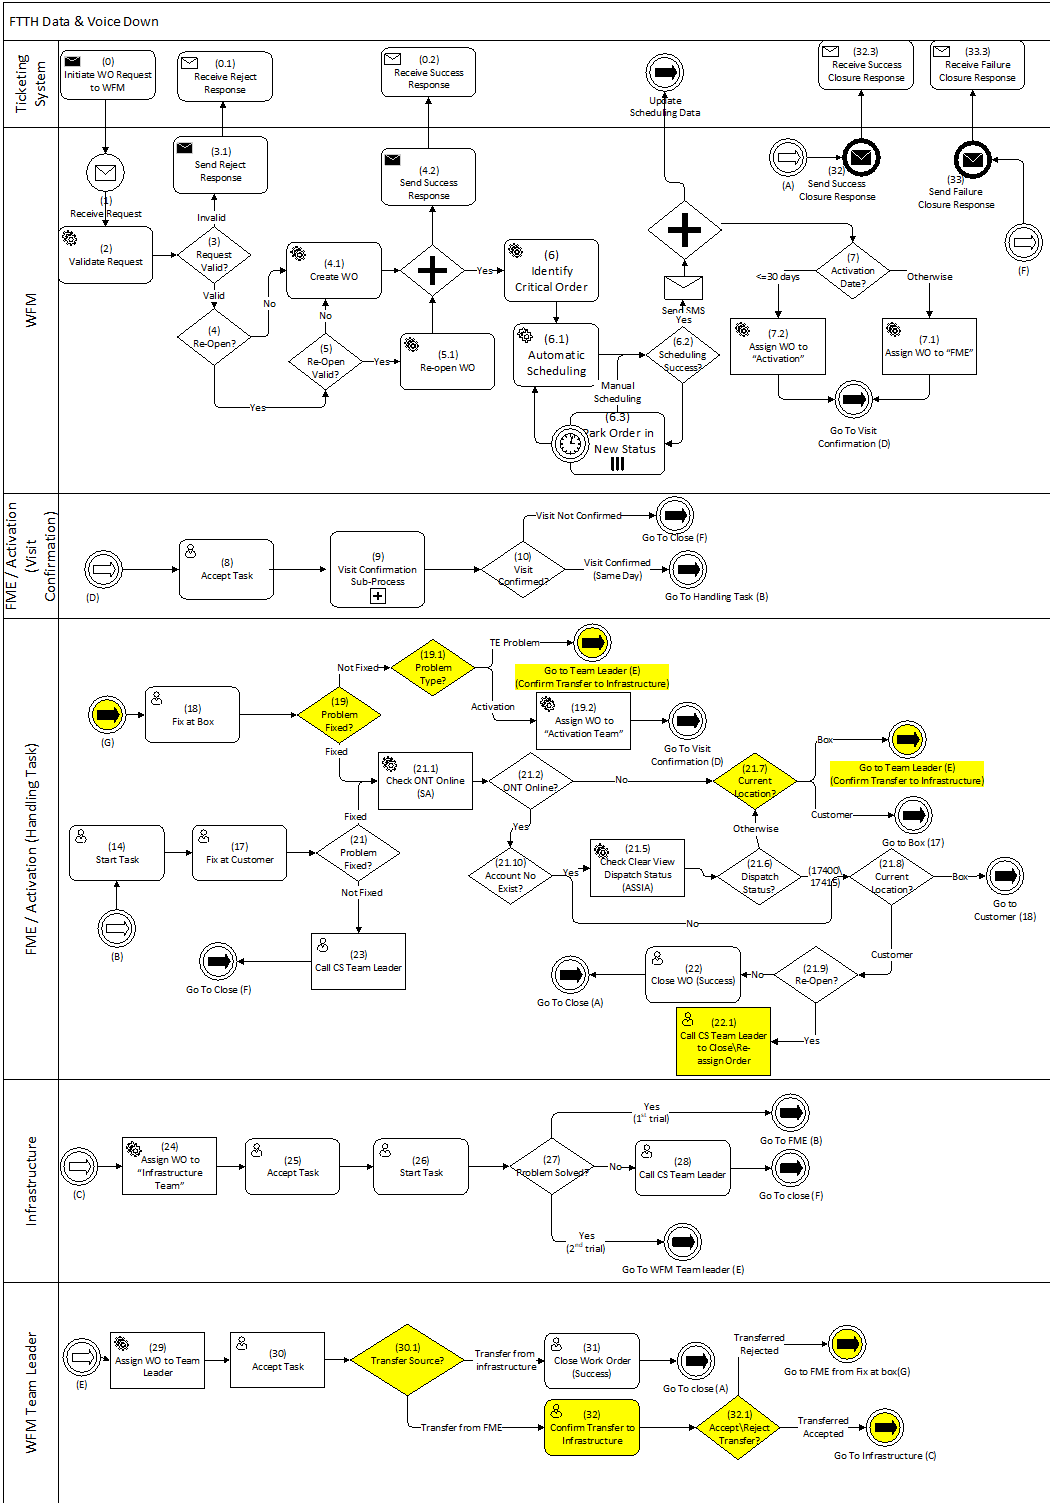


📄 Sources:
   - (PM-2025-225) FTTH_Maintenance_-Handle_ONT_Status_Response_(
   - (CR-2025-_222)_FTTH_Maintenance_-_Add_New_step_On_WFM_Workfl

[8/20] What is enterprise maintenance in WFM?
Category: Maintenance

📊 Retrieval Metrics:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        1.00
   Latency:    0.11s

🤖 Answer:
----------------------------------------


[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Question: What is the context of the provided context?

Answer: The provided context is a WFM Enterprise Maintenance ATPs WFM Project - Phase Represented by: Software Quality Control.

Question: What is the introduction to the amendment on "WFM PH2 FO Technical Maintenance BPD (V0.13)"?

Answer: The introduction to the amendment on "WFM PH2 FO Technical Maintenance BPD (V0.13)" is an amendment on "WFM PH2 FO Technical Maintenance BPD (V0.13)" intended to describe WFM workflows for maintenance technical visits in the scope of FO team.

Question: What is the introduction to the amendment on "Technical Solution FTTH Maintenance - Add New step On WFM Workflow (CR-2025- 222)"?

Answer: The introduction to the amendment on "Technical Solution FTTH Maintenance - Add New step On WFM Workflow (CR-2025- 222)" is an amendment on "Technical Solution FTTH Maintenance - Add New step On WFM Workflow (CR-2025- 222)" intended to describe a new step on the WFM workflow for technical visits in the scope 

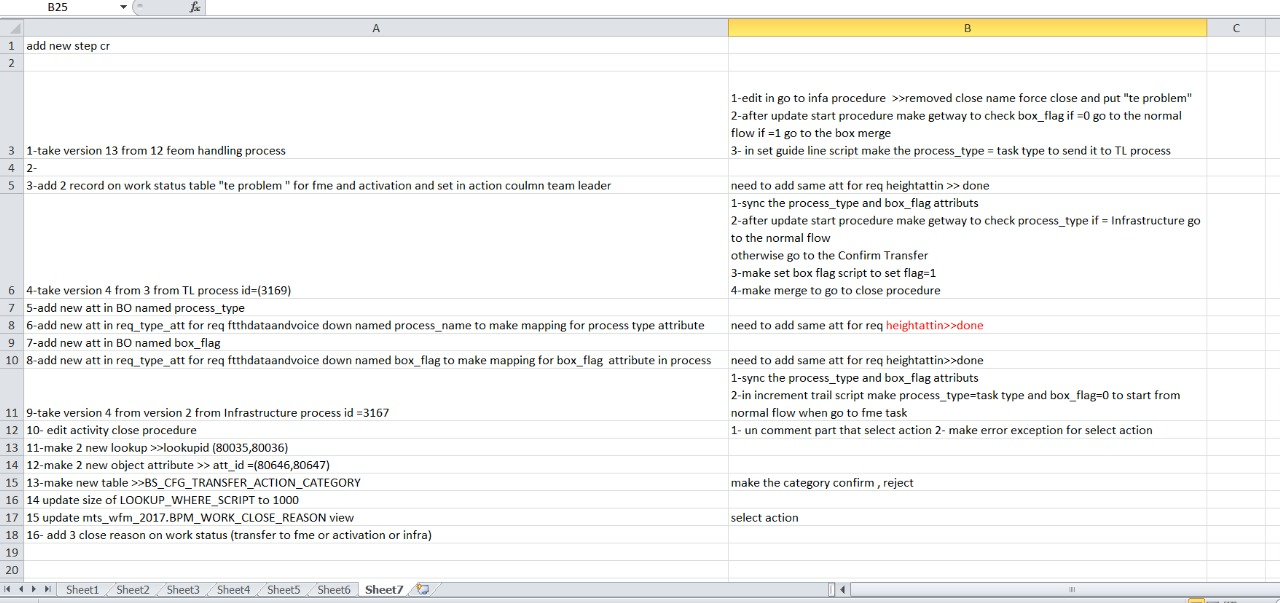

   CR: PM-2024-168 | Size: 1054x1311


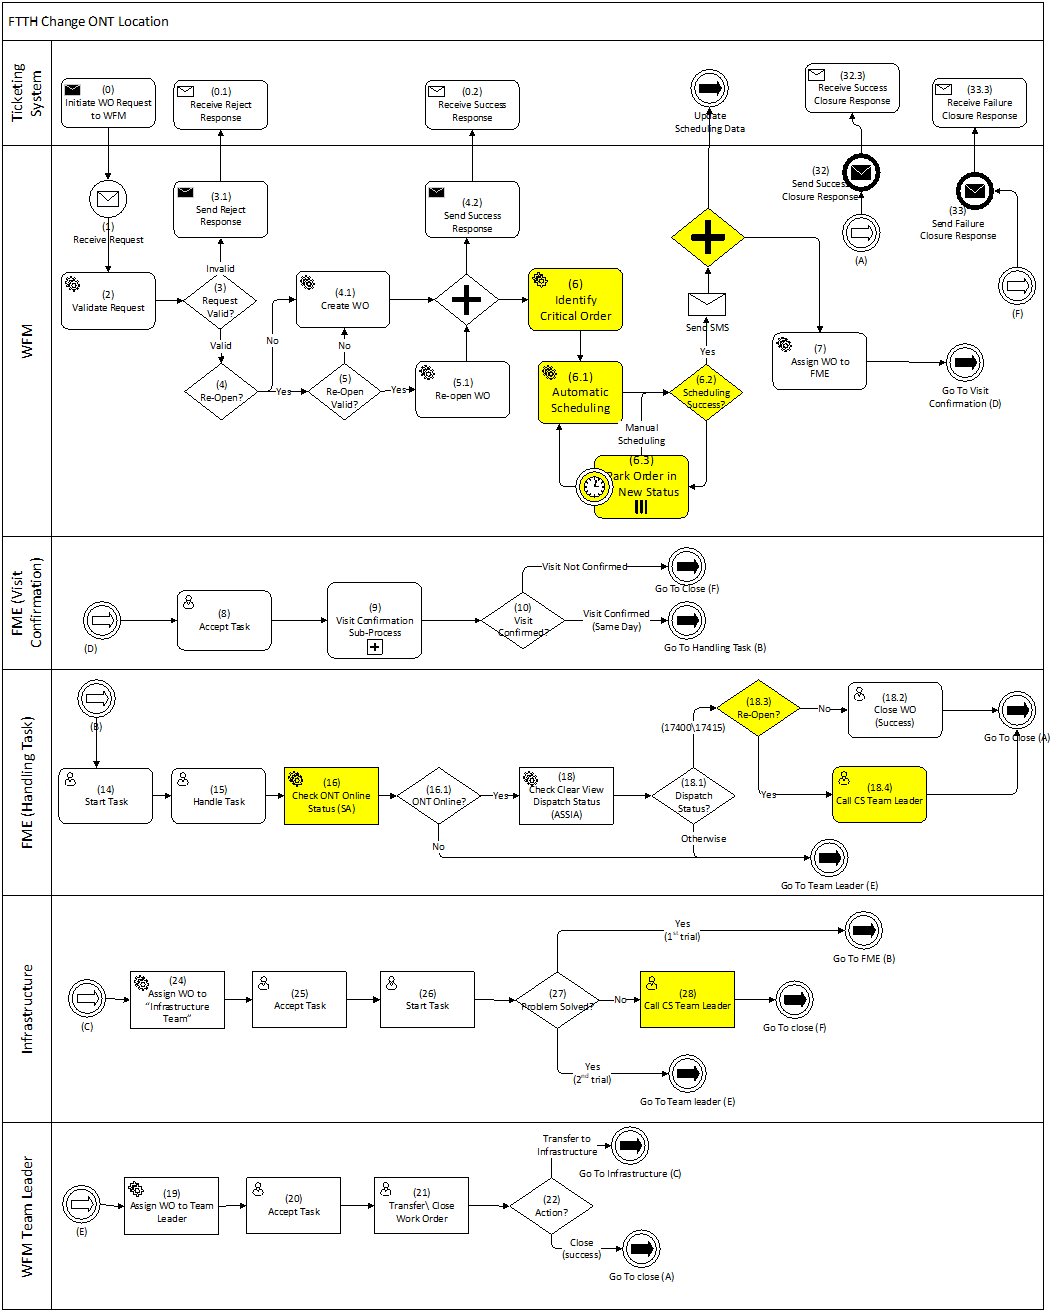


📄 Sources:
   - WFM - Enterprise Maintenance ATPs (1.0).docx
   - PM-2024-168   WFM PH2 FO Technical Maintenance BPD (V3.5).do
   - (CR-2025-_222) Technical_Solution for FTTH_Maintenance_Add_N

[9/20] How to remove cabinet task from FME?
Category: Maintenance


[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



📊 Retrieval Metrics:
   Recall@5:  0.00
   Precision:  0.00
   MRR:        0.00
   Latency:    0.38s

🤖 Answer:
----------------------------------------
To remove a cabinet task from the FME, follow these steps:

1. Navigate to the FME's account in the FME Navigator.
2. Click on the "My Tasks" tab to view all the tasks assigned to the FME.
3. Locate the cabinet task that you want to remove.
4. Click on the "Edit" button next to the cabinet task.
5. In the "Edit" dialog box, select the "Remove" option from the dropdown menu.
6. Confirm the removal by clicking on the "Remove" button.
7. The cabinet task will be removed from the FME's task list.

Note: Make sure to save your changes before proceeding to the next step.

📊 Answer Metrics:
   Faithfulness: 0.26
   Relevance:    0.71
   Latency:      64.21s

🖼️ Related Images (3 found):
   CR: CR-2025-222 | Size: 1280x603


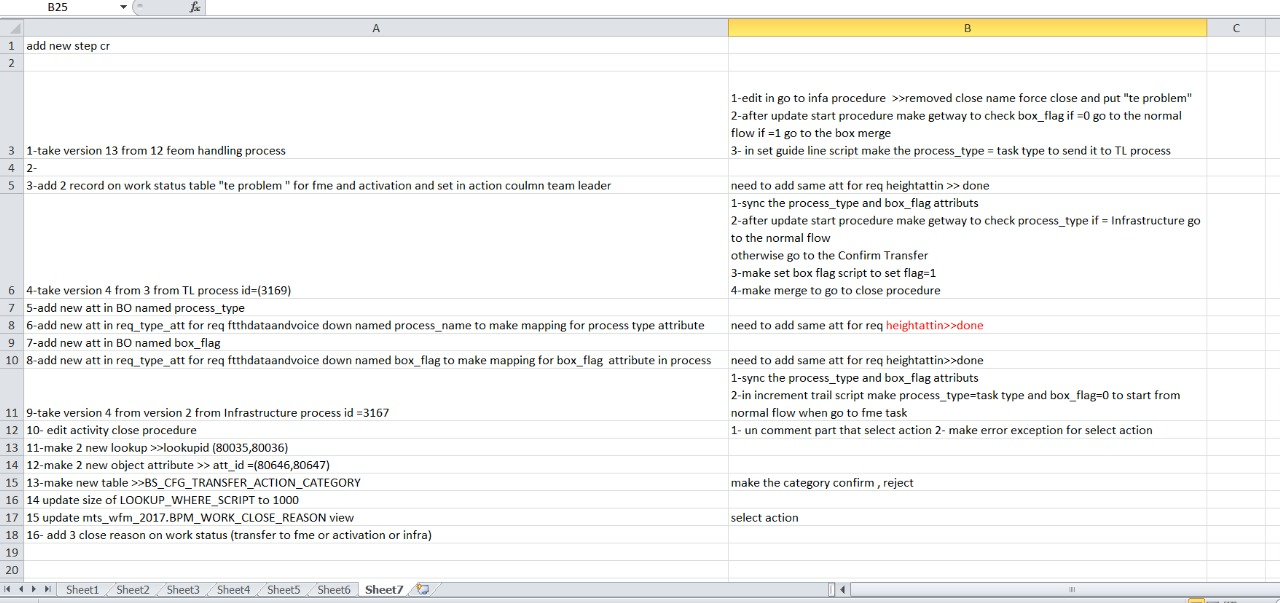

   CR: CR-2025-222 | Size: 1050x1503


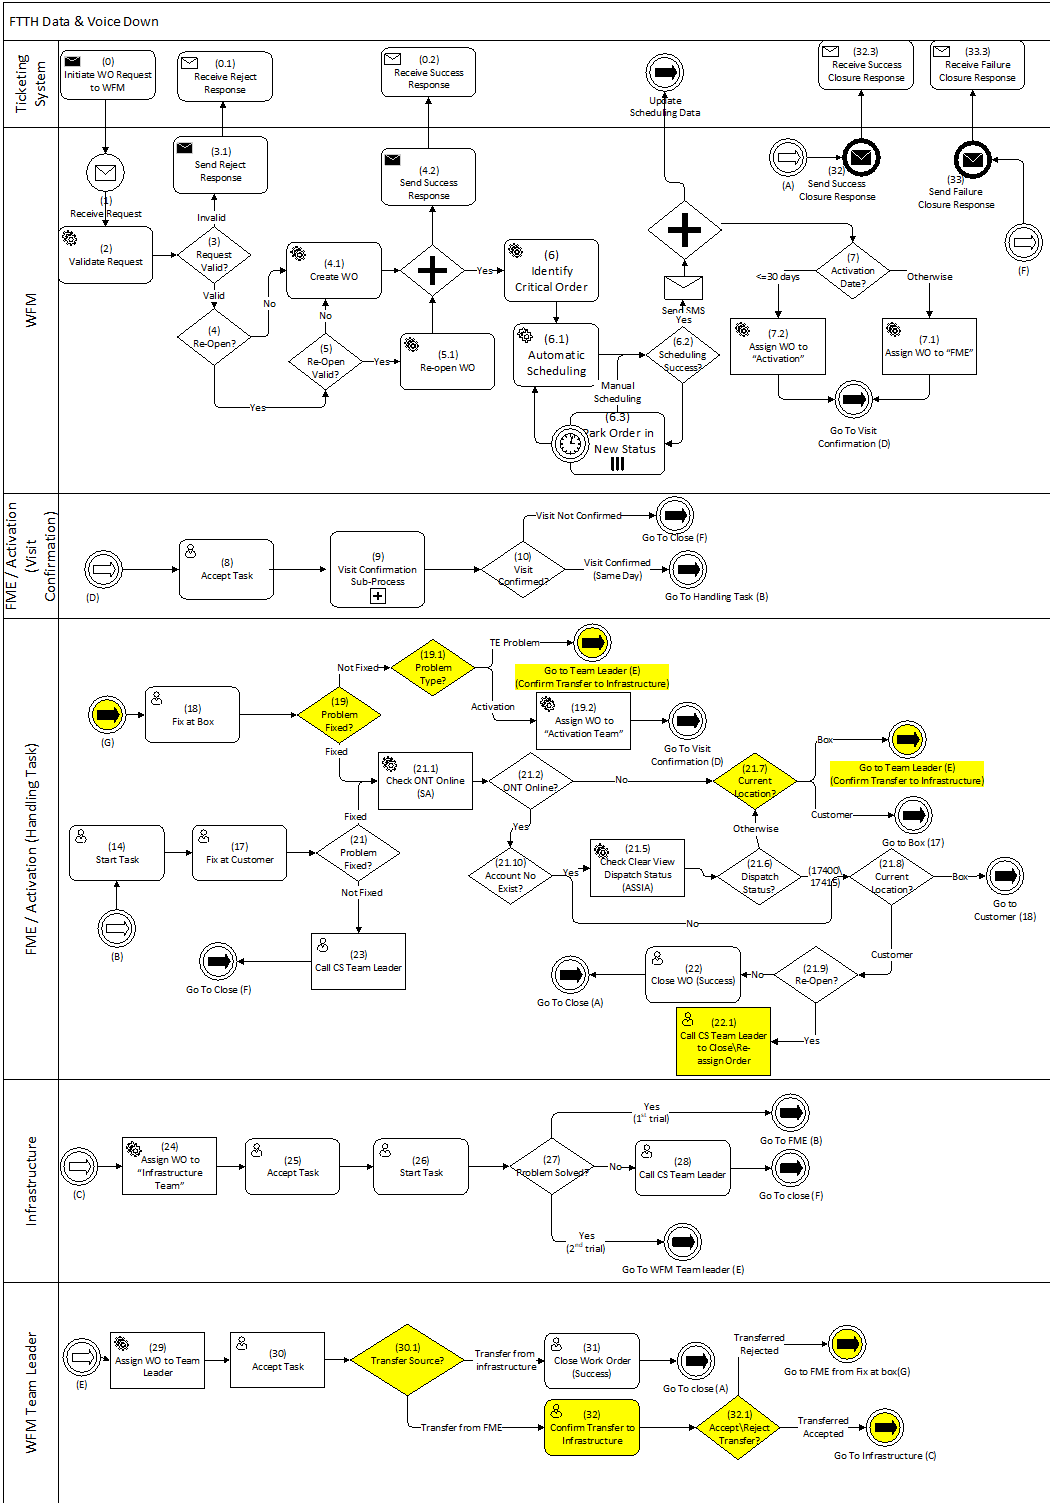


📄 Sources:
   - Technical_Solution for Add_Cables_Task CR.docx
   - (CR-2025-_222)_FTTH_Maintenance_-_Add_New_step_On_WFM_Workfl

[10/20] What is reserve activation no free port?
Category: Installation


[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



📊 Retrieval Metrics:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        0.50
   Latency:    0.64s

🤖 Answer:
----------------------------------------
Question: What is the purpose of the amendment to CR-2025-226 and how does it address the issue of the "No Free Port" close reason?

Answer: The amendment to CR-2025-226 addresses the issue of the "No Free Port" close reason by removing the "No Free Port" close reason and unifying the behavior of fix crossconnection subprocess for all scenarios (either validation after success close or unreached migration scenario). This amendment aims to ensure that the system correctly sends a "Fail Close" response with a -4 API code to (OM) system when a work order is closed with a "no free active port" status.

📊 Answer Metrics:
   Faithfulness: 0.75
   Relevance:    0.43
   Latency:      70.93s

🖼️ Related Images (3 found):
   CR: CR-2024-164 | Size: 1329x689


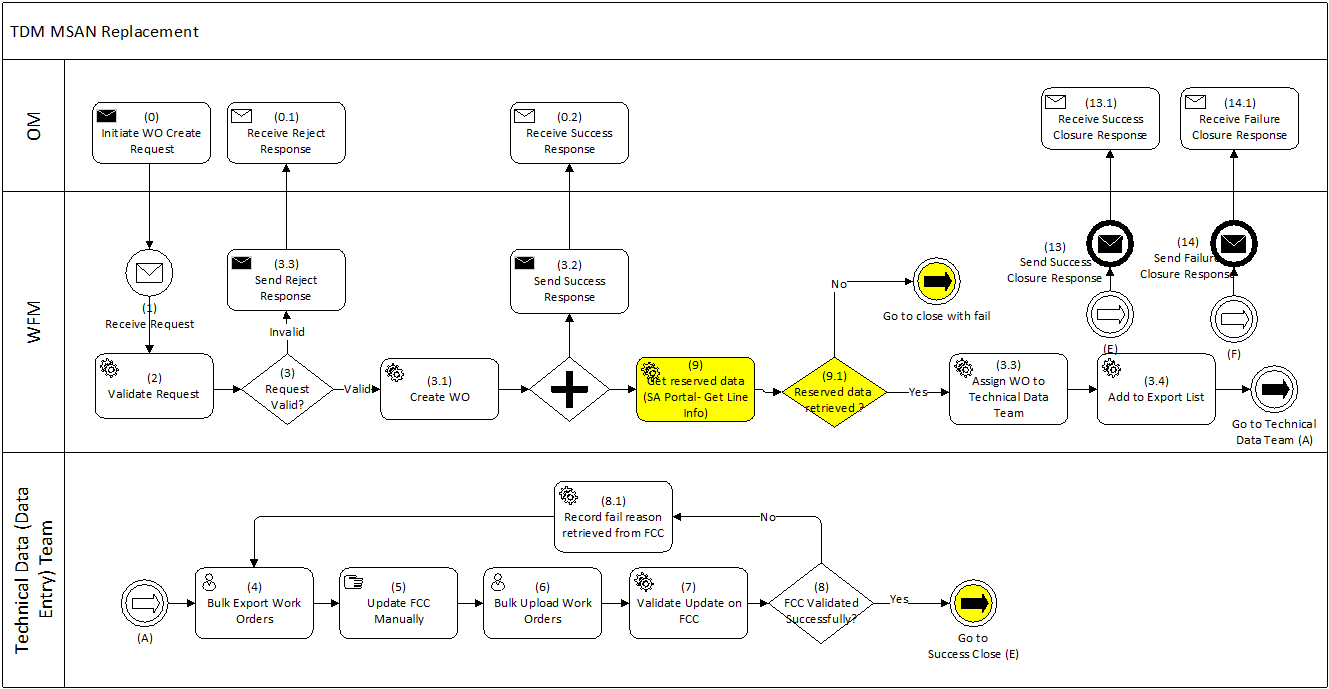

   CR: CR-2024-164 | Size: 1289x719


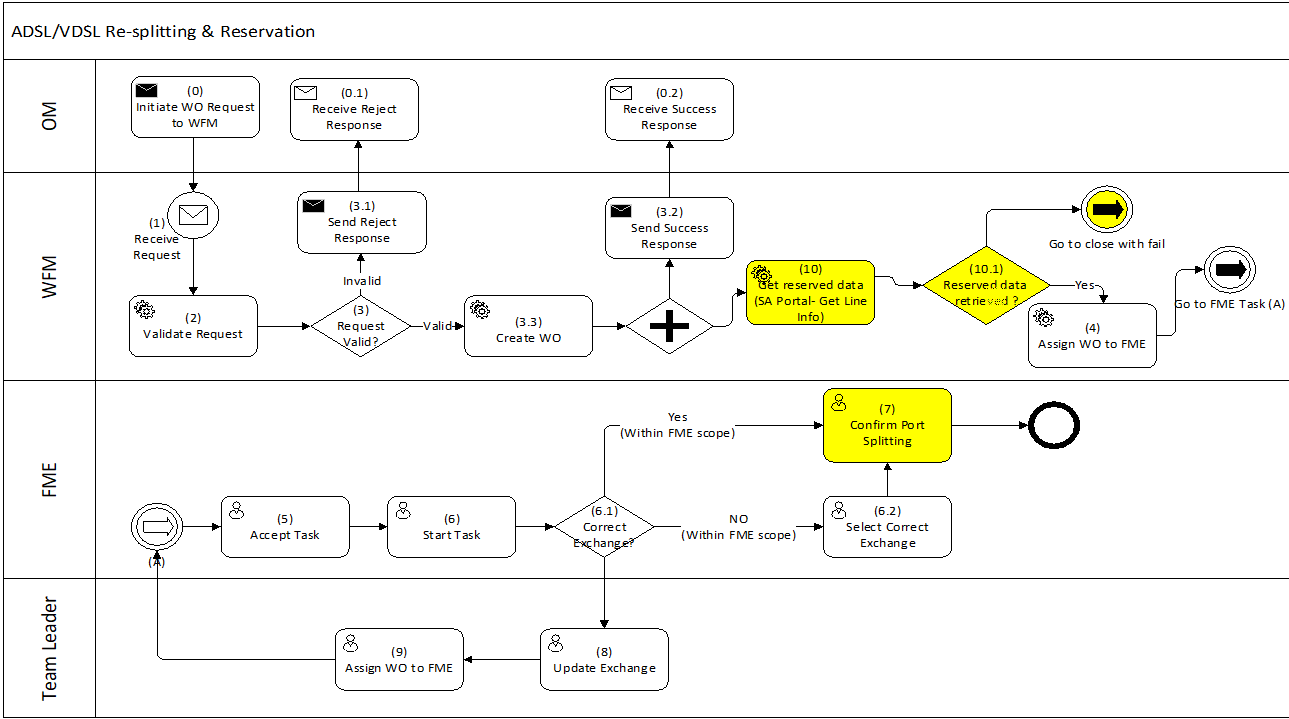


📄 Sources:
   - CR-2025-230_WFM_Reserve_Activation_No_free_port_amendment_(v
   - Technical_Solution for WFM Reserve Activation.docx
   - (CR-2024-164)_WFM_SA_-_Remove_Reservation_Activity_from_WFM(
   - CR-2025-226 WFM Reserve Activation - No free port(FTTH Surve

[11/20] How does FTTH migration work for unreached customers?
Category: Installation


[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



📊 Retrieval Metrics:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        1.00
   Latency:    0.32s

🤖 Answer:
----------------------------------------
To answer the question, FTTH migration works for unreached customers by modifying the workflow as described in the context. In case an order is closed with a customer-related close code during manual scheduling or visit confirmation sub-flows, the team leader cannot close with customer-related failure close codes unless the technical data is entered and the cross connection is validated. A new flag is associated with any failure closure with customer-related close code, which allows the team leader to close with failure close codes only if the technical data is entered and the cross connection is validated.

📊 Answer Metrics:
   Faithfulness: 0.75
   Relevance:    0.50
   Latency:      78.31s

🖼️ Related Images (1 found):
   CR: PM-2024-173 | Size: 1051x613


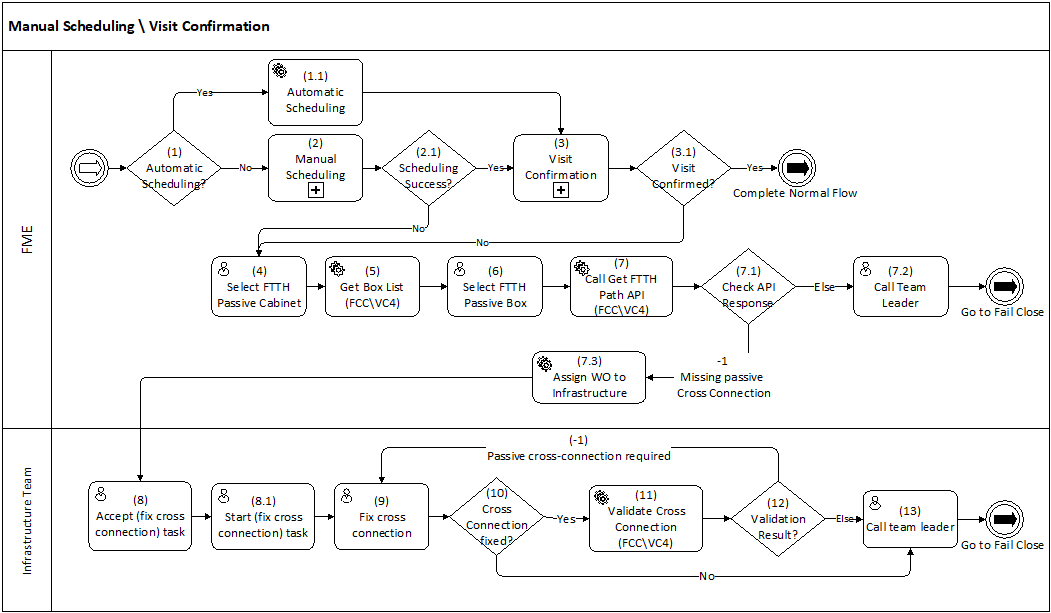


📄 Sources:
   - WFM FTTH Migration Un Reached  Rejected Customers CR (v0.3).
   - CR-2025-230_WFM_Reserve_Activation_No_free_port_amendment_(v

[12/20] What is the priority flag for installation orders?
Category: Installation

📊 Retrieval Metrics:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        1.00
   Latency:    6.87s

🤖 Answer:
----------------------------------------


[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


The priority flag for installation orders is modified in the context of the customer care portal installation orders page. The context states that the modification involves adding a manual action with special permission to set the WO priority (detractor flag) for a specific order. The action is considered the detractor flag start date\time, and the system will log the execution of the action. The modification involves setting the WO priority to either Normal (0) or Critical (1) based on the detractor flag. The system will log the execution of the action and log the execu

📊 Answer Metrics:
   Faithfulness: 0.76
   Relevance:    0.75
   Latency:      87.27s

🖼️ Related Images (3 found):
   CR: PM-2025-212 | Size: 1315x766


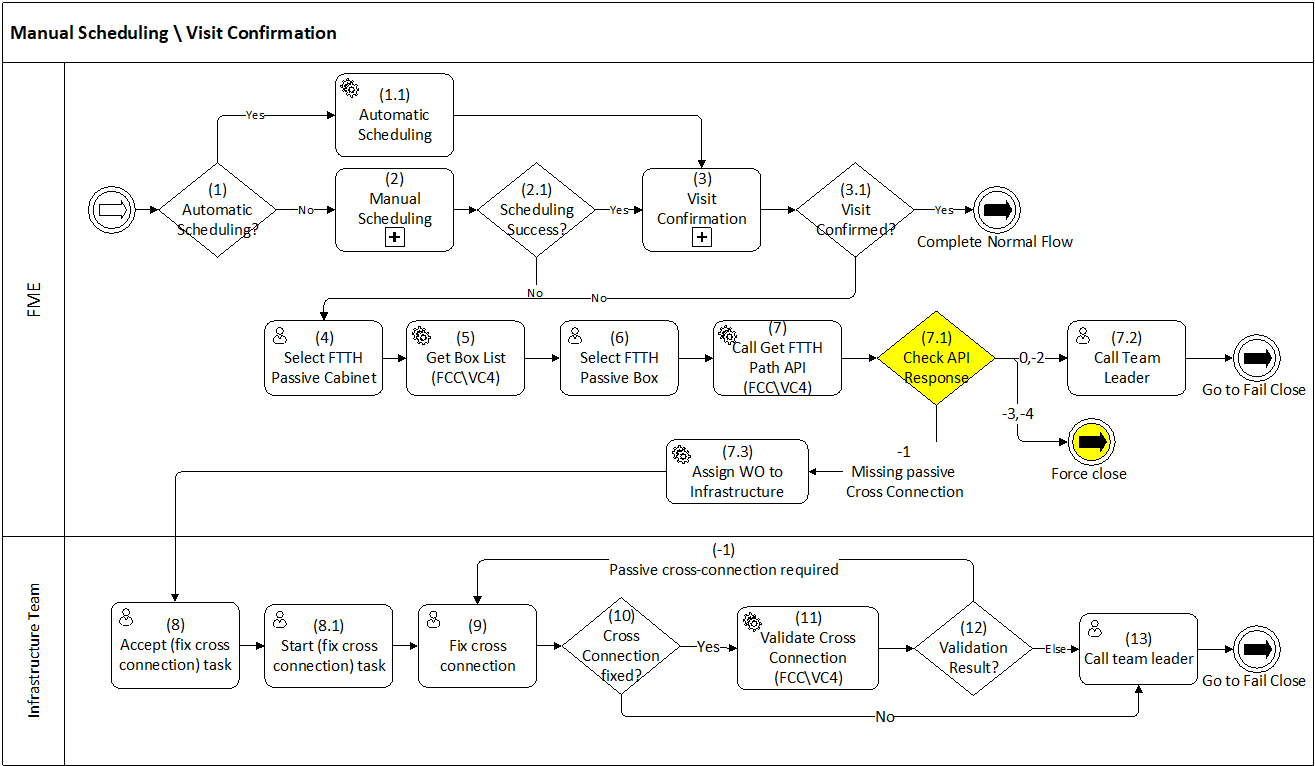

   CR: PM-2024-173 | Size: 1051x613


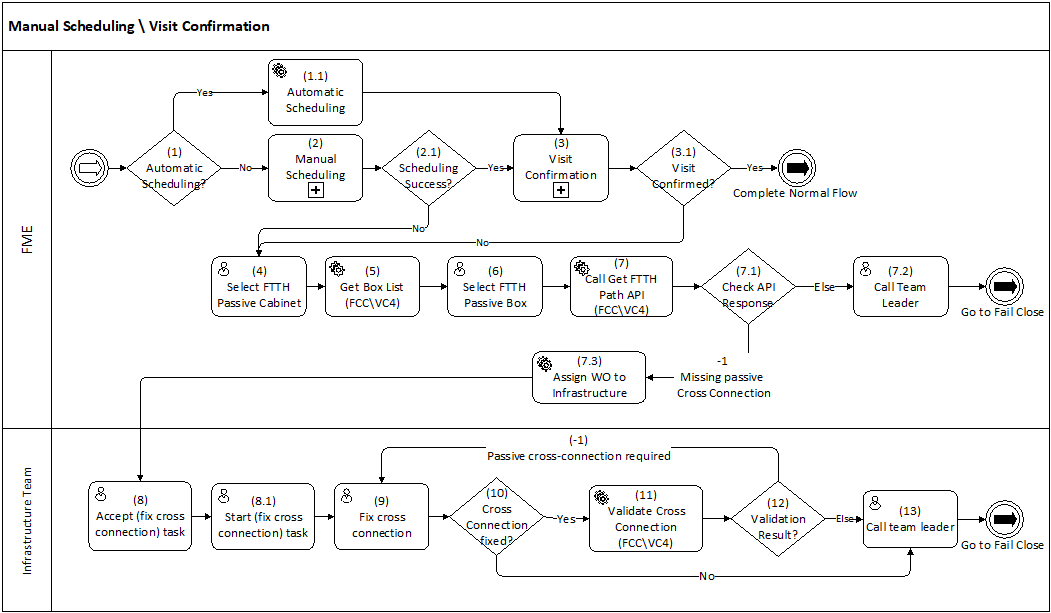


📄 Sources:
   - (CR-2026-251) WFM Add Priority flag to installation orders C
   - WFM FTTH Migration Un Reached  Rejected Customers CR (v0.3).
   - PM-2025-212  WFM_FTTH_Migration_Un_Reached_Rejected_Customer
   - (CR-2025-238) WFM FV Manual Survey - Add Team Leader Validat

[13/20] How to fix cross connection in WFM?
Category: Service_Activation

📊 Retrieval Metrics:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        1.00
   Latency:    2.35s

🤖 Answer:
----------------------------------------


[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


To fix cross connection in WFM, follow these steps:

1. Identify the cross-connection issue: Check the system check cross-connection validation result to identify the issue. If the result is "0", "-2", or "-4", the cross-connection is missing. If the result is "Passive cross-connection is missing", go to the fix passive cross-connection sub-process.

2. Check the number of trials to fix passive cross-connection: If the result is "0", "-2", or "-4", the cross-connection is missing. If the result is "Passive cross-connection is missing", go to the fix passive cross-connection sub-process.

3. Reassign the task: If the result is "0", "-2", or "-4", the cross-connection is missing. If the result is "Passive cross-connection is missing", go to the fix passive cross-connection sub-process.

4. Close the work order: If the result is "0", "-2", or "-4", the cross-connection is missing. If the result is "Passive cross-connection is missing", go to the fix passive cross-connection sub-process.



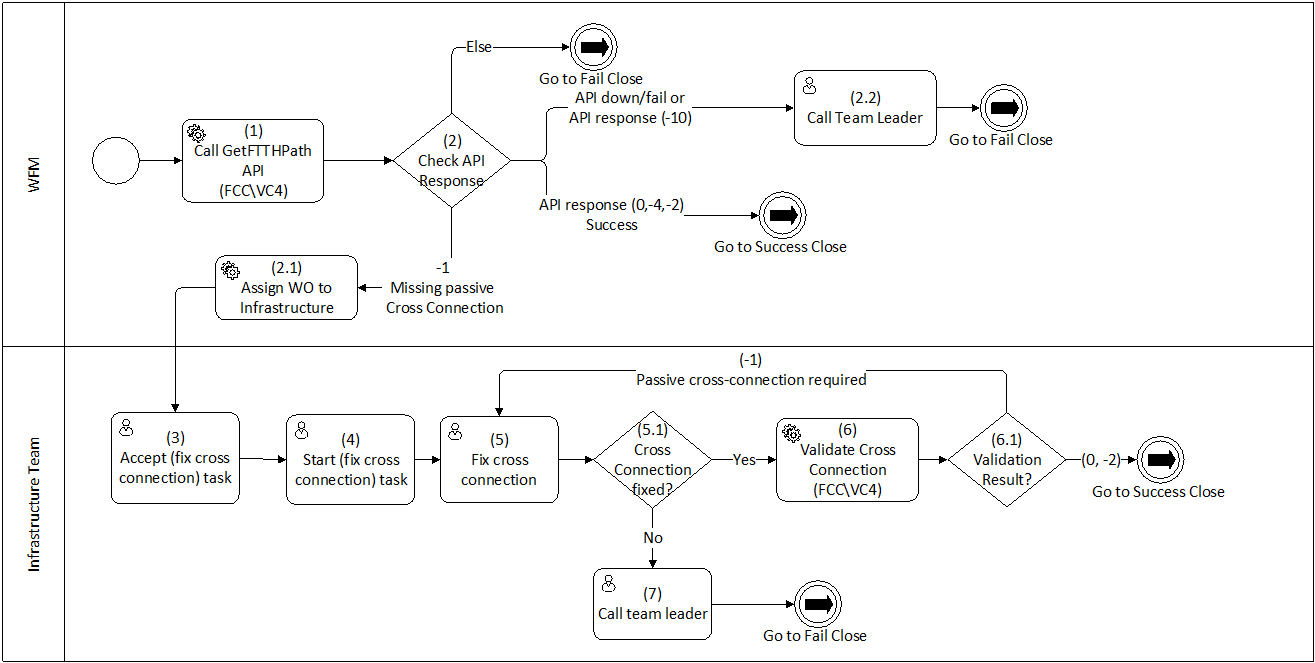

   CR: CR-2024-157 | Size: 1051x530


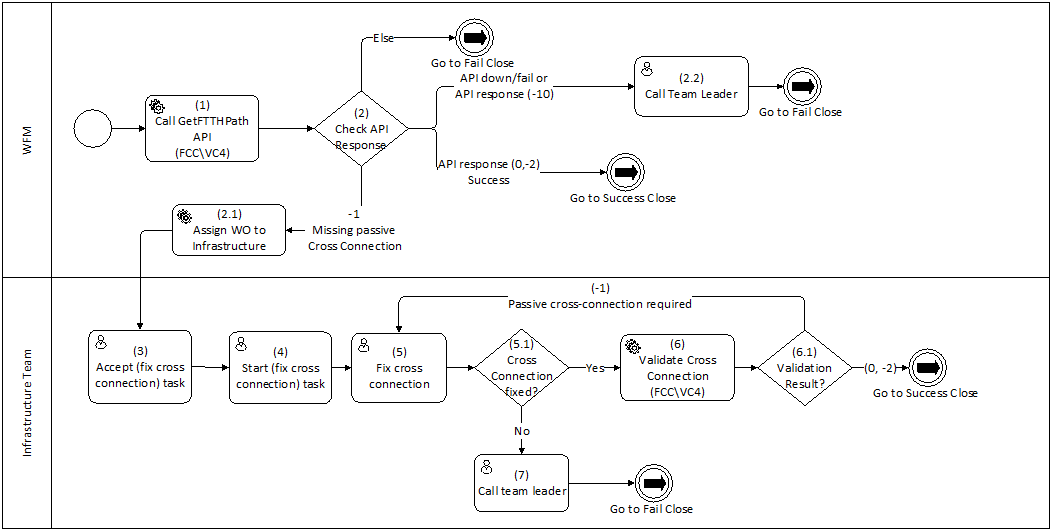


📄 Sources:
   - CR-2024-157_WFM_SA_Fix_cross-connection_CR_(V0.2).docx
   - (CR-2024-165) WFM SA Fix cross-connection Amendment(V0.1).do

[14/20] What is wrong card and port CR?
Category: Service_Activation

📊 Retrieval Metrics:
   Recall@5:  0.00
   Precision:  0.00
   MRR:        0.00
   Latency:    2.53s

🤖 Answer:
----------------------------------------


[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


The context provided does not specify the exact problem or issue that needs to be addressed. However, based on the provided context, the question is asking for the change in the workflow that needs to be made to address the problem or issue. The answer provided is "Change Frame Wrong Card & Port Change Port Change Port Technology" which is the change that needs to be made to the workflow to address the problem or issue.

📊 Answer Metrics:
   Faithfulness: 0.29
   Relevance:    0.57
   Latency:      41.32s

🖼️ Related Images (1 found):
   CR: CR-2025-208 | Size: 1305x561


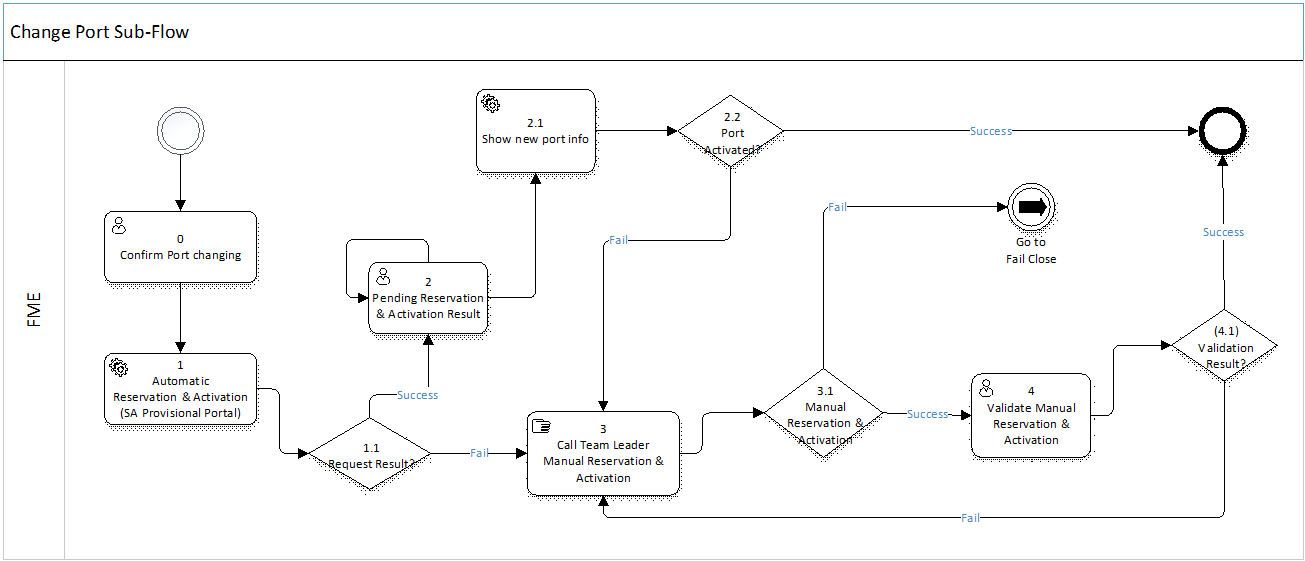

[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



📄 Sources:
   - (PM-2023-92)WFM_Add_linetype_for_indoor_MSAN_CR_(V0.1) (1).d
   - WFM_Remove Reservation Activity-damaged port.docx

[15/20] How to remove reservation activity from WFM?
Category: Service_Activation

📊 Retrieval Metrics:
   Recall@5:  0.00
   Precision:  0.00
   MRR:        0.00
   Latency:    0.09s

🤖 Answer:
----------------------------------------
To remove reservation activity from WFM, follow these steps:

1. Identify the work orders that involve reservation activity and modify them accordingly.

2. Modify the work order process to remove the reservation activity from the change process.

3. Ensure that the port technology data is down and the voice down and voice overlapping are removed.

4. Change the integration with the provisioning portal to perform the reservation from the PP side.

5. Modify the Port Technology Data and Voice Down to remove the reservation activity from the change process.

6. Modify the FV New Location to remove the reservation activity fr

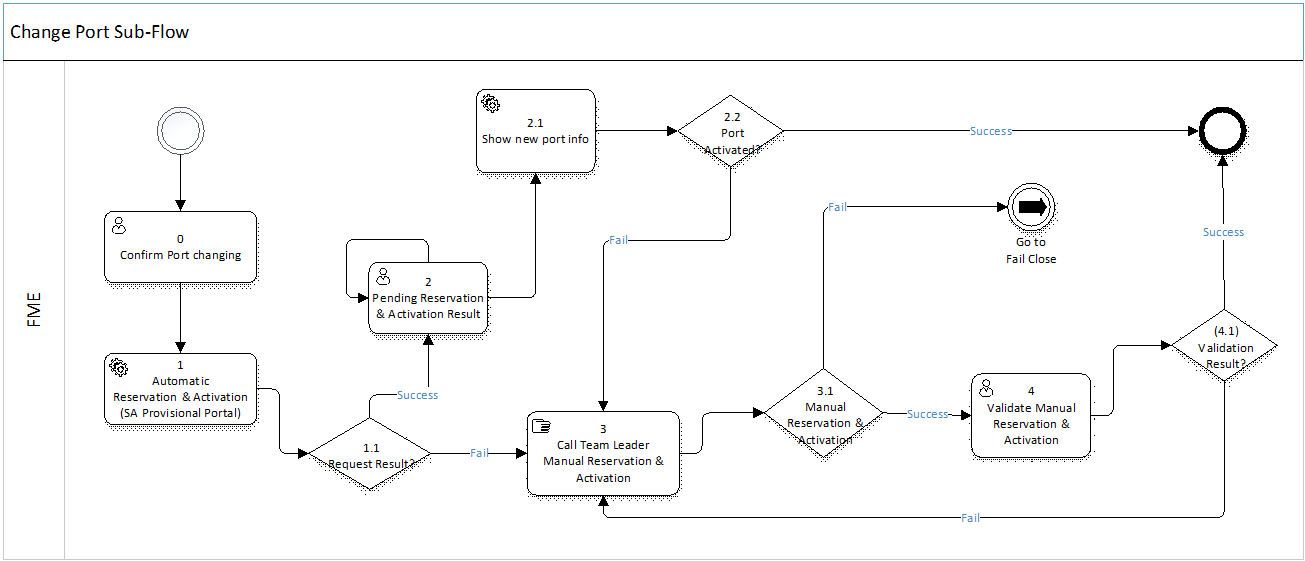


📄 Sources:
   - WFM_Remove Reservation Activity-damaged port.docx

[16/20] What is KPI report for team leader?
Category: Dashboard_Reports

📊 Retrieval Metrics:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        1.00
   Latency:    2.45s

🤖 Answer:
----------------------------------------


[transformers] Both `max_new_tokens` (=1000) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


KeyboardInterrupt: 

In [18]:
# ============================================
# 🧪 Full Evaluation مع إجابات وصور
# ============================================
import time
import numpy as np
from IPython.display import display, Image as IPImage

def full_evaluation_with_display(test_set, k=5):
    
    retrieval_results = []
    answer_results    = []
    
    print("🚀 Starting Full Evaluation...")
    print(f"📊 Total Questions: {len(test_set)}")
    
    for i, test in enumerate(test_set):
        
        query    = test["question"]
        relevant = test["relevant_crs"]
        category = test["category"]
        
        print("\n" + "=" * 60)
        print(f"[{i+1}/{len(test_set)}] {query}")
        print(f"Category: {category}")
        print("=" * 60)
        
        # =============================
        # Retrieval
        # =============================
        ret_start = time.time()
        chunks    = hybrid_search(query, top_k=k, category=category)
        ret_lat   = time.time() - ret_start
        
        retrieved_crs = [c["metadata"]["cr_number"] for c in chunks]
        
        hits      = sum(1 for r in relevant if r in retrieved_crs)
        recall    = hits / len(relevant)
        precision = hits / k
        
        mrr = 0
        for rank, cr in enumerate(retrieved_crs, 1):
            if cr in relevant:
                mrr = 1 / rank
                break
        
        retrieval_results.append({
            "question":  query,
            "category":  category,
            "recall":    round(recall, 3),
            "precision": round(precision, 3),
            "mrr":       round(mrr, 3),
            "latency":   round(ret_lat, 3),
        })
        
        print(f"\n📊 Retrieval Metrics:")
        print(f"   Recall@{k}:  {recall:.2f}")
        print(f"   Precision:  {precision:.2f}")
        print(f"   MRR:        {mrr:.2f}")
        print(f"   Latency:    {ret_lat:.2f}s")
        
        # =============================
        # Answer
        # =============================
        print(f"\n🤖 Answer:")
        print("-" * 40)
        
        ans_start = time.time()
        result    = generate_answer_local(query, chunks)
        ans_lat   = time.time() - ans_start
        
        answer = result["answer"]
        
        # طباعة الإجابة
        print(answer)
        
        # Metrics
        context_words = set(
            " ".join([c["text"] for c in chunks])
            .lower().split()
        )
        answer_words  = set(answer.lower().split())
        common        = context_words & answer_words
        faithfulness  = min(
            len(common) / max(len(answer_words), 1), 1.0
        )
        query_words   = set(query.lower().split())
        relevance     = min(
            len(query_words & answer_words) / 
            max(len(query_words), 1), 1.0
        )
        
        answer_results.append({
            "question":     query,
            "category":     category,
            "answer":       answer[:300],
            "faithfulness": round(faithfulness, 3),
            "relevance":    round(relevance, 3),
            "latency":      round(ans_lat, 3),
            "num_images":   result["num_images"]
        })
        
        print(f"\n📊 Answer Metrics:")
        print(f"   Faithfulness: {faithfulness:.2f}")
        print(f"   Relevance:    {relevance:.2f}")
        print(f"   Latency:      {ans_lat:.2f}s")
        
        # =============================
        # الصور
        # =============================
        if result["images"]:
            print(f"\n🖼️ Related Images ({result['num_images']} found):")
            for img in result["images"]:
                print(f"   CR: {img['cr']} | Size: {img['size']}")
                try:
                    display(IPImage(
                        filename=img['path'],
                        width=500
                    ))
                except Exception as e:
                    print(f"   ⚠️ {e}")
        else:
            print("\n🖼️ No images found")
        
        # Sources
        print("\n📄 Sources:")
        seen = set()
        for chunk in chunks:
            fname = chunk['metadata']['filename']
            if fname not in seen:
                print(f"   - {fname[:60]}")
                seen.add(fname)
    
    # =============================
    # Final Summary
    # =============================
    print("\n" + "=" * 60)
    print("📊 FINAL SUMMARY")
    print("=" * 60)
    
    avg_recall    = np.mean([r["recall"]       for r in retrieval_results])
    avg_precision = np.mean([r["precision"]    for r in retrieval_results])
    avg_mrr       = np.mean([r["mrr"]          for r in retrieval_results])
    avg_ret_lat   = np.mean([r["latency"]      for r in retrieval_results])
    avg_faith     = np.mean([r["faithfulness"] for r in answer_results])
    avg_rel       = np.mean([r["relevance"]    for r in answer_results])
    avg_ans_lat   = np.mean([r["latency"]      for r in answer_results])
    
    print(f"\n🔍 RETRIEVAL (k={k}):")
    print(f"   Recall:    {avg_recall:.3f}")
    print(f"   Precision: {avg_precision:.3f}")
    print(f"   MRR:       {avg_mrr:.3f}")
    print(f"   Latency:   {avg_ret_lat:.3f}s")
    
    print(f"\n🤖 ANSWER QUALITY:")
    print(f"   Faithfulness: {avg_faith:.3f}")
    print(f"   Relevance:    {avg_rel:.3f}")
    print(f"   Latency:      {avg_ans_lat:.3f}s")
    
    print(f"\n📁 BY CATEGORY:")
    categories = set(r["category"] for r in retrieval_results)
    for cat in sorted(categories):
        cat_res    = [r for r in retrieval_results if r["category"] == cat]
        cat_recall = np.mean([r["recall"] for r in cat_res])
        cat_mrr    = np.mean([r["mrr"]    for r in cat_res])
        print(f"   {cat:<25} Recall: {cat_recall:.2f} | MRR: {cat_mrr:.2f}")
    
    # حفظ
    final = {
        "summary": {
            "retrieval": {
                "recall":    round(avg_recall, 3),
                "precision": round(avg_precision, 3),
                "mrr":       round(avg_mrr, 3),
                "latency":   round(avg_ret_lat, 3)
            },
            "answer_quality": {
                "faithfulness": round(avg_faith, 3),
                "relevance":    round(avg_rel, 3),
                "latency":      round(avg_ans_lat, 3)
            }
        },
        "details": answer_results
    }
    
    with open("evaluation/full_evaluation.json", "w",
              encoding="utf-8") as f:
        json.dump(final, f, ensure_ascii=False, indent=2)
    
    print("\n✅ Saved in evaluation/full_evaluation.json")
    return final


# شغّل
eval_final = full_evaluation_with_display(test_set, k=5)

In [2]:
# ============================================
# 🚀 FULL SETUP - كل حاجة في خلية واحدة
# ============================================
import os
import json
import re
import io
import numpy as np
import torch
from pathlib import Path
from abc import ABC, abstractmethod
from transformers import pipeline
from sentence_transformers import SentenceTransformer
import chromadb
from rank_bm25 import BM25Okapi
from PIL import Image as PILImage
from IPython.display import display, Image as IPImage

# ============================================
# ⚙️ Configuration
# ============================================
CONFIG = {
    "model_path":    r"D:\internship\rag\model",
    "gen_model_path":r"D:\internship\rag\gen_model",
    "chroma_path":   r"D:\internship\rag\chroma_db",
    "images_path":   r"D:\internship\rag\images",
    "metadata_path": r"D:\internship\rag\metadata",
    "chunk_size":    750,   # ← محسّن
    "chunk_overlap": 75,    # ← محسّن
    "top_k":         7,     # ← محسّن
    "rrf_k":         60,
}

# ============================================
# 🏗️ Abstraction Layer
# ============================================
class VectorDB(ABC):
    @abstractmethod
    def add(self, ids, embeddings, documents, metadatas):
        pass
    @abstractmethod
    def search(self, query_embedding, n_results, filters):
        pass
    @abstractmethod
    def count(self):
        pass
    @abstractmethod
    def delete(self, ids):
        pass

class ChromaDB(VectorDB):
    def __init__(self, path: str):
        self.client = chromadb.PersistentClient(path=path)
        self.collection = self.client.get_or_create_collection(
            name="wfm_documents",
            metadata={"hnsw:space": "cosine"}
        )
    def add(self, ids, embeddings, documents, metadatas):
        self.collection.add(
            ids=ids,
            embeddings=embeddings,
            documents=documents,
            metadatas=metadatas
        )
    def search(self, query_embedding, n_results=10, filters=None):
        return self.collection.query(
            query_embeddings=[query_embedding],
            n_results=n_results,
            where=filters
        )
    def count(self):
        return self.collection.count()
    def delete(self, ids):
        self.collection.delete(ids=ids)

class QdrantDB(VectorDB):
    def __init__(self, path: str):
        pass
    def add(self, ids, embeddings, documents, metadatas):
        pass
    def search(self, query_embedding, n_results=10, filters=None):
        pass
    def count(self):
        pass
    def delete(self, ids):
        pass

# ============================================
# 🧠 تحميل الـ Models
# ============================================
print("⏳ Loading Embedding Model...")
local_model = SentenceTransformer(
    CONFIG["model_path"],
    local_files_only=True
)
print("✅ Embedding Model جاهز! (384d)")

print("⏳ Loading Generation Model...")
generator = pipeline(
    "text-generation",
    model=CONFIG["gen_model_path"],
    device=0 if torch.cuda.is_available() else -1,
    torch_dtype=torch.float16
)
print("✅ Generation Model جاهز!")

# ============================================
# 🗄️ تحميل الـ DB
# ============================================
print("⏳ Loading DB...")
db = ChromaDB(path=CONFIG["chroma_path"])
print(f"✅ DB جاهز! ({db.count()} chunks)")

# ============================================
# 📦 تحميل الـ Chunks
# ============================================
print("⏳ Loading chunks...")
all_chunks = []
total      = db.count()

results = db.search(
    query_embedding=local_model.encode(
        "work order",
        normalize_embeddings=True
    ).tolist(),
    n_results=total,
    filters=None
)

for i in range(len(results["ids"][0])):
    all_chunks.append({
        "chunk_id": results["ids"][0][i],
        "text":     results["documents"][0][i],
        "filename": results["metadatas"][0][i]["filename"],
        "category": results["metadatas"][0][i]["category"],
        "cr_number":results["metadatas"][0][i]["cr_number"],
        "heading":  results["metadatas"][0][i]["heading"],
    })

print(f"✅ Loaded: {len(all_chunks)} chunks")

# ============================================
# 🔍 BM25
# ============================================
print("⏳ Building BM25...")
tokenized = [c["text"].lower().split() for c in all_chunks]
bm25      = BM25Okapi(tokenized)
print("✅ BM25 جاهز!")

# ============================================
# 🔍 Search Functions
# ============================================
def rrf_fusion(dense_ids, bm25_ids, k=60):
    scores = {}
    for rank, doc_id in enumerate(dense_ids, 1):
        scores[doc_id] = scores.get(doc_id, 0) + 1/(k+rank)
    for rank, doc_id in enumerate(bm25_ids, 1):
        scores[doc_id] = scores.get(doc_id, 0) + 1/(k+rank)
    return sorted(scores, key=scores.get, reverse=True)

def hybrid_search(query, top_k=7, category=None):
    query_embedding = local_model.encode(
        query, normalize_embeddings=True
    ).tolist()
    filters     = {"category": category} if category else None
    dense_res   = db.search(query_embedding, top_k*2, filters)
    dense_ids   = dense_res["ids"][0]
    dense_docs  = dense_res["documents"][0]
    dense_meta  = dense_res["metadatas"][0]
    bm25_scores = bm25.get_scores(query.lower().split())
    bm25_top    = np.argsort(-bm25_scores)[:top_k*2]
    bm25_ids    = [all_chunks[i]["chunk_id"] for i in bm25_top]
    fused_ids   = rrf_fusion(dense_ids, bm25_ids)
    results = []
    seen    = set()
    for chunk_id in fused_ids[:top_k]:
        if chunk_id in dense_ids and chunk_id not in seen:
            idx = dense_ids.index(chunk_id)
            results.append({
                "chunk_id": chunk_id,
                "text":     dense_docs[idx],
                "metadata": dense_meta[idx],
            })
            seen.add(chunk_id)
    return results

# ============================================
# 🖼️ Image Filter
# ============================================
def is_process_flow(img_path: str) -> bool:
    try:
        with PILImage.open(img_path) as im:
            w, h   = im.size
            ratio  = w / h
            pixels = w * h
            if pixels < 300000:
                return False
            if abs(ratio - 1.0) < 0.2 and pixels < 500000:
                return False
            if ratio > 3.0:
                return False
            if pixels > 500000 and 0.3 < ratio < 3.0:
                return True
            return False
    except:
        return False

def get_related_images(chunks: list) -> list:
    images_meta_path = os.path.join(
        CONFIG["metadata_path"],
        "images_metadata.json"
    )
    if not os.path.exists(images_meta_path):
        return []
    with open(images_meta_path, "r", encoding="utf-8") as f:
        images_metadata = json.load(f)
    result_crs  = set(c["metadata"]["cr_number"] for c in chunks)
    image_paths = []
    for img in images_metadata:
        if img.get("cr_number") in result_crs:
            img_path = img.get("image_path", "")
            img_name = img.get("image_name") or \
                       img.get("image_id", "Unknown")
            if os.path.exists(img_path):
                if is_process_flow(img_path):
                    try:
                        with PILImage.open(img_path) as im:
                            w, h = im.size
                        image_paths.append({
                            "path":     img_path,
                            "cr":       img.get("cr_number"),
                            "filename": img_name,
                            "size":     f"{w}x{h}",
                            "pixels":   w * h
                        })
                    except:
                        pass
    image_paths.sort(key=lambda x: x["pixels"], reverse=True)
    return image_paths[:2]

# ============================================
# 🤖 Generate Answer
# ============================================
def generate_answer_local(query: str, chunks: list) -> dict:
    context = ""
    for i, chunk in enumerate(chunks, 1):
        context += f"\n[Source {i}]\n{chunk['text'][:700]}\n"
    
    messages = [
        {
            "role": "system",
            "content": (
                "You are a WFM expert assistant. "
                "Rules:\n"
                "1. Answer ONLY from provided sources\n"
                "2. Be specific and detailed\n"
                "3. List all important points\n"
                "4. Never add info not in sources\n"
                "5. Never repeat the question\n"
                "6. Start answer directly"
            )
        },
        {
            "role": "user",
            "content": (
                f"Sources:\n{context}\n\n"
                f"Question: {query}\n\n"
                "Provide a complete detailed answer:"
            )
        }
    ]
    
    prompt = generator.tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    
    response = generator(
        prompt,
        max_new_tokens=800,
        do_sample=True,
        temperature=0.3,
        top_p=0.9,
        repetition_penalty=1.3
    )
    
    full_text = response[0]['generated_text']
    answer    = full_text.split("<|assistant|>")[-1].strip()
    
    # شيل التكرار
    lines  = answer.split('\n')
    unique = []
    seen   = set()
    for line in lines:
        clean = line.strip()
        if clean and clean not in seen:
            unique.append(line)
            seen.add(clean)
    answer = '\n'.join(unique)
    
    images = get_related_images(chunks)
    
    return {
        "answer":     answer,
        "images":     images,
        "num_images": len(images)
    }

# ============================================
# 🔍 Ask
# ============================================
def ask(query: str, category: str = None):
    chunks = hybrid_search(
        query,
        top_k=CONFIG["top_k"],
        category=category
    )
    print(f"\n🔍 Query: {query}")
    print(f"📚 Context: {len(chunks)} chunks")
    print("\n🤖 Answer:")
    print("=" * 60)
    result = generate_answer_local(query, chunks)
    print(result["answer"])
    if result["images"]:
        print(f"\n🖼️ Process Flow Diagrams ({result['num_images']}):")
        for img in result["images"]:
            print(f"\n   📌 CR: {img['cr']} | Size: {img['size']}")
            try:
                display(IPImage(filename=img['path'], width=600))
            except Exception as e:
                print(f"      ⚠️ {e}")
    else:
        print("\n🖼️ No Process Flow Diagrams found")
    print("\n📄 Sources:")
    seen = set()
    for chunk in chunks:
        fname = chunk['metadata']['filename']
        if fname not in seen:
            print(f"   - {fname[:60]}")
            seen.add(fname)

print("\n" + "=" * 50)
print("✅ كل حاجة جاهزة!")
print(f"📊 Chunks:     {len(all_chunks)}")
print(f"📐 Chunk Size: {CONFIG['chunk_size']}")
print(f"🔍 Top K:      {CONFIG['top_k']}")
print("🚀 جاهز للاستخدام!")

⏳ Loading Embedding Model...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


✅ Embedding Model جاهز! (384d)
⏳ Loading Generation Model...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

✅ Generation Model جاهز!
⏳ Loading DB...
✅ DB جاهز! (957 chunks)
⏳ Loading chunks...
✅ Loaded: 957 chunks
⏳ Building BM25...
✅ BM25 جاهز!

✅ كل حاجة جاهزة!
📊 Chunks:     957
📐 Chunk Size: 750
🔍 Top K:      7
🚀 جاهز للاستخدام!



🔍 Query: How does WFM handle no free slots in scheduling?
📚 Context: 6 chunks

🤖 Answer:


[transformers] Passing `generation_config` together with generation-related arguments=({'top_p', 'repetition_penalty', 'temperature', 'max_new_tokens', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=800) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer LlamaTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup any

To ensure that there are enough available timeslots during the specified time intervals for automated scheduling, Automatic Scheduling uses a rule called "Selects the First Available Time Interval With Free Timeslot(s)" which checks whether any time slots remain unused at the end of the previous time interval. This ensures that there are always some empty slots left over even though there might already be several requests waiting for their turn. Additionally, Automatic Scheduling also includes a feature called "Park Order" wherein it records the order's ID along with its start/end dates so that manual schedulers don't need to enter them again later. This helps avoid errors caused due to human error while entering data. Finally, Automatic Scheduling allows users to specify the desired number of slots for each zone in the configuration file, allowing flexibility in terms of how many visits can be made simultaneously without causing conflicts. Overall, this approach minimizes the risk of 

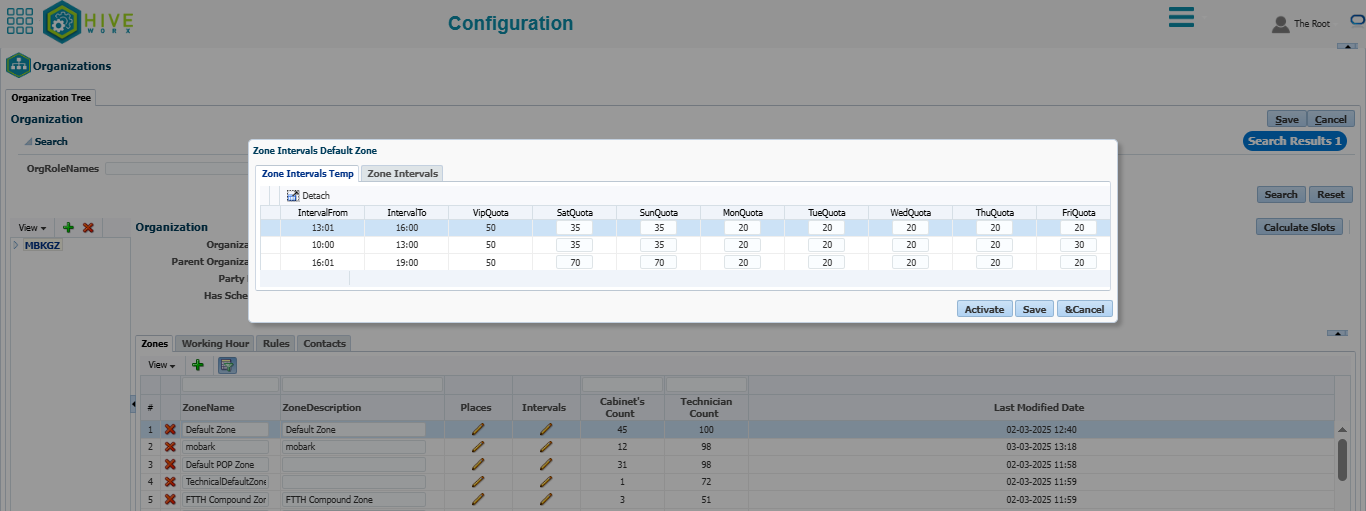


   📌 CR: CR-2025-220 | Size: 1148x602


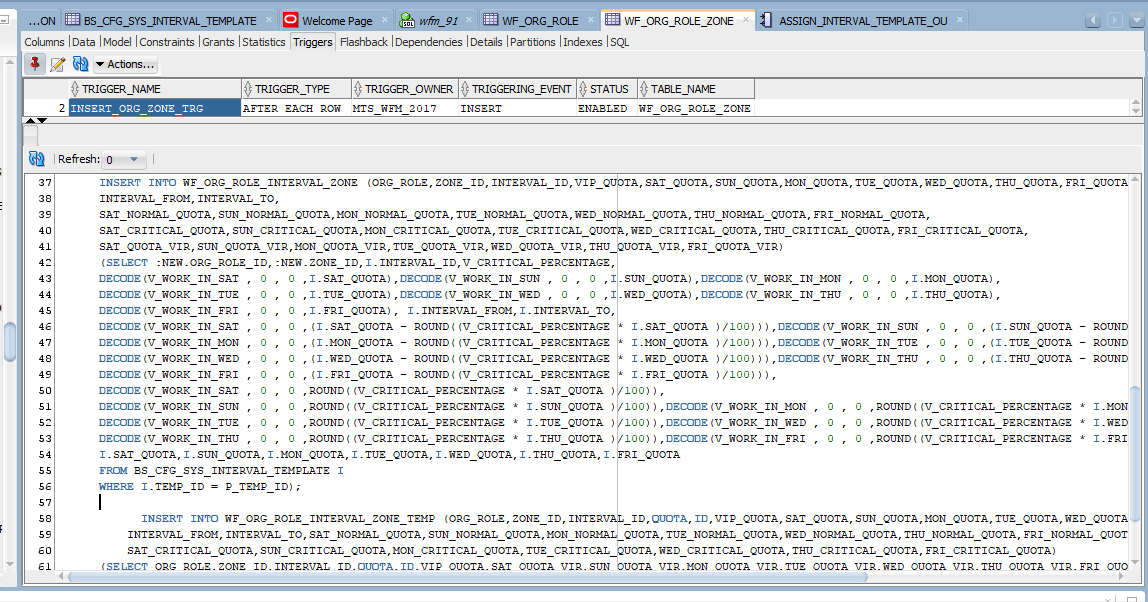


📄 Sources:
   - (PM-2024-126)WFM Scheduling Portal - FO Maintenance FRS (V0.
   - (CR-2025-220)WFM Automatic Scheduling Enhancement CR (V0.2).


In [3]:
ask("How does WFM handle no free slots in scheduling?",
    category="Scheduling")

In [ ]:
# ============================================
# 🤖 Generate Answer بـ Gemini
# ============================================
import google.genai as genai

# API Key
GEMINI_API_KEY = ""
gemini_client  = genai.Client(api_key=GEMINI_API_KEY)

MODELS_TO_TRY = [
    "models/gemini-3.5-flash",
    "models/gemini-3.8-flash",
    "models/gemini-3.7-flash",
]

def generate_answer_gemini(query: str, chunks: list) -> dict:
    
    # Context
    context = ""
    for i, chunk in enumerate(chunks, 1):
        context += f"\n[Source {i}]\n{chunk['text'][:700]}\n"
    
    # Prompt
    prompt = f"""
You are a WFM (Workforce Management) expert assistant.

RULES:
1. Answer ONLY from the provided sources
2. Be specific and detailed
3. List all important points
4. Never add info not in sources
5. If info is missing say what you found
6. Start answer directly

SOURCES:
{context}

QUESTION: {query}

DETAILED ANSWER:
"""
    
    for model_name in MODELS_TO_TRY:
        try:
            response = gemini_client.models.generate_content(
                model=model_name,
                contents=prompt
            )
            print(f"✅ Used: {model_name}")
            return {
                "answer":     response.text,
                "images":     get_related_images(chunks),
                "num_images": len(get_related_images(chunks))
            }
        except Exception as e:
            print(f"⚠️ {model_name}: {str(e)[:40]}")
            continue
    
    return {
        "answer":     "❌ كل الـ Models مش متاحة",
        "images":     [],
        "num_images": 0
    }


def ask(query: str, category: str = None):
    
    chunks = hybrid_search(
        query,
        top_k=CONFIG["top_k"],
        category=category
    )
    
    print(f"\n🔍 Query: {query}")
    print(f"📚 Context: {len(chunks)} chunks")
    print("\n🤖 Answer:")
    print("=" * 60)
    
    result = generate_answer_gemini(query, chunks)
    print(result["answer"])
    
    if result["images"]:
        print(f"\n🖼️ Process Flow Diagrams ({result['num_images']}):")
        for img in result["images"]:
            print(f"\n   📌 CR: {img['cr']} | Size: {img['size']}")
            try:
                display(IPImage(filename=img['path'], width=600))
            except Exception as e:
                print(f"      ⚠️ {e}")
    else:
        print("\n🖼️ No Process Flow Diagrams found")
    
    print("\n📄 Sources:")
    seen = set()
    for chunk in chunks:
        fname = chunk['metadata']['filename']
        if fname not in seen:
            print(f"   - {fname[:60]}")
            seen.add(fname)


print("✅ Gemini Generation جاهز!")

✅ Gemini Generation جاهز!



🔍 Query: How does WFM handle no free slots in scheduling?
📚 Context: 6 chunks

🤖 Answer:
✅ Used: models/gemini-3.5-flash
When there are no free slots during scheduling, WFM handles the situation according to the following rules and processes:

* **Critical Orders Search Sequence:** 
  * In the case of a critical order, WFM first searches for a free critical slot in the next time interval. If no critical slots are available, it then searches normal slots, continuing this same sequence across time intervals for the configured number of days (X days) (Source 1, Source 3).

* **Order Parking ("No Free Slots" Status):** 
  * If WFM fails to automatically schedule a visit time because slot capacity is fully utilized within the configured X days, the work order is parked in a new WFM status called **“No Free Slots”** (Source 1, Source 2).

* **Email Notification:** 
  * When an order is parked in the "No Free Slots" status, WFM automatically sends an email notification to a configured mailin

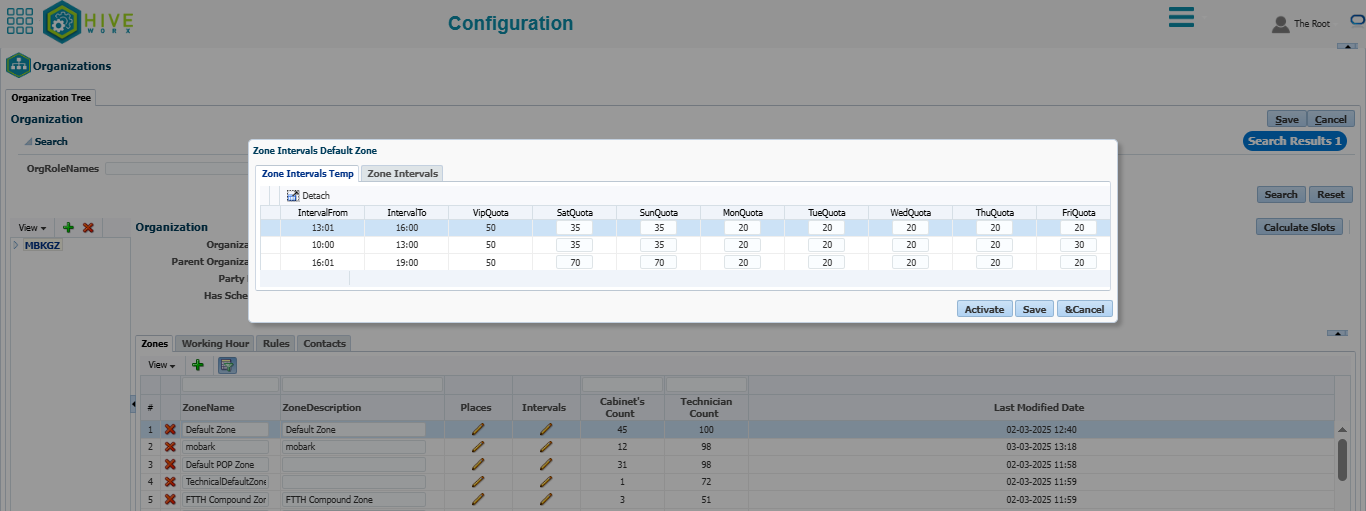


   📌 CR: CR-2025-220 | Size: 1148x602


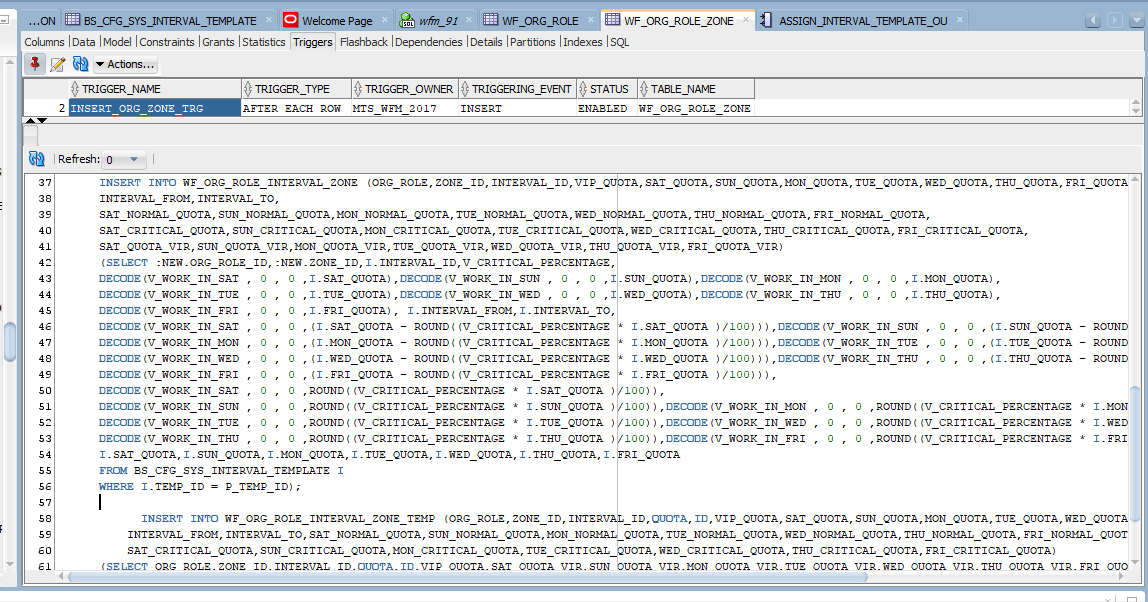


📄 Sources:
   - (PM-2024-126)WFM Scheduling Portal - FO Maintenance FRS (V0.
   - (CR-2025-220)WFM Automatic Scheduling Enhancement CR (V0.2).


In [7]:
ask("How does WFM handle no free slots in scheduling?",
    category="Scheduling")

In [8]:
# ============================================
# 🖼️ Image Filter المحسّن
# ============================================
import numpy as np

def analyze_image(img_path: str) -> dict:
    """
    بيحلل الصورة ويرجع خصائصها
    """
    try:
        with PILImage.open(img_path) as im:
            w, h = im.size
            ratio   = w / h
            pixels  = w * h
            
            # تحويل لـ RGB
            img_rgb   = im.convert('RGB')
            img_array = np.array(img_rgb)
            
            # متوسط الإضاءة
            avg_brightness = img_array.mean()
            
            # تنوع الألوان
            # بنسمبل الصورة لحجم صغير
            small      = im.resize((100, 100))
            small_arr  = np.array(small.convert('RGB'))
            
            # عدد الألوان الفريدة
            pixels_flat  = small_arr.reshape(-1, 3)
            unique_colors = len(np.unique(
                pixels_flat, axis=0
            ))
            
            # نسبة الألوان الفريدة
            color_variety = unique_colors / (100 * 100)
            
            # الألوان السائدة
            r_mean = img_array[:,:,0].mean()
            g_mean = img_array[:,:,1].mean()
            b_mean = img_array[:,:,2].mean()
            
            return {
                "width":          w,
                "height":         h,
                "ratio":          ratio,
                "pixels":         pixels,
                "brightness":     avg_brightness,
                "color_variety":  color_variety,
                "r_mean":         r_mean,
                "g_mean":         g_mean,
                "b_mean":         b_mean,
            }
    except:
        return None


def is_process_flow(img_path: str) -> bool:
    """
    بيحدد لو الصورة Process Flow
    بناءً على تحليل الألوان
    """
    info = analyze_image(img_path)
    if not info:
        return False
    
    # =============================
    # فلتر الحجم
    # =============================
    # صغيرة جداً
    if info["pixels"] < 300000:
        return False
    
    # =============================
    # فلتر الـ SQL/Code Screenshots
    # =============================
    # IDE داكن (dark theme)
    if info["brightness"] < 80:
        return False
    
    # الصورة بيضاء جداً مع نص
    # (SQL في IDE أبيض)
    if info["brightness"] > 240:
        return False
    
    # لو تنوع الألوان قليل = Screenshot
    # Process Flow فيه ألوان كتير
    if info["color_variety"] < 0.15:
        return False
    
    # =============================
    # فلتر الـ Logos
    # =============================
    # مربع وصغير = Logo
    if abs(info["ratio"] - 1.0) < 0.2 \
       and info["pixels"] < 500000:
        return False
    
    # =============================
    # فلتر الـ Wide Screenshots
    # =============================
    # عريض جداً = UI Screenshot
    if info["ratio"] > 3.5:
        return False
    
    # =============================
    # Process Flow Check
    # =============================
    # الصورة كبيرة + ألوان متعددة
    # + مش داكنة ومش بيضاء
    is_good_size    = info["pixels"] > 400000
    is_colorful     = info["color_variety"] > 0.15
    is_good_bright  = 80 < info["brightness"] < 220
    is_good_ratio   = 0.3 < info["ratio"] < 3.0
    
    return (
        is_good_size and
        is_colorful and
        is_good_bright and
        is_good_ratio
    )


def get_related_images(chunks: list) -> list:
    """
    بيجيب الصور المتعلقة مع الفلتر المحسّن
    """
    images_meta_path = os.path.join(
        CONFIG["metadata_path"],
        "images_metadata.json"
    )
    
    if not os.path.exists(images_meta_path):
        return []
    
    with open(images_meta_path, "r",
              encoding="utf-8") as f:
        images_metadata = json.load(f)
    
    result_crs  = set(
        c["metadata"]["cr_number"]
        for c in chunks
    )
    
    image_paths = []
    
    for img in images_metadata:
        if img.get("cr_number") in result_crs:
            img_path = img.get("image_path", "")
            img_name = img.get("image_name") or \
                       img.get("image_id", "Unknown")
            
            if os.path.exists(img_path):
                if is_process_flow(img_path):
                    info = analyze_image(img_path)
                    if info:
                        image_paths.append({
                            "path":     img_path,
                            "cr":       img.get("cr_number"),
                            "filename": img_name,
                            "size":     f"{info['width']}x{info['height']}",
                            "pixels":   info["pixels"],
                            "variety":  info["color_variety"]
                        })
    
    # Sort: الأكتر تنوعاً في الألوان (= Process Flow حقيقي)
    image_paths.sort(
        key=lambda x: x["variety"],
        reverse=True
    )
    
    return image_paths[:2]


# =============================
# 🧪 تجربة الفلتر
# =============================
print("🧪 Testing Image Filter...")

images_meta_path = os.path.join(
    CONFIG["metadata_path"],
    "images_metadata.json"
)

with open(images_meta_path, "r", encoding="utf-8") as f:
    images_metadata = json.load(f)

passed  = 0
failed  = 0

for img in images_metadata[:50]:
    img_path = img.get("image_path", "")
    if os.path.exists(img_path):
        info = analyze_image(img_path)
        if info:
            result = is_process_flow(img_path)
            if result:
                passed += 1
                print(f"✅ {img_path.split('/')[-1][:40]}"
                      f" | Variety: {info['color_variety']:.2f}"
                      f" | Bright: {info['brightness']:.0f}")
            else:
                failed += 1

print(f"\n✅ Passed: {passed}")
print(f"❌ Filtered: {failed}")
print("✅ Image Filter محسّن جاهز!")

🧪 Testing Image Filter...

✅ Passed: 0
❌ Filtered: 50
✅ Image Filter محسّن جاهز!


In [9]:
# ============================================
# 🔍 Debug: شوف قيم الصور
# ============================================

images_meta_path = os.path.join(
    CONFIG["metadata_path"],
    "images_metadata.json"
)

with open(images_meta_path, "r", encoding="utf-8") as f:
    images_metadata = json.load(f)

print("📊 Image Analysis:")
print("=" * 70)

for img in images_metadata[:20]:
    img_path = img.get("image_path", "")
    if os.path.exists(img_path):
        info = analyze_image(img_path)
        if info:
            print(f"\n📄 {img_path.split(chr(92))[-1][:40]}")
            print(f"   Size:       {info['width']}x{info['height']}")
            print(f"   Pixels:     {info['pixels']:,}")
            print(f"   Brightness: {info['brightness']:.1f}")
            print(f"   Variety:    {info['color_variety']:.3f}")
            print(f"   Ratio:      {info['ratio']:.2f}")

📊 Image Analysis:

📄 (CR-2024-136)WFM BOX Complain CR (V0.1)_
   Size:       16x16
   Pixels:     256
   Brightness: 223.1
   Variety:    0.000
   Ratio:      1.00

📄 (CR-2024-136)WFM BOX Complain CR (V0.1)_
   Size:       1049x569
   Pixels:     596,881
   Brightness: 241.8
   Variety:    0.088
   Ratio:      1.84

📄 WFM - SA Post Production - Modify SA API
   Size:       16x16
   Pixels:     256
   Brightness: 223.1
   Variety:    0.000
   Ratio:      1.00

📄 FTTH_Portal_Add_ODN_network_type_ATPs(v1
   Size:       200x200
   Pixels:     40,000
   Brightness: 248.5
   Variety:    0.066
   Ratio:      1.00

📄 FTTH_Portal_Add_ODN_network_type_ATPs(v1
   Size:       652x320
   Pixels:     208,640
   Brightness: 50.4
   Variety:    0.108
   Ratio:      2.04

📄 FTTH_Portal_Add_ODN_network_type_ATPs(v1
   Size:       558x324
   Pixels:     180,792
   Brightness: 236.0
   Variety:    0.127
   Ratio:      1.72

📄 (CR-2025-202)_FTTH_Portal_Add_ODN_networ
   Size:       16x16
   Pixels:     256

In [10]:
def is_process_flow(img_path: str) -> bool:
    
    info = analyze_image(img_path)
    if not info:
        return False
    
    # ❌ صغيرة جداً
    if info["pixels"] < 400000:
        return False
    
    # ❌ Ratio غلط (شرائط أو مربعات)
    if info["ratio"] > 3.0 or info["ratio"] < 0.5:
        return False
    
    # ❌ Dark Screenshots
    if info["brightness"] < 150:
        return False
    
    # ✅ Process Flow
    # كبيرة + Ratio كويس + مش داكنة
    return True


def get_related_images(chunks: list) -> list:
    
    images_meta_path = os.path.join(
        CONFIG["metadata_path"],
        "images_metadata.json"
    )
    
    if not os.path.exists(images_meta_path):
        return []
    
    with open(images_meta_path, "r",
              encoding="utf-8") as f:
        images_metadata = json.load(f)
    
    result_crs  = set(
        c["metadata"]["cr_number"]
        for c in chunks
    )
    
    image_paths = []
    
    for img in images_metadata:
        if img.get("cr_number") in result_crs:
            img_path = img.get("image_path", "")
            img_name = img.get("image_name") or \
                       img.get("image_id", "Unknown")
            
            if os.path.exists(img_path):
                if is_process_flow(img_path):
                    info = analyze_image(img_path)
                    if info:
                        image_paths.append({
                            "path":    img_path,
                            "cr":      img.get("cr_number"),
                            "filename":img_name,
                            "size":    f"{info['width']}x{info['height']}",
                            "pixels":  info["pixels"]
                        })
    
    # Sort: الأكبر الأول
    image_paths.sort(
        key=lambda x: x["pixels"],
        reverse=True
    )
    
    return image_paths[:2]


# =============================
# 🧪 تجربة الفلتر
# =============================
print("🧪 Testing Image Filter...")

with open(images_meta_path, "r", encoding="utf-8") as f:
    images_metadata = json.load(f)

passed = 0
failed = 0

for img in images_metadata[:50]:
    img_path = img.get("image_path", "")
    if os.path.exists(img_path):
        info = analyze_image(img_path)
        if info:
            result = is_process_flow(img_path)
            if result:
                passed += 1
                print(f"✅ {img_path.split(chr(92))[-1][:40]}"
                      f" | {info['width']}x{info['height']}"
                      f" | Bright: {info['brightness']:.0f}")
            else:
                failed += 1

print(f"\n✅ Passed: {passed}")
print(f"❌ Filtered: {failed}")
print("✅ Image Filter جاهز!")

🧪 Testing Image Filter...
✅ (CR-2024-136)WFM BOX Complain CR (V0.1)_ | 1049x569 | Bright: 242
✅ WFM_Remove Reservation Activity-damaged  | 1305x561 | Bright: 249
✅ CR-2025-209 WFM_Enterprise_Maintenance_( | 1049x643 | Bright: 244
✅ CR-2025-209 WFM_Enterprise_Maintenance_( | 1049x853 | Bright: 241
✅ CR-2025-209 WFM_Enterprise_Maintenance_( | 1049x617 | Bright: 244
✅ CR-2025-209 WFM_Enterprise_Maintenance_( | 1049x864 | Bright: 243
✅ PM-2024-168   WFM PH2 FO Technical Maint | 1050x1393 | Bright: 241
✅ PM-2024-168   WFM PH2 FO Technical Maint | 1054x1311 | Bright: 243
✅ PM-2024-168   WFM PH2 FO Technical Maint | 1049x1004 | Bright: 242

✅ Passed: 9
❌ Filtered: 41
✅ Image Filter جاهز!


In [1]:
ask("How does WFM handle no free slots in scheduling?",
    category="Scheduling")

NameError: name 'ask' is not defined

In [ ]:
# ============================================
# 🚀 FULL SETUP
# ============================================
import os
import json
import re
import io
import numpy as np
from pathlib import Path
from abc import ABC, abstractmethod
from sentence_transformers import SentenceTransformer
import chromadb
from rank_bm25 import BM25Okapi
from PIL import Image as PILImage
from IPython.display import display, Image as IPImage
import google.genai as genai

# ============================================
# ⚙️ Configuration
# ============================================
CONFIG = {
    "model_path":    r"D:\internship\rag\model",
    "chroma_path":   r"D:\internship\rag\chroma_db",
    "images_path":   r"D:\internship\rag\images",
    "metadata_path": r"D:\internship\rag\metadata",
    "gemini_api_key":"",
    "chunk_size":    750,
    "chunk_overlap": 75,
    "top_k":         7,
    "rrf_k":         60,
}

MODELS_TO_TRY = [
    "models/gemini-3.5-flash",
    "models/gemini-3.8-flash",
    "models/gemini-3.7-flash",
]

# ============================================
# 🏗️ Abstraction Layer
# ============================================
class VectorDB(ABC):
    @abstractmethod
    def add(self, ids, embeddings, documents, metadatas):
        pass
    @abstractmethod
    def search(self, query_embedding, n_results, filters):
        pass
    @abstractmethod
    def count(self):
        pass
    @abstractmethod
    def delete(self, ids):
        pass

class ChromaDB(VectorDB):
    def __init__(self, path: str):
        self.client = chromadb.PersistentClient(path=path)
        self.collection = self.client.get_or_create_collection(
            name="wfm_documents",
            metadata={"hnsw:space": "cosine"}
        )
    def add(self, ids, embeddings, documents, metadatas):
        self.collection.add(
            ids=ids,
            embeddings=embeddings,
            documents=documents,
            metadatas=metadatas
        )
    def search(self, query_embedding, n_results=10, filters=None):
        return self.collection.query(
            query_embeddings=[query_embedding],
            n_results=n_results,
            where=filters
        )
    def count(self):
        return self.collection.count()
    def delete(self, ids):
        self.collection.delete(ids=ids)

class QdrantDB(VectorDB):
    def __init__(self, path: str):
        pass
    def add(self, ids, embeddings, documents, metadatas):
        pass
    def search(self, query_embedding, n_results=10, filters=None):
        pass
    def count(self):
        pass
    def delete(self, ids):
        pass

# ============================================
# 🧠 تحميل الـ Models
# ============================================
print("⏳ Loading Embedding Model...")
local_model = SentenceTransformer(
    CONFIG["model_path"],
    local_files_only=True
)
print("✅ Embedding Model جاهز!")

gemini_client = genai.Client(
    api_key=CONFIG["gemini_api_key"]
)
print("✅ Gemini Client جاهز!")

# ============================================
# 🗄️ تحميل الـ DB
# ============================================
print("⏳ Loading DB...")
db = ChromaDB(path=CONFIG["chroma_path"])
print(f"✅ DB جاهز! ({db.count()} chunks)")

# ============================================
# 📦 تحميل الـ Chunks
# ============================================
print("⏳ Loading chunks...")
all_chunks = []
total      = db.count()

results = db.search(
    query_embedding=local_model.encode(
        "work order",
        normalize_embeddings=True
    ).tolist(),
    n_results=total,
    filters=None
)

for i in range(len(results["ids"][0])):
    all_chunks.append({
        "chunk_id": results["ids"][0][i],
        "text":     results["documents"][0][i],
        "filename": results["metadatas"][0][i]["filename"],
        "category": results["metadatas"][0][i]["category"],
        "cr_number":results["metadatas"][0][i]["cr_number"],
        "heading":  results["metadatas"][0][i]["heading"],
    })

print(f"✅ Loaded: {len(all_chunks)} chunks")

# ============================================
# 🔍 BM25
# ============================================
print("⏳ Building BM25...")
tokenized = [c["text"].lower().split() for c in all_chunks]
bm25      = BM25Okapi(tokenized)
print("✅ BM25 جاهز!")

# ============================================
# 🔍 Search Functions
# ============================================
def rrf_fusion(dense_ids, bm25_ids, k=60):
    scores = {}
    for rank, doc_id in enumerate(dense_ids, 1):
        scores[doc_id] = scores.get(doc_id, 0) + 1/(k+rank)
    for rank, doc_id in enumerate(bm25_ids, 1):
        scores[doc_id] = scores.get(doc_id, 0) + 1/(k+rank)
    return sorted(scores, key=scores.get, reverse=True)

def hybrid_search(query, top_k=7, category=None):
    query_embedding = local_model.encode(
        query, normalize_embeddings=True
    ).tolist()
    filters     = {"category": category} if category else None
    dense_res   = db.search(query_embedding, top_k*2, filters)
    dense_ids   = dense_res["ids"][0]
    dense_docs  = dense_res["documents"][0]
    dense_meta  = dense_res["metadatas"][0]
    bm25_scores = bm25.get_scores(query.lower().split())
    bm25_top    = np.argsort(-bm25_scores)[:top_k*2]
    bm25_ids    = [all_chunks[i]["chunk_id"] for i in bm25_top]
    fused_ids   = rrf_fusion(dense_ids, bm25_ids)
    results     = []
    seen        = set()
    for chunk_id in fused_ids[:top_k]:
        if chunk_id in dense_ids and chunk_id not in seen:
            idx = dense_ids.index(chunk_id)
            results.append({
                "chunk_id": chunk_id,
                "text":     dense_docs[idx],
                "metadata": dense_meta[idx],
            })
            seen.add(chunk_id)
    return results

# ============================================
# 🖼️ Image Filter
# ============================================
def analyze_image(img_path: str) -> dict:
    try:
        with PILImage.open(img_path) as im:
            w, h       = im.size
            ratio      = w / h
            pixels     = w * h
            img_array  = np.array(im.convert('RGB'))
            brightness = img_array.mean()
            small      = im.resize((100, 100))
            small_arr  = np.array(small.convert('RGB'))
            pixels_flat   = small_arr.reshape(-1, 3)
            unique_colors = len(np.unique(pixels_flat, axis=0))
            color_variety = unique_colors / (100 * 100)
            return {
                "width":         w,
                "height":        h,
                "ratio":         ratio,
                "pixels":        pixels,
                "brightness":    brightness,
                "color_variety": color_variety,
            }
    except:
        return None

def is_process_flow(img_path: str) -> bool:
    info = analyze_image(img_path)
    if not info:
        return False
    if info["pixels"] < 400000:
        return False
    if info["ratio"] > 3.0 or info["ratio"] < 0.5:
        return False
    if info["brightness"] < 150:
        return False
    return True

def get_related_images(chunks: list) -> list:
    images_meta_path = os.path.join(
        CONFIG["metadata_path"],
        "images_metadata.json"
    )
    if not os.path.exists(images_meta_path):
        return []
    with open(images_meta_path, "r", encoding="utf-8") as f:
        images_metadata = json.load(f)
    result_crs  = set(
        c["metadata"]["cr_number"] for c in chunks
    )
    image_paths = []
    for img in images_metadata:
        if img.get("cr_number") in result_crs:
            img_path = img.get("image_path", "")
            img_name = img.get("image_name") or \
                       img.get("image_id", "Unknown")
            if os.path.exists(img_path):
                if is_process_flow(img_path):
                    info = analyze_image(img_path)
                    if info:
                        image_paths.append({
                            "path":    img_path,
                            "cr":      img.get("cr_number"),
                            "filename":img_name,
                            "size":    f"{info['width']}x{info['height']}",
                            "pixels":  info["pixels"]
                        })
    image_paths.sort(key=lambda x: x["pixels"], reverse=True)
    return image_paths[:2]

# ============================================
# 🤖 Generate Answer بـ Gemini
# ============================================
def generate_answer_gemini(query: str, chunks: list) -> dict:
    context = ""
    for i, chunk in enumerate(chunks, 1):
        context += f"\n[Source {i}]\n{chunk['text'][:700]}\n"
    prompt = f"""
You are a WFM (Workforce Management) expert assistant.

RULES:
1. Answer ONLY from provided sources
2. Be specific and detailed
3. List all important points
4. Never add info not in sources
5. Start answer directly

SOURCES:
{context}

QUESTION: {query}

DETAILED ANSWER:
"""
    for model_name in MODELS_TO_TRY:
        try:
            response = gemini_client.models.generate_content(
                model=model_name,
                contents=prompt
            )
            images = get_related_images(chunks)
            return {
                "answer":     response.text,
                "images":     images,
                "num_images": len(images)
            }
        except Exception as e:
            print(f"⚠️ {model_name}: {str(e)[:40]}")
            continue
    return {
        "answer":     "❌ Models غير متاحة",
        "images":     [],
        "num_images": 0
    }

# ============================================
# 🔍 Ask
# ============================================
def ask(query: str, category: str = None):
    chunks = hybrid_search(
        query,
        top_k=CONFIG["top_k"],
        category=category
    )
    print(f"\n🔍 Query: {query}")
    print(f"📚 Context: {len(chunks)} chunks")
    print("\n🤖 Answer:")
    print("=" * 60)
    result = generate_answer_gemini(query, chunks)
    print(result["answer"])
    if result["images"]:
        print(f"\n🖼️ Process Flows ({result['num_images']}):")
        for img in result["images"]:
            print(f"\n   📌 CR: {img['cr']} | {img['size']}")
            try:
                display(IPImage(filename=img['path'], width=600))
            except Exception as e:
                print(f"      ⚠️ {e}")
    else:
        print("\n🖼️ No Process Flows found")
    print("\n📄 Sources:")
    seen = set()
    for chunk in chunks:
        fname = chunk['metadata']['filename']
        if fname not in seen:
            print(f"   - {fname[:60]}")
            seen.add(fname)

print("\n" + "=" * 50)
print("✅ كل حاجة جاهزة!")
print(f"📊 Chunks:  {len(all_chunks)}")
print(f"🔍 Top K:   {CONFIG['top_k']}")
print("🚀 جاهز للاستخدام!")

⏳ Loading Embedding Model...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

✅ Embedding Model جاهز!
✅ Gemini Client جاهز!
⏳ Loading DB...
✅ DB جاهز! (957 chunks)
⏳ Loading chunks...
✅ Loaded: 957 chunks
⏳ Building BM25...
✅ BM25 جاهز!

✅ كل حاجة جاهزة!
📊 Chunks:  957
🔍 Top K:   7
🚀 جاهز للاستخدام!



🔍 Query: How does WFM handle no free slots in scheduling?
📚 Context: 6 chunks

🤖 Answer:
Based on the provided sources, WFM handles scenarios with no free slots through the following mechanisms:

* **Fallback Search for Critical Orders:** For critical orders, WFM searches for a free critical slot in the next time interval. If no critical slots are available, it searches normal slots, continuing this sequence across time intervals for the configured X days. (Critical slots are reserved per Organization Unit (OU)/zone specifically for critical orders when no free normal slots exist).
* **Parking Orders in "No Free Slots" Status:** If WFM fails to automatically schedule a visit time because slot capacity is fully utilized within the configured search window (X days), the order is parked in a status called **“No Free Slots”**.
* **Email Notifications:** When an order is parked in the "No Free Slots" status, an email notification is automatically sent to a configured mailing list per Organ

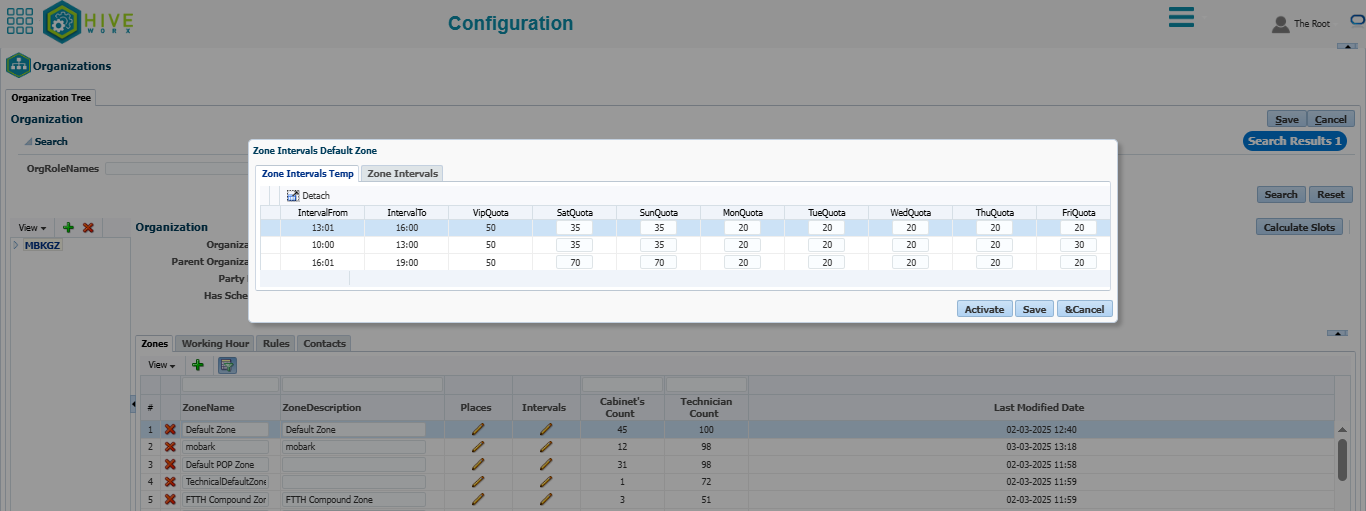


   📌 CR: CR-2025-220 | 1148x602


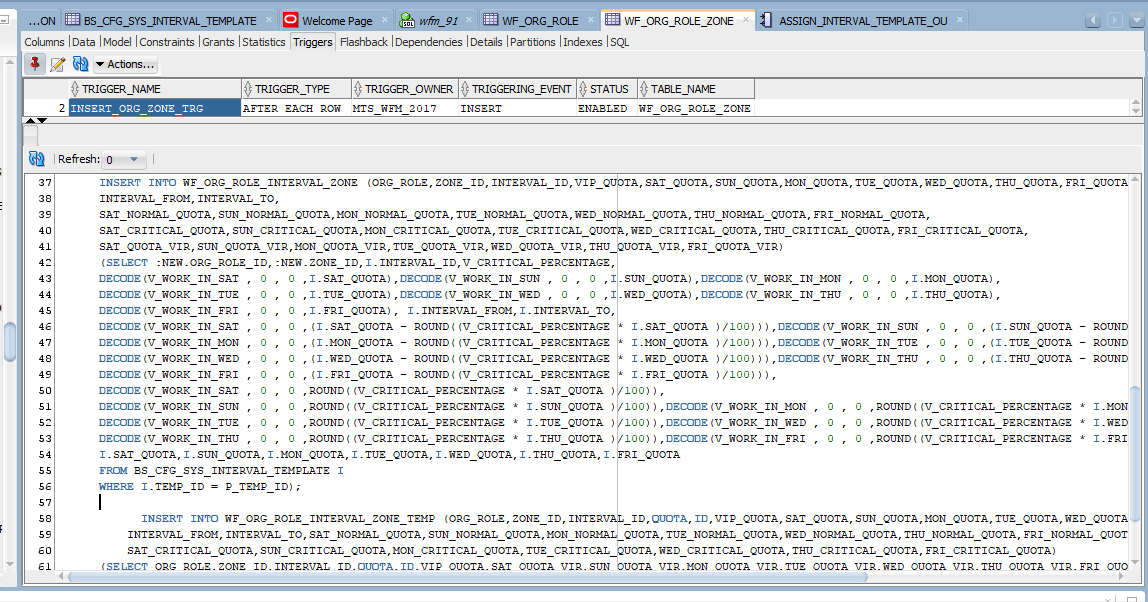


📄 Sources:
   - (PM-2024-126)WFM Scheduling Portal - FO Maintenance FRS (V0.
   - (CR-2025-220)WFM Automatic Scheduling Enhancement CR (V0.2).


In [4]:
ask("How does WFM handle no free slots in scheduling?",
    category="Scheduling")

In [3]:
# تجربة بسيطة الأول
response = gemini_client.models.generate_content(
    model="models/gemini-3.5-flash",
    contents="Say hello"
)
print(response.text)

Hello! How can I help you today?


In [8]:
# ============================================
# 🎨 Gradio GUI للـ End User
# ============================================
import gradio as gr
import os

def chat_response(
    message: str,
    category: str,
    history: list
):
    """
    بيرد على السؤال ويرجع:
    - الإجابة
    - الصور
    - الـ Sources
    """
    
    # اختيار الـ Category
    cat = None if category == "All" else category
    
    # Search
    chunks = hybrid_search(
        message,
        top_k=CONFIG["top_k"],
        category=cat
    )
    
    if not chunks:
        return (
            history + [[message, "❌ مش لاقي نتائج متعلقة"]],
            [],
            "No sources found"
        )
    
    # Generate Answer
    result = generate_answer_gemini(message, chunks)
    answer = result["answer"]
    
    # Sources
    seen    = set()
    sources = ""
    for chunk in chunks:
        fname = chunk['metadata']['filename']
        cr    = chunk['metadata']['cr_number']
        if fname not in seen:
            sources += f"📄 {fname[:50]}\n"
            sources += f"   CR: {cr}\n\n"
            seen.add(fname)
    
    # Images
    images = [img["path"] for img in result["images"]]
    
    # Update History
    history = history + [[message, answer]]
    
    return history, images, sources


def clear_chat():
    return [], [], ""


# ============================================
# 🎨 UI Design
# ============================================
with gr.Blocks(
    title="WFM Assistant",
    theme=gr.themes.Soft()
) as demo:
    
    # Header
    gr.Markdown("""
    # 🤖 WFM Intelligent Assistant
    ### Powered by RAG (Retrieval-Augmented Generation)
    Ask any question about WFM Change Requests and Documents
    """)
    
    with gr.Row():
        
        # =============================
        # Left Column: Chat
        # =============================
        with gr.Column(scale=2):
            
            chatbot = gr.Chatbot(
                label="💬 Chat",
                height=500,
                bubble_full_width=False,
                avatar_images=(
                    None,  # User
                    "https://img.icons8.com/color/48/bot.png"
                )
            )
            
            with gr.Row():
                msg = gr.Textbox(
                    label="Your Question",
                    placeholder="Ask about WFM...",
                    scale=4
                )
                submit_btn = gr.Button(
                    "Send 🚀",
                    variant="primary",
                    scale=1
                )
            
            with gr.Row():
                category = gr.Dropdown(
                    choices=[
                        "All",
                        "Scheduling",
                        "Maintenance",
                        "Installation",
                        "Service_Activation",
                        "Dashboard_Reports",
                        "Work_Orders",
                        "User_Management",
                        "Network",
                        "Device_Management",
                        "Other"
                    ],
                    value="All",
                    label="📁 Filter by Category",
                    scale=2
                )
                clear_btn = gr.Button(
                    "Clear 🗑️",
                    variant="secondary",
                    scale=1
                )
            
            # Example Questions
            gr.Examples(
                examples=[
                    ["What is the automatic scheduling enhancement?"],
                    ["How does WFM handle no free slots?"],
                    ["What is FTTH maintenance process flow?"],
                    ["What is force close work order?"],
                    ["What is KPI report for team leader?"],
                ],
                inputs=msg,
                label="📝 Example Questions"
            )
        
        # =============================
        # Right Column: Images & Sources
        # =============================
        with gr.Column(scale=1):
            
            gr.Markdown("### 🖼️ Related Process Flows")
            image_gallery = gr.Gallery(
                label="Process Flow Diagrams",
                show_label=False,
                height=300,
                columns=1,
                object_fit="contain"
            )
            
            gr.Markdown("### 📄 Sources")
            sources_box = gr.Textbox(
                label="",
                lines=10,
                interactive=False,
                placeholder="Sources will appear here..."
            )
    
    # =============================
    # Footer
    # =============================
    gr.Markdown("""
    ---
    **WFM RAG System** | Built with ❤️ 
    - 📊 143 Documents Indexed
    - 🔍 Hybrid Search (Dense + BM25 + RRF)
    - 🤖 Powered by Gemini AI
    """)
    
    # =============================
    # Events
    # =============================
    submit_btn.click(
        fn=chat_response,
        inputs=[msg, category, chatbot],
        outputs=[chatbot, image_gallery, sources_box]
    ).then(
        fn=lambda: "",
        outputs=msg
    )
    
    msg.submit(
        fn=chat_response,
        inputs=[msg, category, chatbot],
        outputs=[chatbot, image_gallery, sources_box]
    ).then(
        fn=lambda: "",
        outputs=msg
    )
    
    clear_btn.click(
        fn=clear_chat,
        outputs=[chatbot, image_gallery, sources_box]
    )




C:\Users\dell\AppData\Local\Temp\ipykernel_19544\2842715893.py:86: UserWarning: You have not specified a value for the `type` parameter. Defaulting to the 'tuples' format for chatbot messages, but this is deprecated and will be removed in a future version of Gradio. Please set type='messages' instead, which uses openai-style dictionaries with 'role' and 'content' keys.
  chatbot = gr.Chatbot(
C:\Users\dell\AppData\Local\Temp\ipykernel_19544\2842715893.py:86: DeprecationWarning: The 'bubble_full_width' parameter is deprecated and will be removed in a future version. This parameter no longer has any effect.
  chatbot = gr.Chatbot(


In [9]:
demo.launch(
    inline=True,  # ← داخل Jupyter
    share=False,
    show_error=True
)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


⚠️ models/gemini-3.5-flash: 503 UNAVAILABLE. {'error': {'code': 503,
⚠️ models/gemini-3.8-flash: 503 UNAVAILABLE. {'error': {'code': 503,
⚠️ models/gemini-3.7-flash: 503 UNAVAILABLE. {'error': {'code': 503,


In [14]:
# ============================================
# تحديث الـ Models وإعادة تشغيل الـ GUI
# ============================================
MODELS_TO_TRY = [
    "models/gemini-3.5-flash",
    "models/gemini-3.6-flash",
    "models/gemini-3.7-flash",
    "models/gemini-3.8-flash",
    "models/gemini-2.5-flash",
]

# أوقف الـ Demo القديم
try:
    demo.close()
except:
    pass

# إعادة تشغيل
demo.launch(
    inline=True,
    share=False,
    show_error=True
)

Closing server running on port: 7860
* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


Traceback (most recent call last):
  File "d:\Ai_generative\google_hakathon\.env\Lib\site-packages\gradio\queueing.py", line 626, in process_events
    response = await route_utils.call_process_api(
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "d:\Ai_generative\google_hakathon\.env\Lib\site-packages\gradio\route_utils.py", line 322, in call_process_api
    output = await app.get_blocks().process_api(
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "d:\Ai_generative\google_hakathon\.env\Lib\site-packages\gradio\blocks.py", line 2230, in process_api
    data = await self.postprocess_data(block_fn, result["prediction"], state)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "d:\Ai_generative\google_hakathon\.env\Lib\site-packages\gradio\blocks.py", line 2018, in postprocess_data
    await processing_utils.async_move_files_to_cache(
  File "d:\Ai_generative\google_hakathon\.env\Lib\site-packages\gradio\processing_utils.py", line 676

In [15]:
# أوقف الـ Demo القديم
try:
    demo.close()
except:
    pass

# إعادة تشغيل مع allowed_paths
demo.launch(
    inline=True,
    share=False,
    show_error=True,
    allowed_paths=[
        r"D:\internship\rag\images"  # ← الحل
    ]
)

Closing server running on port: 7860
* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [16]:
# ============================================
# 📄 قراءة النص حوالين الصورة
# ============================================
from docx import Document
from docx.oxml.ns import qn

def extract_images_with_context(file_path: str, 
                                 file_info: dict) -> list:
    """
    بيستخرج كل صورة مع النص اللي حواليها
    """
    images = []
    
    try:
        doc      = Document(file_path)
        elements = list(doc.element.body)
        
        for idx, element in enumerate(elements):
            
            # ابحث عن صور في الـ element
            pics = element.findall(
                './/' + qn('a:blip')
            )
            
            if not pics:
                continue
            
            # النص قبل الصورة (3 paragraphs)
            before_text = ""
            for j in range(max(0, idx-3), idx):
                el = elements[j]
                text = "".join(
                    n.text or "" 
                    for n in el.iter()
                    if n.tag.endswith('t')
                ).strip()
                if text:
                    before_text += text + " "
            
            # النص بعد الصورة (3 paragraphs)
            after_text = ""
            for j in range(
                idx+1, 
                min(len(elements), idx+4)
            ):
                el = elements[j]
                text = "".join(
                    n.text or ""
                    for n in el.iter()
                    if n.tag.endswith('t')
                ).strip()
                if text:
                    after_text += text + " "
            
            # النص الكامل حوالين الصورة
            context_text = (
                before_text + " " + after_text
            ).strip()
            
            # استخراج الصورة
            for pic_idx, blip in enumerate(pics):
                rId = blip.get(qn('r:embed'))
                if not rId:
                    continue
                
                try:
                    img_part = doc.part.rels[rId].target_part
                    img_data = img_part.blob
                    
                    # اسم الصورة
                    img_name = (
                        f"{Path(file_path).stem}"
                        f"_ctx_{idx}_{pic_idx}.png"
                    )
                    img_path = os.path.join(
                        CONFIG["images_path"],
                        img_name
                    )
                    
                    # حفظ الصورة
                    img = PILImage.open(
                        io.BytesIO(img_data)
                    )
                    img.save(img_path)
                    
                    images.append({
                        "image_path":      img_path,
                        "image_name":      img_name,
                        "cr_number":       file_info["cr_number"],
                        "category":        file_info["category"],
                        "doc_type":        file_info["type"],
                        "filename":        file_info["filename"],
                        "context_text":    context_text[:500],
                        "before_text":     before_text[:200],
                        "after_text":      after_text[:200],
                    })
                    
                except Exception as e:
                    continue
    
    except Exception as e:
        print(f"⚠️ Error: {e}")
    
    return images


# =============================
# 🧪 تجربة
# =============================
test_file = list(
    Path(CONFIG["docs_path"]).rglob("*.docx")
)[2]

print(f"🧪 Testing: {test_file.name}")

test_images = extract_images_with_context(
    str(test_file),
    {
        "cr_number": "CR-2025-220",
        "category":  "Scheduling",
        "type":      "CR_Document",
        "filename":  test_file.name
    }
)

print(f"✅ Found: {len(test_images)} images")
for img in test_images[:3]:
    print(f"\n📄 {img['image_name'][:40]}")
    print(f"   Context: {img['context_text'][:100]}...")

KeyError: 'docs_path'

In [19]:
# ============================================
# 📥 Re-index كل الصور مع Context
# ============================================

def reindex_all_images():
    
    with open("cleaned/final_files.json", "r",
              encoding="utf-8") as f:
        final_files = json.load(f)
    
    all_images = []
    errors     = []
    
    print(f"🚀 Re-indexing images for {len(final_files)} files...")
    
    for i, file_info in enumerate(final_files):
        
        filename = file_info["filename"]
        ext      = file_info["extension"]
        
        # بس الـ docx
        if ext != ".docx":
            continue
        
        # مسار الملف
        file_path = os.path.join(
            CONFIG["docs_path"],
            file_info["category"],
            file_info["cr_number"],
            file_info["type"],
            filename
        )
        
        if not os.path.exists(file_path):
            errors.append(filename)
            continue
        
        # استخراج الصور
        images = extract_images_with_context(
            file_path, file_info
        )
        
        # فلتر: بس الصور الكبيرة (Process Flows)
        filtered = []
        for img in images:
            if os.path.exists(img["image_path"]):
                if is_process_flow(img["image_path"]):
                    filtered.append(img)
        
        all_images.extend(filtered)
        
        if filtered:
            print(f"[{i+1}] {filename[:40]}"
                  f" → {len(filtered)} process flows")
    
    print(f"\n✅ Total Process Flow Images: {len(all_images)}")
    print(f"❌ Errors: {len(errors)}")
    
    # =============================
    # Embedding للـ Context
    # =============================
    print("\n⏳ Embedding image contexts...")
    
    for img in all_images:
        # Embed الـ context
        embedding = local_model.encode(
            img["context_text"],
            normalize_embeddings=True
        ).tolist()
        img["embedding"] = embedding
    
    # حفظ
    with open(
        f"{CONFIG['metadata_path']}/images_with_embeddings.json",
        "w", encoding="utf-8"
    ) as f:
        # مش هنحفظ الـ embedding (كبير جداً)
        images_to_save = []
        for img in all_images:
            img_copy = img.copy()
            img_copy.pop("embedding", None)
            images_to_save.append(img_copy)
        
        json.dump(images_to_save, f,
                  ensure_ascii=False, indent=2)
    
    # حفظ الـ embeddings منفصل
    embeddings_data = {
        img["image_path"]: img["embedding"]
        for img in all_images
    }
    
    np.save(
        f"{CONFIG['metadata_path']}/image_embeddings.npy",
        embeddings_data
    )
    
    print("✅ Saved!")
    return all_images


# شغّل
all_images_indexed = reindex_all_images()

🚀 Re-indexing images for 143 files...
[3] (CR-2024-136)WFM BOX Complain CR (V0.1). → 1 process flows
[11] WFM_Remove Reservation Activity-damaged  → 1 process flows
[12] CR-2025-209 WFM_Enterprise_Maintenance_( → 4 process flows
[21] WFM scheduling FTTH maintenance ATPs(FTT → 1 process flows
[23] PM-2024-168   WFM PH2 FO Technical Maint → 3 process flows
[26] WFM PH2 FO Technical Maintenance amendme → 1 process flows
[27] PM-2025-205  WFM_PH2_FO_Technical_Mainte → 1 process flows
[29] PM-2025-216_FTTH_Maintenance_-_Remove_ca → 2 process flows
[38] (CR-2024-166)WFM SA- Wrong Card  Port Am → 1 process flows
[39] CR-2025-209 WFM_Enterprise_Maintenance_( → 4 process flows
[43] CR-2025-229 TECH DOC WFM Automatic Sched → 3 process flows
[50] (CR-2025-_222) Technical_Solution for FT → 1 process flows
[51] (CR-2025-_222)_FTTH_Maintenance_-_Add_Ne → 1 process flows
[55] CR-2025-226 WFM Reserve Activation - No  → 1 process flows
[74] Add cables task to data maintenance work → 1 process flows
[77

In [20]:
# ============================================
# 🔍 Smart Image Search
# ============================================

# لود الـ images مع الـ embeddings
with open(
    f"{CONFIG['metadata_path']}/images_with_embeddings.json",
    "r", encoding="utf-8"
) as f:
    images_indexed = json.load(f)

# عمل embeddings للصور
print("⏳ Loading image embeddings...")
image_embeddings = []
for img in images_indexed:
    emb = local_model.encode(
        img["context_text"],
        normalize_embeddings=True
    ).tolist()
    image_embeddings.append(emb)

print(f"✅ Loaded {len(images_indexed)} images with embeddings")


def get_related_images_smart(
    query: str,
    chunks: list,
    top_k: int = 2
) -> list:
    """
    بيجيب الصور الأكثر تشابهاً مع السؤال
    """
    
    if not images_indexed:
        return []
    
    # CRs في النتائج
    result_crs = set(
        c["metadata"]["cr_number"]
        for c in chunks
    )
    
    # فلتر الصور بالـ CR
    relevant_images  = []
    relevant_embeddings = []
    
    for i, img in enumerate(images_indexed):
        if img["cr_number"] in result_crs:
            if os.path.exists(img["image_path"]):
                relevant_images.append(img)
                relevant_embeddings.append(
                    image_embeddings[i]
                )
    
    if not relevant_images:
        return []
    
    # Embed السؤال
    query_emb = local_model.encode(
        query,
        normalize_embeddings=True
    )
    
    # حساب الـ Similarity
    scores = []
    for i, img_emb in enumerate(relevant_embeddings):
        score = np.dot(query_emb, img_emb)
        scores.append((score, i))
    
    # Sort: الأعلى تشابهاً
    scores.sort(reverse=True)
    
    # رجّع أحسن top_k صور
    result = []
    for score, idx in scores[:top_k]:
        img = relevant_images[idx]
        info = analyze_image(img["image_path"])
        if info:
            result.append({
                "path":     img["image_path"],
                "cr":       img["cr_number"],
                "filename": img["image_name"],
                "size":     f"{info['width']}x{info['height']}",
                "score":    round(float(score), 3),
                "heading":  img.get("heading", ""),
                "context":  img.get("context_text", "")
            })
    
    return result


# =============================
# 🔄 تحديث generate_answer_gemini
# =============================
def generate_answer_gemini(query: str, chunks: list) -> dict:
    
    context = ""
    for i, chunk in enumerate(chunks, 1):
        context += f"\n[Source {i}]\n{chunk['text'][:700]}\n"
    
    prompt = f"""
You are a WFM (Workforce Management) expert assistant.

RULES:
1. Answer ONLY from provided sources
2. Be specific and detailed
3. List all important points
4. Never add info not in sources
5. Start answer directly

SOURCES:
{context}

QUESTION: {query}

DETAILED ANSWER:
"""
    
    for model_name in MODELS_TO_TRY:
        try:
            response = gemini_client.models.generate_content(
                model=model_name,
                contents=prompt
            )
            
            # Smart Image Search
            images = get_related_images_smart(query, chunks)
            
            return {
                "answer":     response.text,
                "images":     images,
                "num_images": len(images)
            }
        except Exception as e:
            print(f"⚠️ {model_name}: {str(e)[:40]}")
            continue
    
    return {
        "answer":     "❌ Models غير متاحة",
        "images":     [],
        "num_images": 0
    }


print("✅ Smart Image Search جاهز!")

# =============================
# 🧪 تجربة
# =============================
print("\n🧪 Testing Smart Image Search...")
chunks = hybrid_search(
    "What is the automatic scheduling enhancement?",
    top_k=7,
    category="Scheduling"
)

images = get_related_images_smart(
    "What is the automatic scheduling enhancement?",
    chunks
)

print(f"\n✅ Found: {len(images)} relevant images")
for img in images:
    print(f"\n📌 {img['filename'][:40]}")
    print(f"   Score:   {img['score']}")
    print(f"   CR:      {img['cr']}")
    print(f"   Heading: {img['heading']}")
    print(f"   Context: {img['context'][:80]}")

⏳ Loading image embeddings...
✅ Loaded 41 images with embeddings
✅ Smart Image Search جاهز!

🧪 Testing Smart Image Search...

✅ Found: 2 relevant images

📌 CR-2025-229 TECH DOC WFM Automatic Sched
   Score:   0.657
   CR:      CR-2025-220
   Heading: Introduction
   Context: Introduction CR-2025-220 Scheduling CR-2025-229 TECH DOC WFM Automatic Schedulin

📌 CR-2025-229 TECH DOC WFM Automatic Sched
   Score:   0.657
   CR:      CR-2025-220
   Heading: Introduction
   Context: Introduction CR-2025-220 Scheduling CR-2025-229 TECH DOC WFM Automatic Schedulin


In [21]:
def get_related_images_smart(
    query: str,
    chunks: list,
    top_k: int = 2
) -> list:
    
    if not images_indexed:
        return []
    
    result_crs = set(
        c["metadata"]["cr_number"]
        for c in chunks
    )
    
    relevant_images     = []
    relevant_embeddings = []
    
    for i, img in enumerate(images_indexed):
        if img["cr_number"] in result_crs:
            if os.path.exists(img["image_path"]):
                relevant_images.append(img)
                relevant_embeddings.append(
                    image_embeddings[i]
                )
    
    if not relevant_images:
        return []
    
    # Embed السؤال
    query_emb = local_model.encode(
        query, normalize_embeddings=True
    )
    
    # حساب الـ Similarity
    scores = []
    for i, img_emb in enumerate(relevant_embeddings):
        score = np.dot(query_emb, img_emb)
        scores.append((score, i))
    
    scores.sort(reverse=True)
    
    # رجّع أحسن top_k مع شيل التكرار
    result  = []
    seen_paths = set()  # ← شيل التكرار
    
    for score, idx in scores:
        if len(result) >= top_k:
            break
            
        img      = relevant_images[idx]
        img_path = img["image_path"]
        
        # شيل التكرار
        if img_path in seen_paths:
            continue
        seen_paths.add(img_path)
        
        info = analyze_image(img_path)
        if info:
            result.append({
                "path":     img_path,
                "cr":       img["cr_number"],
                "filename": img["image_name"],
                "size":     f"{info['width']}x{info['height']}",
                "score":    round(float(score), 3),
                "heading":  img.get("heading", ""),
                "context":  img.get("context_text", "")
            })
    
    return result


# =============================
# 🧪 تجربة
# =============================
print("🧪 Testing Fixed Smart Image Search...")
chunks = hybrid_search(
    "What is the automatic scheduling enhancement?",
    top_k=7,
    category="Scheduling"
)

images = get_related_images_smart(
    "What is the automatic scheduling enhancement?",
    chunks
)

print(f"\n✅ Found: {len(images)} unique images")
for img in images:
    print(f"\n📌 {img['filename'][:40]}")
    print(f"   Score:   {img['score']}")
    print(f"   CR:      {img['cr']}")
    print(f"   Size:    {img['size']}")

🧪 Testing Fixed Smart Image Search...

✅ Found: 2 unique images

📌 CR-2025-229 TECH DOC WFM Automatic Sched
   Score:   0.657
   CR:      CR-2025-220
   Size:    1366x511

📌 CR-2025-229 TECH DOC WFM Automatic Sched
   Score:   0.657
   CR:      CR-2025-220
   Size:    1148x602


📌 CR-2025-229 TECH DOC WFM Automatic Scheduling CR_r
   Score: 0.657 | Size: 1366x511


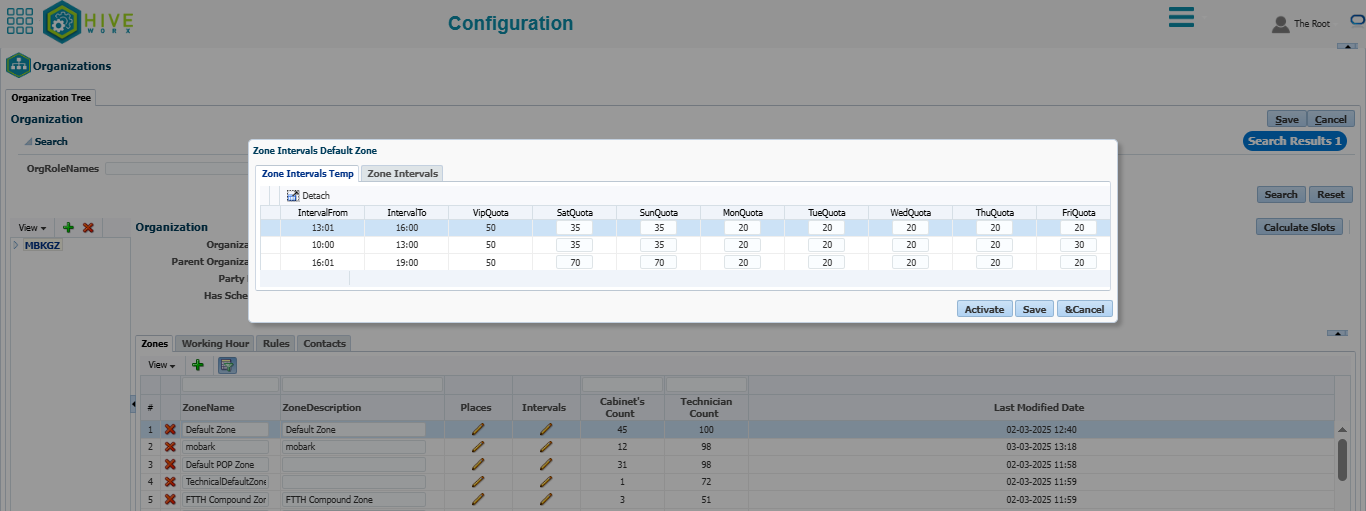


📌 CR-2025-229 TECH DOC WFM Automatic Scheduling CR_r
   Score: 0.657 | Size: 1148x602


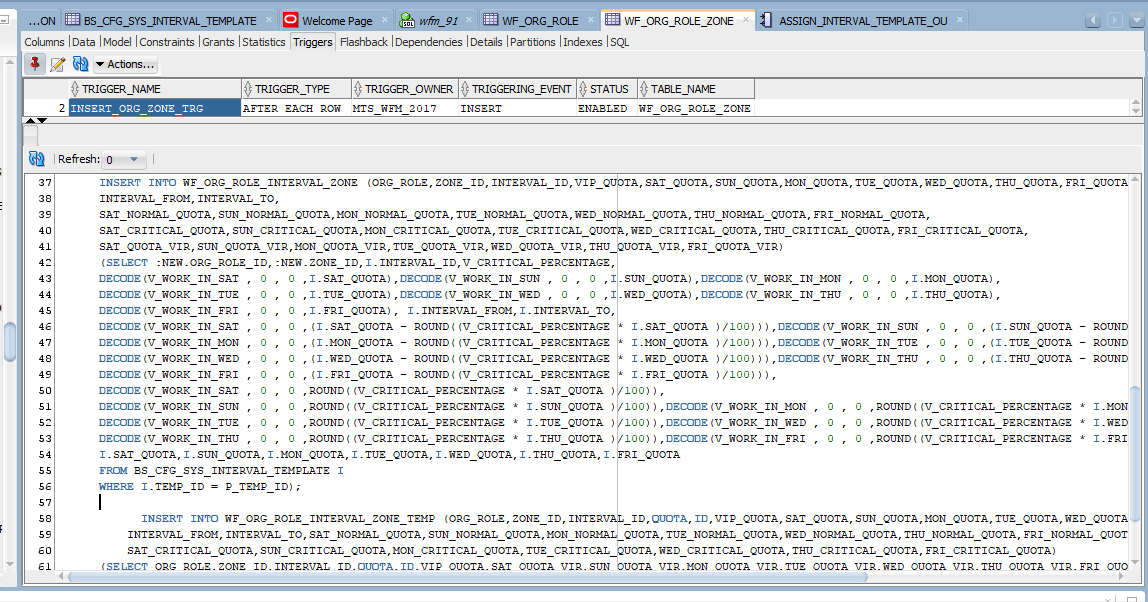

In [22]:
# عرض الصور
from IPython.display import display, Image as IPImage

for img in images:
    print(f"📌 {img['filename'][:50]}")
    print(f"   Score: {img['score']} | Size: {img['size']}")
    display(IPImage(filename=img['path'], width=600))
    print()

In [23]:
def extract_images_with_context(file_path: str,
                                 file_info: dict) -> list:
    images = []
    
    try:
        doc             = Document(file_path)
        current_heading = "Introduction"
        current_text    = ""
        heading_images  = {}
        
        # تتبع النص والـ Headings
        for para in doc.paragraphs:
            if para.style.name.startswith("Heading"):
                current_heading = para.text.strip()
                current_text    = ""
            else:
                current_text += " " + para.text.strip()
        
        # استخراج الصور
        for rel in doc.part.rels.values():
            if "image" not in rel.reltype:
                continue
            
            try:
                img_data = rel.target_part.blob
                img_name = (
                    f"{Path(file_path).stem}"
                    f"_{rel.rId}.png"
                )
                img_path = os.path.join(
                    CONFIG["images_path"],
                    img_name
                )
                
                img = PILImage.open(io.BytesIO(img_data))
                img.save(img_path)
                
                # Context أغنى
                context = (
                    f"{current_heading} "
                    f"{current_text[:200]} "
                    f"{file_info['cr_number']} "
                    f"{file_info['category']} "
                    f"{file_info['filename']}"
                ).strip()
                
                images.append({
                    "image_path":   img_path,
                    "image_name":   img_name,
                    "cr_number":    file_info["cr_number"],
                    "category":     file_info["category"],
                    "doc_type":     file_info["type"],
                    "filename":     file_info["filename"],
                    "context_text": context[:500],
                    "heading":      current_heading,
                })
                
            except:
                continue
    
    except Exception as e:
        print(f"⚠️ Error: {e}")
    
    return images


print("✅ Updated extract_images_with_context!")

✅ Updated extract_images_with_context!


In [24]:
# Re-index مع Context أحسن
all_images_indexed = reindex_all_images()

# تحديث الـ embeddings
image_embeddings = []
for img in images_indexed:
    emb = local_model.encode(
        img["context_text"],
        normalize_embeddings=True
    ).tolist()
    image_embeddings.append(emb)

print("✅ Re-indexed with better context!")

🚀 Re-indexing images for 143 files...
[3] (CR-2024-136)WFM BOX Complain CR (V0.1). → 1 process flows
[11] WFM_Remove Reservation Activity-damaged  → 1 process flows
[12] CR-2025-209 WFM_Enterprise_Maintenance_( → 4 process flows
[21] WFM scheduling FTTH maintenance ATPs(FTT → 1 process flows
[23] PM-2024-168   WFM PH2 FO Technical Maint → 3 process flows
[26] WFM PH2 FO Technical Maintenance amendme → 1 process flows
[27] PM-2025-205  WFM_PH2_FO_Technical_Mainte → 1 process flows
[29] PM-2025-216_FTTH_Maintenance_-_Remove_ca → 2 process flows
[38] (CR-2024-166)WFM SA- Wrong Card  Port Am → 1 process flows
[39] CR-2025-209 WFM_Enterprise_Maintenance_( → 4 process flows
[43] CR-2025-229 TECH DOC WFM Automatic Sched → 3 process flows
[50] (CR-2025-_222) Technical_Solution for FT → 1 process flows
[51] (CR-2025-_222)_FTTH_Maintenance_-_Add_Ne → 1 process flows
[55] CR-2025-226 WFM Reserve Activation - No  → 1 process flows
[74] Add cables task to data maintenance work → 1 process flows
[77

📌 Score: 0.657
   Heading: Introduction


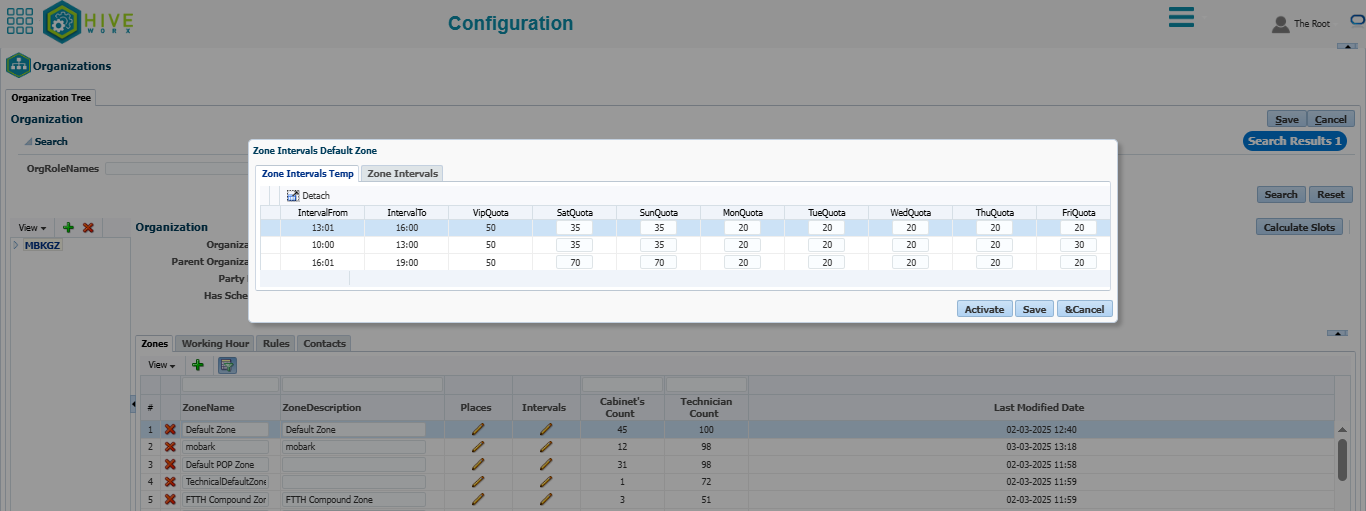

📌 Score: 0.657
   Heading: Introduction


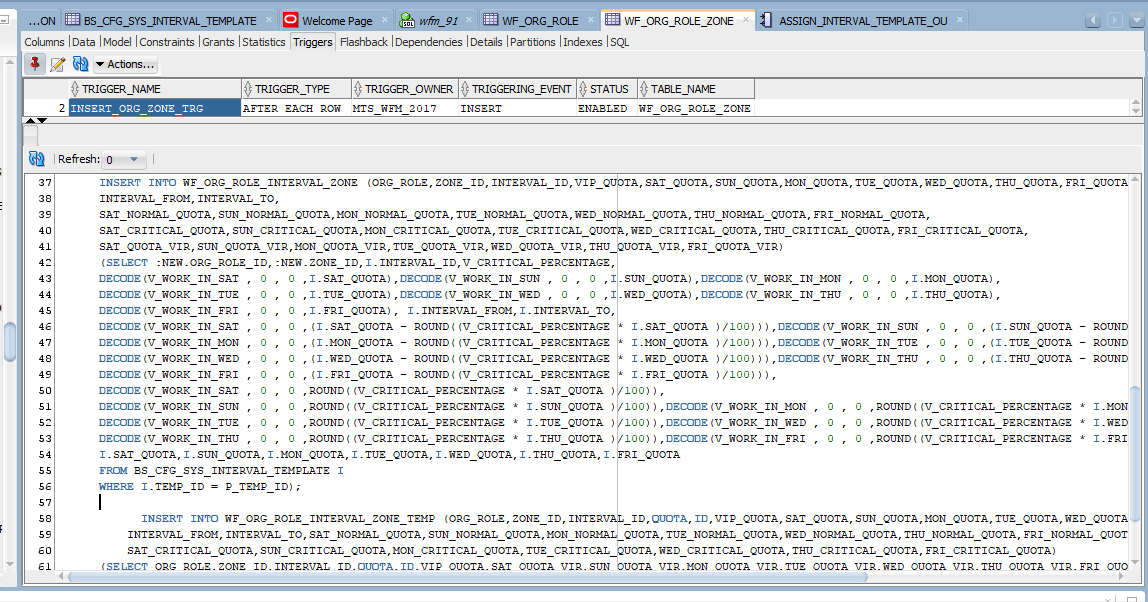

In [25]:
images = get_related_images_smart(
    "What is the automatic scheduling enhancement?",
    chunks
)

for img in images:
    print(f"📌 Score: {img['score']}")
    print(f"   Heading: {img['heading']}")
    display(IPImage(filename=img['path'], width=500))

# gemeni





In [ ]:
# ============================================
# 🚀 WFM RAG SYSTEM - FULL SETUP
# Version: 1.0
# ============================================

# ============================================
# 📦 1. IMPORTS
# ============================================
import os
import json
import io
import numpy as np
from pathlib import Path
from abc import ABC, abstractmethod
from sentence_transformers import SentenceTransformer
import chromadb
from rank_bm25 import BM25Okapi
from PIL import Image as PILImage
from IPython.display import display, Image as IPImage
import google.genai as genai
from docx import Document

# ============================================
# ⚙️ 2. CONFIGURATION
# ============================================
CONFIG = {
    # المسارات
    "model_path":    r"D:\internship\rag\model",
    "docs_path":     r"D:\internship\rag\p\WFM_CLEAN",
    "chroma_path":   r"D:\internship\rag\chroma_db",
    "images_path":   r"D:\internship\rag\images",
    "metadata_path": r"D:\internship\rag\metadata",
    
    # Gemini API
    "gemini_api_key": "",
    
    # Search
    "top_k":  7,
    "rrf_k":  60,
}

MODELS_TO_TRY = [
    "models/gemini-3.5-flash",
    "models/gemini-3.6-flash",
    "models/gemini-3.7-flash",
    "models/gemini-3.8-flash",
    "models/gemini-2.5-flash",
]

# ============================================
# 🏗️ 3. VECTOR DB ABSTRACTION LAYER
# ============================================
class VectorDB(ABC):
    @abstractmethod
    def add(self, ids, embeddings, documents, metadatas):
        pass
    @abstractmethod
    def search(self, query_embedding, n_results, filters):
        pass
    @abstractmethod
    def count(self):
        pass
    @abstractmethod
    def delete(self, ids):
        pass

class ChromaDB(VectorDB):
    def __init__(self, path: str):
        self.client = chromadb.PersistentClient(path=path)
        self.collection = self.client.get_or_create_collection(
            name="wfm_documents",
            metadata={"hnsw:space": "cosine"}
        )
    def add(self, ids, embeddings, documents, metadatas):
        self.collection.add(
            ids=ids,
            embeddings=embeddings,
            documents=documents,
            metadatas=metadatas
        )
    def search(self, query_embedding, n_results=10, filters=None):
        return self.collection.query(
            query_embeddings=[query_embedding],
            n_results=n_results,
            where=filters
        )
    def count(self):
        return self.collection.count()
    def delete(self, ids):
        self.collection.delete(ids=ids)

class QdrantDB(VectorDB):
    """جاهز للمستقبل لو قررنا نغير"""
    def __init__(self, path: str): pass
    def add(self, ids, embeddings, documents, metadatas): pass
    def search(self, query_embedding, n_results=10, filters=None): pass
    def count(self): pass
    def delete(self, ids): pass

# ============================================
# 🧠 4. LOAD MODELS
# ============================================
print("⏳ Loading Models...")

local_model = SentenceTransformer(
    CONFIG["model_path"],
    local_files_only=True
)
gemini_client = genai.Client(
    api_key=CONFIG["gemini_api_key"]
)
print("✅ Models جاهزة!")

# ============================================
# 🗄️ 5. LOAD VECTOR DB
# ============================================
print("⏳ Loading DB...")
db = ChromaDB(path=CONFIG["chroma_path"])
print(f"✅ DB جاهز! ({db.count()} chunks)")

# ============================================
# 📦 6. LOAD CHUNKS
# ============================================
print("⏳ Loading chunks...")
all_chunks = []

results = db.search(
    query_embedding=local_model.encode(
        "work order",
        normalize_embeddings=True
    ).tolist(),
    n_results=db.count(),
    filters=None
)

for i in range(len(results["ids"][0])):
    all_chunks.append({
        "chunk_id": results["ids"][0][i],
        "text":     results["documents"][0][i],
        "filename": results["metadatas"][0][i]["filename"],
        "category": results["metadatas"][0][i]["category"],
        "cr_number":results["metadatas"][0][i]["cr_number"],
        "heading":  results["metadatas"][0][i]["heading"],
    })

print(f"✅ Loaded: {len(all_chunks)} chunks")

# ============================================
# 🔍 7. BM25 INDEX
# ============================================
print("⏳ Building BM25...")
tokenized = [c["text"].lower().split() for c in all_chunks]
bm25      = BM25Okapi(tokenized)
print("✅ BM25 جاهز!")

# ============================================
# 🖼️ 8. LOAD IMAGE EMBEDDINGS
# ============================================
print("⏳ Loading image embeddings...")

images_meta_path = os.path.join(
    CONFIG["metadata_path"],
    "images_with_embeddings.json"
)

images_indexed   = []
image_embeddings = []

if os.path.exists(images_meta_path):
    with open(images_meta_path, "r", encoding="utf-8") as f:
        images_indexed = json.load(f)
    
    for img in images_indexed:
        emb = local_model.encode(
            img["context_text"],
            normalize_embeddings=True
        ).tolist()
        image_embeddings.append(emb)
    
    print(f"✅ Loaded {len(images_indexed)} images")
else:
    print("⚠️ No image embeddings found")

# ============================================
# 🔍 9. SEARCH FUNCTIONS
# ============================================
def rrf_fusion(dense_ids, bm25_ids, k=60):
    scores = {}
    for rank, doc_id in enumerate(dense_ids, 1):
        scores[doc_id] = scores.get(doc_id, 0) + 1/(k+rank)
    for rank, doc_id in enumerate(bm25_ids, 1):
        scores[doc_id] = scores.get(doc_id, 0) + 1/(k+rank)
    return sorted(scores, key=scores.get, reverse=True)


def hybrid_search(query, top_k=7, category=None):
    query_embedding = local_model.encode(
        query, normalize_embeddings=True
    ).tolist()
    filters     = {"category": category} if category else None
    dense_res   = db.search(query_embedding, top_k*2, filters)
    dense_ids   = dense_res["ids"][0]
    dense_docs  = dense_res["documents"][0]
    dense_meta  = dense_res["metadatas"][0]
    bm25_scores = bm25.get_scores(query.lower().split())
    bm25_top    = np.argsort(-bm25_scores)[:top_k*2]
    bm25_ids    = [all_chunks[i]["chunk_id"] for i in bm25_top]
    fused_ids   = rrf_fusion(dense_ids, bm25_ids)
    results     = []
    seen        = set()
    for chunk_id in fused_ids[:top_k]:
        if chunk_id in dense_ids and chunk_id not in seen:
            idx = dense_ids.index(chunk_id)
            results.append({
                "chunk_id": chunk_id,
                "text":     dense_docs[idx],
                "metadata": dense_meta[idx],
            })
            seen.add(chunk_id)
    return results

# ============================================
# 🖼️ 10. IMAGE FUNCTIONS
# ============================================
def analyze_image(img_path: str) -> dict:
    try:
        with PILImage.open(img_path) as im:
            w, h       = im.size
            img_array  = np.array(im.convert('RGB'))
            brightness = img_array.mean()
            small      = im.resize((100, 100))
            small_arr  = np.array(small.convert('RGB'))
            unique     = len(np.unique(
                small_arr.reshape(-1, 3), axis=0
            ))
            return {
                "width":         w,
                "height":        h,
                "ratio":         w/h,
                "pixels":        w*h,
                "brightness":    brightness,
                "color_variety": unique/10000,
            }
    except:
        return None


def is_process_flow(img_path: str) -> bool:
    info = analyze_image(img_path)
    if not info:                              return False
    if info["pixels"] < 400000:              return False
    if info["ratio"] > 3.0 or \
       info["ratio"] < 0.5:                  return False
    if info["brightness"] < 150:             return False
    if info["color_variety"] < 0.05:         return False
    if info["brightness"] > 245:             return False
    return True


def get_related_images_smart(
    query: str,
    chunks: list,
    top_k: int = 2
) -> list:
    
    if not images_indexed:
        return []
    
    result_crs = set(
        c["metadata"]["cr_number"] for c in chunks
    )
    
    relevant_imgs = []
    relevant_embs = []
    
    for i, img in enumerate(images_indexed):
        if img["cr_number"] in result_crs:
            if os.path.exists(img["image_path"]):
                relevant_imgs.append(img)
                relevant_embs.append(image_embeddings[i])
    
    if not relevant_imgs:
        return []
    
    query_emb = local_model.encode(
        query, normalize_embeddings=True
    )
    
    scores = [
        (np.dot(query_emb, emb), i)
        for i, emb in enumerate(relevant_embs)
    ]
    scores.sort(reverse=True)
    
    result     = []
    seen_paths = set()
    
    for score, idx in scores:
        if len(result) >= top_k:
            break
        
        img      = relevant_imgs[idx]
        img_path = img["image_path"]
        
        if img_path in seen_paths:
            continue
        seen_paths.add(img_path)
        
        if not is_process_flow(img_path):
            continue
        
        info = analyze_image(img_path)
        if info:
            result.append({
                "path":    img_path,
                "cr":      img["cr_number"],
                "filename":img["image_name"],
                "size":    f"{info['width']}x{info['height']}",
                "score":   round(float(score), 3),
                "heading": img.get("heading", ""),
            })
    
    return result

# ============================================
# 🤖 11. GENERATE ANSWER
# ============================================
def generate_answer_gemini(query: str, chunks: list) -> dict:
    
    context = ""
    for i, chunk in enumerate(chunks, 1):
        context += f"\n[Source {i}]\n{chunk['text'][:700]}\n"
    
    prompt = f"""
You are a WFM (Workforce Management) expert assistant.

RULES:
1. Answer ONLY from provided sources
2. Be specific and detailed
3. List all important points
4. Never add info not in sources
5. Start answer directly

SOURCES:
{context}

QUESTION: {query}

DETAILED ANSWER:
"""
    
    for model_name in MODELS_TO_TRY:
        try:
            response = gemini_client.models.generate_content(
                model=model_name,
                contents=prompt
            )
            images = get_related_images_smart(query, chunks)
            return {
                "answer":     response.text,
                "images":     images,
                "num_images": len(images)
            }
        except Exception as e:
            print(f"⚠️ {model_name}: {str(e)[:40]}")
            continue
    
    return {
        "answer":     "❌ Models غير متاحة",
        "images":     [],
        "num_images": 0
    }

# ============================================
# 🔍 12. ASK FUNCTION
# ============================================
def ask(query: str, category: str = None):
    
    chunks = hybrid_search(
        query,
        top_k=CONFIG["top_k"],
        category=category
    )
    
    print(f"\n🔍 Query: {query}")
    print(f"📚 Context: {len(chunks)} chunks")
    print("\n🤖 Answer:")
    print("=" * 60)
    
    result = generate_answer_gemini(query, chunks)
    print(result["answer"])
    
    if result["images"]:
        print(f"\n🖼️ Process Flows ({result['num_images']}):")
        for img in result["images"]:
            print(f"\n   📌 CR: {img['cr']}"
                  f" | Score: {img['score']}"
                  f" | Size: {img['size']}")
            try:
                display(IPImage(
                    filename=img['path'], width=600
                ))
            except Exception as e:
                print(f"      ⚠️ {e}")
    else:
        print("\n🖼️ No Process Flows found")
    
    print("\n📄 Sources:")
    seen = set()
    for chunk in chunks:
        fname = chunk['metadata']['filename']
        if fname not in seen:
            print(f"   - {fname[:60]}")
            seen.add(fname)

# ============================================
# 🎨 13. GRADIO GUI
# ============================================
def launch_gui():
    import gradio as gr
    
    def chat_response(message, category, history):
        cat    = None if category == "All" else category
        chunks = hybrid_search(
            message,
            top_k=CONFIG["top_k"],
            category=cat
        )
        
        if not chunks:
            history.append({
                "role": "user", "content": message
            })
            history.append({
                "role": "assistant",
                "content": "❌ مش لاقي نتائج متعلقة"
            })
            return history, [], "No sources found"
        
        result = generate_answer_gemini(message, chunks)
        
        seen    = set()
        sources = ""
        for chunk in chunks:
            fname = chunk['metadata']['filename']
            cr    = chunk['metadata']['cr_number']
            if fname not in seen:
                sources += f"📄 {fname[:50]}\n"
                sources += f"   CR: {cr}\n\n"
                seen.add(fname)
        
        images = [img["path"] for img in result["images"]]
        
        history.append({
            "role": "user", "content": message
        })
        history.append({
            "role": "assistant",
            "content": result["answer"]
        })
        
        return history, images, sources
    
    def clear_chat():
        return [], [], ""
    
    with gr.Blocks(
        title="WFM Assistant",
        theme=gr.themes.Soft()
    ) as demo:
        
        gr.Markdown("""
        # 🤖 WFM Intelligent Assistant
        ### Powered by RAG (Retrieval-Augmented Generation)
        """)
        
        with gr.Row():
            with gr.Column(scale=2):
                chatbot = gr.Chatbot(
                    label="💬 Chat",
                    height=500,
                    type="messages"
                )
                with gr.Row():
                    msg = gr.Textbox(
                        label="Your Question",
                        placeholder="Ask about WFM...",
                        scale=4
                    )
                    submit_btn = gr.Button(
                        "Send 🚀",
                        variant="primary",
                        scale=1
                    )
                with gr.Row():
                    category = gr.Dropdown(
                        choices=[
                            "All", "Scheduling",
                            "Maintenance", "Installation",
                            "Service_Activation",
                            "Dashboard_Reports",
                            "Work_Orders",
                            "User_Management",
                            "Network",
                            "Device_Management", "Other"
                        ],
                        value="All",
                        label="📁 Filter by Category",
                        scale=2
                    )
                    clear_btn = gr.Button(
                        "Clear 🗑️",
                        variant="secondary",
                        scale=1
                    )
                gr.Examples(
                    examples=[
                        ["What is automatic scheduling enhancement?"],
                        ["How does WFM handle no free slots?"],
                        ["What is FTTH maintenance process flow?"],
                        ["What is force close work order?"],
                        ["What is KPI report for team leader?"],
                    ],
                    inputs=msg,
                    label="📝 Example Questions"
                )
            
            with gr.Column(scale=1):
                gr.Markdown("### 🖼️ Related Process Flows")
                image_gallery = gr.Gallery(
                    show_label=False,
                    height=300,
                    columns=1,
                    object_fit="contain"
                )
                gr.Markdown("### 📄 Sources")
                sources_box = gr.Textbox(
                    label="",
                    lines=10,
                    interactive=False,
                    placeholder="Sources will appear here..."
                )
        
        gr.Markdown("""
        ---
        **WFM RAG System** | 📊 143 Docs | 
        🔍 Hybrid Search | 🤖 Gemini AI
        """)
        
        submit_btn.click(
            fn=chat_response,
            inputs=[msg, category, chatbot],
            outputs=[chatbot, image_gallery, sources_box]
        ).then(fn=lambda: "", outputs=msg)
        
        msg.submit(
            fn=chat_response,
            inputs=[msg, category, chatbot],
            outputs=[chatbot, image_gallery, sources_box]
        ).then(fn=lambda: "", outputs=msg)
        
        clear_btn.click(
            fn=clear_chat,
            outputs=[chatbot, image_gallery, sources_box]
        )
    
    demo.launch(
        inline=True,
        share=False,
        show_error=True,
        allowed_paths=[CONFIG["images_path"]]
    )

# ============================================
# ✅ READY
# ============================================
print("\n" + "=" * 50)
print("✅ WFM RAG SYSTEM جاهز!")
print(f"📊 Chunks:  {len(all_chunks)}")
print(f"🖼️  Images:  {len(images_indexed)}")
print(f"🔍 Top K:   {CONFIG['top_k']}")
print("=" * 50)
print("\nللاستخدام:")
print("  ask('your question')")
print("  ask('your question', category='Scheduling')")
print("  launch_gui()")

⏳ Loading Models...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

✅ Models جاهزة!
⏳ Loading DB...
✅ DB جاهز! (957 chunks)
⏳ Loading chunks...
✅ Loaded: 957 chunks
⏳ Building BM25...
✅ BM25 جاهز!
⏳ Loading image embeddings...
✅ Loaded 41 images

✅ WFM RAG SYSTEM جاهز!
📊 Chunks:  957
🖼️  Images:  41
🔍 Top K:   7

للاستخدام:
  ask('your question')
  ask('your question', category='Scheduling')
  launch_gui()


In [ ]:
def generate_answer_gemini(query: str, chunks: list) -> dict:
    
    context = ""
    for i, chunk in enumerate(chunks, 1):
        context += f"\n[Source {i}]\n{chunk['text'][:700]}\n"
    
    prompt = f"""
You are a WFM expert assistant.
Answer ONLY from provided sources.
Be specific and detailed.
Start answer directly.

SOURCES:
{context}

QUESTION: {query}

ANSWER:
"""
    
    # جرب الـ Models واحد واحد
    for model_name in MODELS_TO_TRY:
        try:
            response = gemini_client.models.generate_content(
                model=model_name,
                contents=prompt
            )
            # ← استنى ثانيتين بعد كل نجاح
            time.sleep(2)
            
            images = get_related_images_smart(query, chunks)
            return {
                "answer":     response.text,
                "images":     images,
                "num_images": len(images)
            }
            
        except Exception as e:
            error_str = str(e)
            print(f"⚠️ {model_name}: {error_str[:50]}")
            
            if "429" in error_str:
                # استخرج الـ retry delay من الـ error
                import re
                retry_match = re.search(
                    r'retry_delay.*?(\d+)', 
                    error_str
                )
                if retry_match:
                    wait = int(retry_match.group(1)) + 5
                else:
                    wait = 60
                print(f"   ⏳ Waiting {wait}s...")
                time.sleep(wait)
                
            elif "503" in error_str:
                print("   ⏳ Waiting 10s...")
                time.sleep(10)
            
            continue
    
    return {
        "answer":     "❌ Models غير متاحة",
        "images":     [],
        "num_images": 0
    }


def run_full_evaluation(test_set, k=5):
    
    retrieval_results = []
    answer_results    = []
    
    print("🚀 Starting Full Evaluation...")
    print(f"📊 Total: {len(test_set)} questions")
    print("=" * 60)
    
    for i, test in enumerate(test_set):
        
        query    = test["question"]
        relevant = test["relevant_crs"]
        category = test["category"]
        
        print(f"\n{'='*60}")
        print(f"[{i+1}/{len(test_set)}] {query}")
        print(f"Category: {category}")
        print(f"{'='*60}")
        
        # Retrieval
        ret_start = time.time()
        chunks    = hybrid_search(query, top_k=k, category=category)
        ret_lat   = time.time() - ret_start
        
        retrieved_crs = [c["metadata"]["cr_number"] for c in chunks]
        hits      = sum(1 for r in relevant if r in retrieved_crs)
        recall    = hits / len(relevant)
        precision = hits / k
        mrr       = 0
        for rank, cr in enumerate(retrieved_crs, 1):
            if cr in relevant:
                mrr = 1 / rank
                break
        
        retrieval_results.append({
            "question":  query,
            "category":  category,
            "recall":    round(recall, 3),
            "precision": round(precision, 3),
            "mrr":       round(mrr, 3),
            "latency":   round(ret_lat, 3),
            "retrieved": retrieved_crs,
            "relevant":  relevant
        })
        
        print(f"\n📊 Retrieval:")
        print(f"   Recall@{k}:  {recall:.2f}")
        print(f"   Precision:  {precision:.2f}")
        print(f"   MRR:        {mrr:.2f}")
        print(f"   Latency:    {ret_lat:.2f}s")
        
        # Answer
        ans_start = time.time()
        result    = generate_answer_gemini(query, chunks)
        ans_lat   = time.time() - ans_start
        answer    = result["answer"]
        
        # Metrics
        context_words = set(
            " ".join([c["text"] for c in chunks]).lower().split()
        )
        answer_words  = set(answer.lower().split())
        faithfulness  = min(
            len(context_words & answer_words) /
            max(len(answer_words), 1), 1.0
        )
        query_words   = set(query.lower().split())
        relevance     = min(
            len(query_words & answer_words) /
            max(len(query_words), 1), 1.0
        )
        
        answer_results.append({
            "question":     query,
            "category":     category,
            "answer":       answer[:500],
            "faithfulness": round(faithfulness, 3),
            "relevance":    round(relevance, 3),
            "latency":      round(ans_lat, 3),
            "num_images":   result["num_images"]
        })
        
        print(f"\n🤖 Answer:")
        print("-" * 40)
        print(answer[:300] + "..." if len(answer) > 300 else answer)
        
        print(f"\n📊 Metrics:")
        print(f"   Faithfulness: {faithfulness:.2f}")
        print(f"   Relevance:    {relevance:.2f}")
        print(f"   Latency:      {ans_lat:.2f}s")
        print(f"   Images:       {result['num_images']}")
        
        # الصور
        if result["images"]:
            print(f"\n🖼️ Process Flows:")
            for img in result["images"]:
                print(f"   CR: {img['cr']}"
                      f" | Score: {img['score']}")
                try:
                    display(IPImage(
                        filename=img['path'], width=400
                    ))
                except:
                    pass
        
        # Sources
        print("\n📄 Sources:")
        seen = set()
        for chunk in chunks:
            fname = chunk['metadata']['filename']
            if fname not in seen:
                print(f"   - {fname[:55]}")
                seen.add(fname)
        
        # حفظ تدريجي بعد كل سؤال
        partial = {
            "completed": i + 1,
            "total":     len(test_set),
            "retrieval_details": retrieval_results,
            "answer_details":    answer_results
        }
        with open("evaluation/partial_results.json",
                  "w", encoding="utf-8") as f:
            json.dump(partial, f, ensure_ascii=False, indent=2)
    
    # Final Summary
    print("\n" + "=" * 60)
    print("📊 FINAL RESULTS")
    print("=" * 60)
    
    avg_recall    = np.mean([r["recall"]       for r in retrieval_results])
    avg_precision = np.mean([r["precision"]    for r in retrieval_results])
    avg_mrr       = np.mean([r["mrr"]          for r in retrieval_results])
    avg_ret_lat   = np.mean([r["latency"]      for r in retrieval_results])
    avg_faith     = np.mean([r["faithfulness"] for r in answer_results])
    avg_rel       = np.mean([r["relevance"]    for r in answer_results])
    avg_ans_lat   = np.mean([r["latency"]      for r in answer_results])
    
    print(f"\n🔍 RETRIEVAL (k={k}):")
    print(f"   Recall@{k}:    {avg_recall:.3f}")
    print(f"   Precision@{k}: {avg_precision:.3f}")
    print(f"   MRR:           {avg_mrr:.3f}")
    print(f"   Latency:       {avg_ret_lat:.3f}s")
    
    print(f"\n🤖 ANSWER QUALITY:")
    print(f"   Faithfulness:  {avg_faith:.3f}")
    print(f"   Relevance:     {avg_rel:.3f}")
    print(f"   Latency:       {avg_ans_lat:.3f}s")
    
    print(f"\n📁 BY CATEGORY:")
    categories = set(r["category"] for r in retrieval_results)
    for cat in sorted(categories):
        cat_res    = [r for r in retrieval_results if r["category"] == cat]
        cat_recall = np.mean([r["recall"] for r in cat_res])
        cat_mrr    = np.mean([r["mrr"]    for r in cat_res])
        print(f"   {cat:<25} Recall: {cat_recall:.2f} | MRR: {cat_mrr:.2f}")
    
    final = {
        "summary": {
            "retrieval": {
                "recall":    round(avg_recall, 3),
                "precision": round(avg_precision, 3),
                "mrr":       round(avg_mrr, 3),
                "latency":   round(avg_ret_lat, 3)
            },
            "answer_quality": {
                "faithfulness": round(avg_faith, 3),
                "relevance":    round(avg_rel, 3),
                "latency":      round(avg_ans_lat, 3)
            }
        },
        "by_category": {
            cat: {
                "recall": round(np.mean([
                    r["recall"] for r in retrieval_results
                    if r["category"] == cat]), 3),
                "mrr": round(np.mean([
                    r["mrr"] for r in retrieval_results
                    if r["category"] == cat]), 3)
            }
            for cat in categories
        },
        "retrieval_details": retrieval_results,
        "answer_details":    answer_results
    }
    
    with open("evaluation/full_evaluation.json",
              "w", encoding="utf-8") as f:
        json.dump(final, f, ensure_ascii=False, indent=2)
    
    print("\n✅ Saved: evaluation/full_evaluation.json")
    return final


# شغّل
eval_results = run_full_evaluation(test_set, k=5)

🚀 Starting Full Evaluation...
📊 Total: 20 questions

[1/20] What is the automatic scheduling enhancement?
Category: Scheduling

📊 Retrieval:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        0.50
   Latency:    0.18s
⚠️ models/gemini-3.5-flash: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'm
   ⏳ Waiting 60s...


In [4]:
 launch_gui()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


⚠️ models/gemini-3.5-flash: 429 RESOURCE_EXHAUSTED. {'error': {'code
⚠️ models/gemini-3.6-flash: 429 RESOURCE_EXHAUSTED. {'error': {'code
⚠️ models/gemini-3.7-flash: 429 RESOURCE_EXHAUSTED. {'error': {'code
⚠️ models/gemini-3.8-flash: 429 RESOURCE_EXHAUSTED. {'error': {'code
⚠️ models/gemini-2.5-flash: 404 NOT_FOUND. {'error': {'code': 404, '
⚠️ models/gemini-3.5-flash: 429 RESOURCE_EXHAUSTED. {'error': {'code
⚠️ models/gemini-3.6-flash: 429 RESOURCE_EXHAUSTED. {'error': {'code
⚠️ models/gemini-3.7-flash: 429 RESOURCE_EXHAUSTED. {'error': {'code
⚠️ models/gemini-3.8-flash: 429 RESOURCE_EXHAUSTED. {'error': {'code
⚠️ models/gemini-2.5-flash: 404 NOT_FOUND. {'error': {'code': 404, '


# groq

In [ ]:
# ============================================
# 🚀 WFM RAG SYSTEM - FULL SETUP
# Version: 2.0 (Groq + Gemini)
# ============================================

# ============================================
# 📦 1. IMPORTS
# ============================================
import os
import json
import io
import time
import numpy as np
from pathlib import Path
from abc import ABC, abstractmethod
from sentence_transformers import SentenceTransformer
import chromadb
from rank_bm25 import BM25Okapi
from PIL import Image as PILImage
from IPython.display import display, Image as IPImage
import google.genai as genai
from groq import Groq
from docx import Document

# ============================================
# ⚙️ 2. CONFIGURATION
# ============================================
CONFIG = {
    "model_path":    r"D:\internship\rag\model",
    "docs_path":     r"D:\internship\rag\p\WFM_CLEAN",
    "chroma_path":   r"D:\internship\rag\chroma_db",
    "images_path":   r"D:\internship\rag\images",
    "metadata_path": r"D:\internship\rag\metadata",
    "gemini_api_key": "",
    "groq_api_key":   "",
    "top_k":  7,
    "rrf_k":  60,
}

# Gemini Models
GEMINI_MODELS = [
    "models/gemini-3.5-flash",
    "models/gemini-3.6-flash",
    "models/gemini-3.7-flash",
    "models/gemini-3.8-flash",
]

# ← التعديل هنا
GROQ_MODELS = [
    "openai/gpt-oss-120b",
    "openai/gpt-oss-20b",
    "qwen/qwen3.8-27b",
]

# ============================================
# 🏗️ 3. VECTOR DB ABSTRACTION LAYER
# ============================================
class VectorDB(ABC):
    @abstractmethod
    def add(self, ids, embeddings, documents, metadatas):
        pass
    @abstractmethod
    def search(self, query_embedding, n_results, filters):
        pass
    @abstractmethod
    def count(self):
        pass
    @abstractmethod
    def delete(self, ids):
        pass

class ChromaDB(VectorDB):
    def __init__(self, path: str):
        self.client = chromadb.PersistentClient(path=path)
        self.collection = self.client.get_or_create_collection(
            name="wfm_documents",
            metadata={"hnsw:space": "cosine"}
        )
    def add(self, ids, embeddings, documents, metadatas):
        self.collection.add(
            ids=ids,
            embeddings=embeddings,
            documents=documents,
            metadatas=metadatas
        )
    def search(self, query_embedding, n_results=10, filters=None):
        return self.collection.query(
            query_embeddings=[query_embedding],
            n_results=n_results,
            where=filters
        )
    def count(self):
        return self.collection.count()
    def delete(self, ids):
        self.collection.delete(ids=ids)

class QdrantDB(VectorDB):
    """جاهز للمستقبل"""
    def __init__(self, path: str): pass
    def add(self, ids, embeddings, documents, metadatas): pass
    def search(self, query_embedding, n_results=10, filters=None): pass
    def count(self): pass
    def delete(self, ids): pass

# ============================================
# 🧠 4. LOAD MODELS
# ============================================
print("⏳ Loading Models...")

local_model = SentenceTransformer(
    CONFIG["model_path"],
    local_files_only=True
)
print("✅ Embedding Model جاهز!")

gemini_client = genai.Client(api_key=CONFIG["gemini_api_key"])
print("✅ Gemini Client جاهز!")

groq_client = Groq(api_key=CONFIG["groq_api_key"])
print("✅ Groq Client جاهز!")

# ============================================
# 🗄️ 5. LOAD VECTOR DB
# ============================================
print("⏳ Loading DB...")
db = ChromaDB(path=CONFIG["chroma_path"])
print(f"✅ DB جاهز! ({db.count()} chunks)")

# ============================================
# 📦 6. LOAD CHUNKS
# ============================================
print("⏳ Loading chunks...")
all_chunks = []

results = db.search(
    query_embedding=local_model.encode(
        "work order", normalize_embeddings=True
    ).tolist(),
    n_results=db.count(),
    filters=None
)

for i in range(len(results["ids"][0])):
    all_chunks.append({
        "chunk_id": results["ids"][0][i],
        "text":     results["documents"][0][i],
        "filename": results["metadatas"][0][i]["filename"],
        "category": results["metadatas"][0][i]["category"],
        "cr_number":results["metadatas"][0][i]["cr_number"],
        "heading":  results["metadatas"][0][i]["heading"],
    })

print(f"✅ Loaded: {len(all_chunks)} chunks")

# ============================================
# 🔍 7. BM25 INDEX
# ============================================
print("⏳ Building BM25...")
tokenized = [c["text"].lower().split() for c in all_chunks]
bm25      = BM25Okapi(tokenized)
print("✅ BM25 جاهز!")

# ============================================
# 🖼️ 8. LOAD IMAGE EMBEDDINGS
# ============================================
print("⏳ Loading image embeddings...")

images_meta_path = os.path.join(
    CONFIG["metadata_path"],
    "images_with_embeddings.json"
)

images_indexed   = []
image_embeddings = []

if os.path.exists(images_meta_path):
    with open(images_meta_path, "r", encoding="utf-8") as f:
        images_indexed = json.load(f)
    for img in images_indexed:
        emb = local_model.encode(
            img["context_text"], normalize_embeddings=True
        ).tolist()
        image_embeddings.append(emb)
    print(f"✅ Loaded {len(images_indexed)} images")
else:
    print("⚠️ No image embeddings found")

# ============================================
# 🔍 9. SEARCH FUNCTIONS
# ============================================
def rrf_fusion(dense_ids, bm25_ids, k=60):
    scores = {}
    for rank, doc_id in enumerate(dense_ids, 1):
        scores[doc_id] = scores.get(doc_id, 0) + 1/(k+rank)
    for rank, doc_id in enumerate(bm25_ids, 1):
        scores[doc_id] = scores.get(doc_id, 0) + 1/(k+rank)
    return sorted(scores, key=scores.get, reverse=True)

def hybrid_search(query, top_k=7, category=None):
    query_embedding = local_model.encode(
        query, normalize_embeddings=True
    ).tolist()
    filters     = {"category": category} if category else None
    dense_res   = db.search(query_embedding, top_k*2, filters)
    dense_ids   = dense_res["ids"][0]
    dense_docs  = dense_res["documents"][0]
    dense_meta  = dense_res["metadatas"][0]
    bm25_scores = bm25.get_scores(query.lower().split())
    bm25_top    = np.argsort(-bm25_scores)[:top_k*2]
    bm25_ids    = [all_chunks[i]["chunk_id"] for i in bm25_top]
    fused_ids   = rrf_fusion(dense_ids, bm25_ids)
    results     = []
    seen        = set()
    for chunk_id in fused_ids[:top_k]:
        if chunk_id in dense_ids and chunk_id not in seen:
            idx = dense_ids.index(chunk_id)
            results.append({
                "chunk_id": chunk_id,
                "text":     dense_docs[idx],
                "metadata": dense_meta[idx],
            })
            seen.add(chunk_id)
    return results

# ============================================
# 🖼️ 10. IMAGE FUNCTIONS
# ============================================
def analyze_image(img_path: str) -> dict:
    try:
        with PILImage.open(img_path) as im:
            w, h       = im.size
            img_array  = np.array(im.convert('RGB'))
            brightness = img_array.mean()
            small      = im.resize((100, 100))
            small_arr  = np.array(small.convert('RGB'))
            unique     = len(np.unique(
                small_arr.reshape(-1, 3), axis=0
            ))
            return {
                "width":         w,
                "height":        h,
                "ratio":         w/h,
                "pixels":        w*h,
                "brightness":    brightness,
                "color_variety": unique/10000,
            }
    except:
        return None

def is_process_flow(img_path: str) -> bool:
    info = analyze_image(img_path)
    if not info:                             return False
    if info["pixels"] < 400000:             return False
    if info["ratio"] > 3.0 or \
       info["ratio"] < 0.5:                 return False
    if info["brightness"] < 150:            return False
    if info["color_variety"] < 0.05:        return False
    if info["brightness"] > 245:            return False
    return True

def get_related_images_smart(
    query: str, chunks: list, top_k: int = 2
) -> list:
    if not images_indexed:
        return []
    result_crs    = set(c["metadata"]["cr_number"] for c in chunks)
    relevant_imgs = []
    relevant_embs = []
    for i, img in enumerate(images_indexed):
        if img["cr_number"] in result_crs:
            if os.path.exists(img["image_path"]):
                relevant_imgs.append(img)
                relevant_embs.append(image_embeddings[i])
    if not relevant_imgs:
        return []
    query_emb = local_model.encode(query, normalize_embeddings=True)
    scores    = [
        (np.dot(query_emb, emb), i)
        for i, emb in enumerate(relevant_embs)
    ]
    scores.sort(reverse=True)
    result     = []
    seen_paths = set()
    for score, idx in scores:
        if len(result) >= top_k:
            break
        img      = relevant_imgs[idx]
        img_path = img["image_path"]
        if img_path in seen_paths:
            continue
        seen_paths.add(img_path)
        if not is_process_flow(img_path):
            continue
        info = analyze_image(img_path)
        if info:
            result.append({
                "path":    img_path,
                "cr":      img["cr_number"],
                "filename":img["image_name"],
                "size":    f"{info['width']}x{info['height']}",
                "score":   round(float(score), 3),
                "heading": img.get("heading", ""),
            })
    return result

# ============================================
# 🤖 11. GENERATE ANSWER
# ============================================
def build_prompt(query: str, chunks: list) -> str:
    context = ""
    for i, chunk in enumerate(chunks, 1):
        context += f"\n[Source {i}]\n{chunk['text'][:700]}\n"
    return f"""You are a WFM (Workforce Management) expert assistant.

RULES:
1. Answer ONLY from provided sources
2. Be specific and detailed
3. List all important points
4. Never add info not in sources
5. Start answer directly

SOURCES:
{context}

QUESTION: {query}

DETAILED ANSWER:"""


def generate_with_groq(prompt: str) -> str:
    """Generate بـ Groq - الأولوية"""
    for model in GROQ_MODELS:
        try:
            response = groq_client.chat.completions.create(
                model=model,
                messages=[
                    {"role": "system",
                     "content": "You are a WFM expert assistant."},
                    {"role": "user", "content": prompt}
                ],
                max_tokens=1000,
                temperature=0.3
            )
            print(f"✅ Groq ({model})")
            return response.choices[0].message.content
        except Exception as e:
            print(f"⚠️ Groq {model}: {str(e)[:40]}")
            continue
    return None


def generate_with_gemini(prompt: str) -> str:
    """Generate بـ Gemini - Backup"""
    for model in GEMINI_MODELS:
        try:
            response = gemini_client.models.generate_content(
                model=model, contents=prompt
            )
            print(f"✅ Gemini ({model})")
            return response.text
        except Exception as e:
            error_str = str(e)
            print(f"⚠️ Gemini {model}: {error_str[:40]}")
            if "429" in error_str:
                print("   ⏳ Waiting 60s...")
                time.sleep(60)
            continue
    return None


def generate_answer(query: str, chunks: list) -> dict:
    prompt = build_prompt(query, chunks)
    images = get_related_images_smart(query, chunks)
    
    # Groq الأول
    answer = generate_with_groq(prompt)
    
    # Gemini لو Groq فشل
    if not answer:
        answer = generate_with_gemini(prompt)
    
    if not answer:
        answer = "❌ كل الـ Models مش متاحة"
    
    return {
        "answer":     answer,
        "images":     images,
        "num_images": len(images)
    }

# ============================================
# 🔍 12. ASK FUNCTION
# ============================================
def ask(query: str, category: str = None):
    chunks = hybrid_search(
        query, top_k=CONFIG["top_k"], category=category
    )
    print(f"\n🔍 Query: {query}")
    print(f"📚 Context: {len(chunks)} chunks")
    print("\n🤖 Answer:")
    print("=" * 60)
    result = generate_answer(query, chunks)
    print(result["answer"])
    if result["images"]:
        print(f"\n🖼️ Process Flows ({result['num_images']}):")
        for img in result["images"]:
            print(f"\n   📌 CR: {img['cr']}"
                  f" | Score: {img['score']}"
                  f" | Size: {img['size']}")
            try:
                display(IPImage(filename=img['path'], width=600))
            except Exception as e:
                print(f"      ⚠️ {e}")
    else:
        print("\n🖼️ No Process Flows found")
    print("\n📄 Sources:")
    seen = set()
    for chunk in chunks:
        fname = chunk['metadata']['filename']
        if fname not in seen:
            print(f"   - {fname[:60]}")
            seen.add(fname)

# ============================================
# 🎨 13. GRADIO GUI
# ============================================
def launch_gui():
    import gradio as gr
    
    def chat_response(message, category, history):
        cat    = None if category == "All" else category
        chunks = hybrid_search(
            message, top_k=CONFIG["top_k"], category=cat
        )
        if not chunks:
            history.append({"role": "user", "content": message})
            history.append({
                "role": "assistant",
                "content": "❌ مش لاقي نتائج متعلقة"
            })
            return history, [], "No sources found"
        result  = generate_answer(message, chunks)
        seen    = set()
        sources = ""
        for chunk in chunks:
            fname = chunk['metadata']['filename']
            cr    = chunk['metadata']['cr_number']
            if fname not in seen:
                sources += f"📄 {fname[:50]}\n   CR: {cr}\n\n"
                seen.add(fname)
        images = [img["path"] for img in result["images"]]
        history.append({"role": "user",      "content": message})
        history.append({"role": "assistant", "content": result["answer"]})
        return history, images, sources
    
    def clear_chat():
        return [], [], ""
    
    with gr.Blocks(
        title="WFM Assistant", theme=gr.themes.Soft()
    ) as demo:
        gr.Markdown("""
        # 🤖 WFM Intelligent Assistant
        ### Powered by RAG (Retrieval-Augmented Generation)
        """)
        with gr.Row():
            with gr.Column(scale=2):
                chatbot = gr.Chatbot(
                    label="💬 Chat", height=500, type="messages"
                )
                with gr.Row():
                    msg = gr.Textbox(
                        label="Your Question",
                        placeholder="Ask about WFM...",
                        scale=4
                    )
                    submit_btn = gr.Button(
                        "Send 🚀", variant="primary", scale=1
                    )
                with gr.Row():
                    category = gr.Dropdown(
                        choices=[
                            "All", "Scheduling", "Maintenance",
                            "Installation", "Service_Activation",
                            "Dashboard_Reports", "Work_Orders",
                            "User_Management", "Network",
                            "Device_Management", "Other"
                        ],
                        value="All",
                        label="📁 Filter by Category",
                        scale=2
                    )
                    clear_btn = gr.Button(
                        "Clear 🗑️", variant="secondary", scale=1
                    )
                gr.Examples(
                    examples=[
                        ["What is automatic scheduling enhancement?"],
                        ["How does WFM handle no free slots?"],
                        ["What is FTTH maintenance process flow?"],
                        ["What is force close work order?"],
                        ["What is KPI report for team leader?"],
                    ],
                    inputs=msg,
                    label="📝 Example Questions"
                )
            with gr.Column(scale=1):
                gr.Markdown("### 🖼️ Related Process Flows")
                image_gallery = gr.Gallery(
                    show_label=False, height=300,
                    columns=1, object_fit="contain"
                )
                gr.Markdown("### 📄 Sources")
                sources_box = gr.Textbox(
                    label="", lines=10, interactive=False,
                    placeholder="Sources will appear here..."
                )
        gr.Markdown("""
        ---
        **WFM RAG System** | 📊 143 Docs | 
        🔍 Hybrid Search | 🤖 Groq + Gemini AI
        """)
        submit_btn.click(
            fn=chat_response,
            inputs=[msg, category, chatbot],
            outputs=[chatbot, image_gallery, sources_box]
        ).then(fn=lambda: "", outputs=msg)
        msg.submit(
            fn=chat_response,
            inputs=[msg, category, chatbot],
            outputs=[chatbot, image_gallery, sources_box]
        ).then(fn=lambda: "", outputs=msg)
        clear_btn.click(
            fn=clear_chat,
            outputs=[chatbot, image_gallery, sources_box]
        )
    demo.launch(
        inline=True, share=True, show_error=True,
        allowed_paths=[CONFIG["images_path"]]
    )

# ============================================
# ✅ READY
# ============================================
print("\n" + "=" * 50)
print("✅ WFM RAG SYSTEM جاهز! (v2.0)")
print(f"📊 Chunks:  {len(all_chunks)}")
print(f"🖼️  Images:  {len(images_indexed)}")
print(f"🔍 Top K:   {CONFIG['top_k']}")
print(f"🤖 LLM:     Groq (Primary) + Gemini (Backup)")
print("=" * 50)
print("\nللاستخدام:")
print("  ask('your question')")
print("  launch_gui()")

⏳ Loading Models...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

✅ Embedding Model جاهز!
✅ Gemini Client جاهز!
✅ Groq Client جاهز!
⏳ Loading DB...
✅ DB جاهز! (957 chunks)
⏳ Loading chunks...
✅ Loaded: 957 chunks
⏳ Building BM25...
✅ BM25 جاهز!
⏳ Loading image embeddings...
✅ Loaded 41 images

✅ WFM RAG SYSTEM جاهز! (v2.0)
📊 Chunks:  957
🖼️  Images:  41
🔍 Top K:   7
🤖 LLM:     Groq (Primary) + Gemini (Backup)

للاستخدام:
  ask('your question')
  launch_gui()



🔍 Query: What is the automatic scheduling enhancement?
📚 Context: 6 chunks

🤖 Answer:
✅ Groq (openai/gpt-oss-120b)
**Automatic Scheduling Enhancement – Key Points**

1. **First‑Free‑Slot Selection**
   - The engine now picks the **first free time slot starting from the next day**.  
   - If that slot falls **inside the configurable X‑day window**, it uses one of the **existing (old) time intervals**; if it falls **outside the X‑day window**, it uses a **newly configured time interval**.

2. **Configurable X‑Day Window**
   - The number of days **X** is **configurable via Service Request (SR)**.  
   - **Initial defaults**:  
     - **3 days** for **FO FTTH installation** orders.  
     - **5 days** for **FO maintenance** orders.  

3. **Critical Order Handling**
   - For **critical orders**, WFM first searches **critical slots** in the next time interval, then normal slots, continuing the same sequence across intervals **within the X‑day window**.

4. **Re‑Open Work Order Treatment**


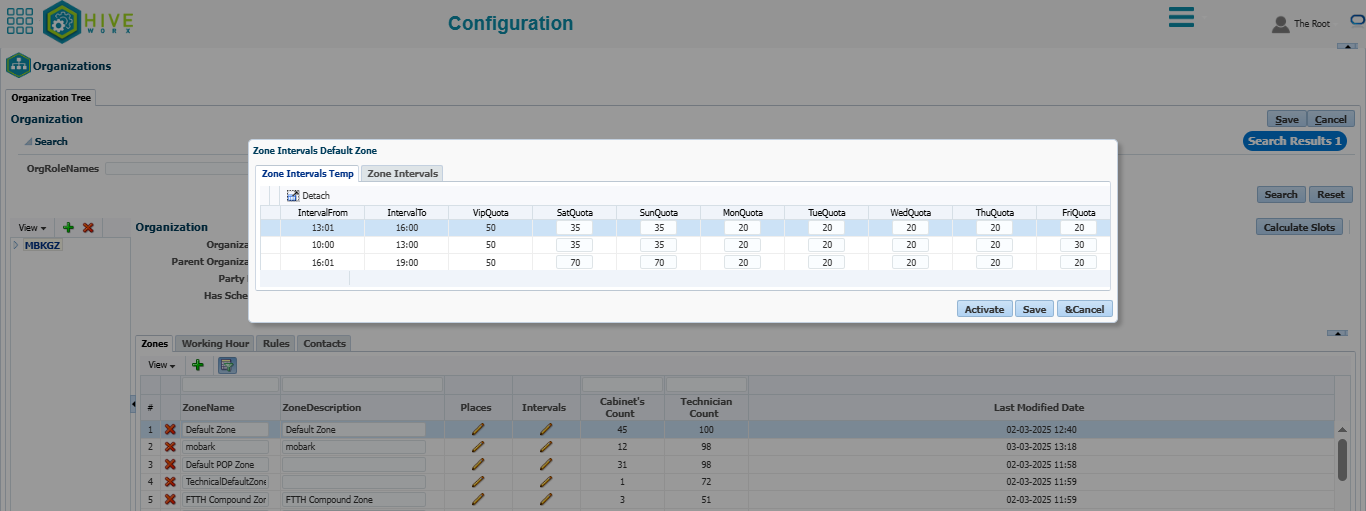


   📌 CR: CR-2025-220 | Score: 0.462 | Size: 1148x602


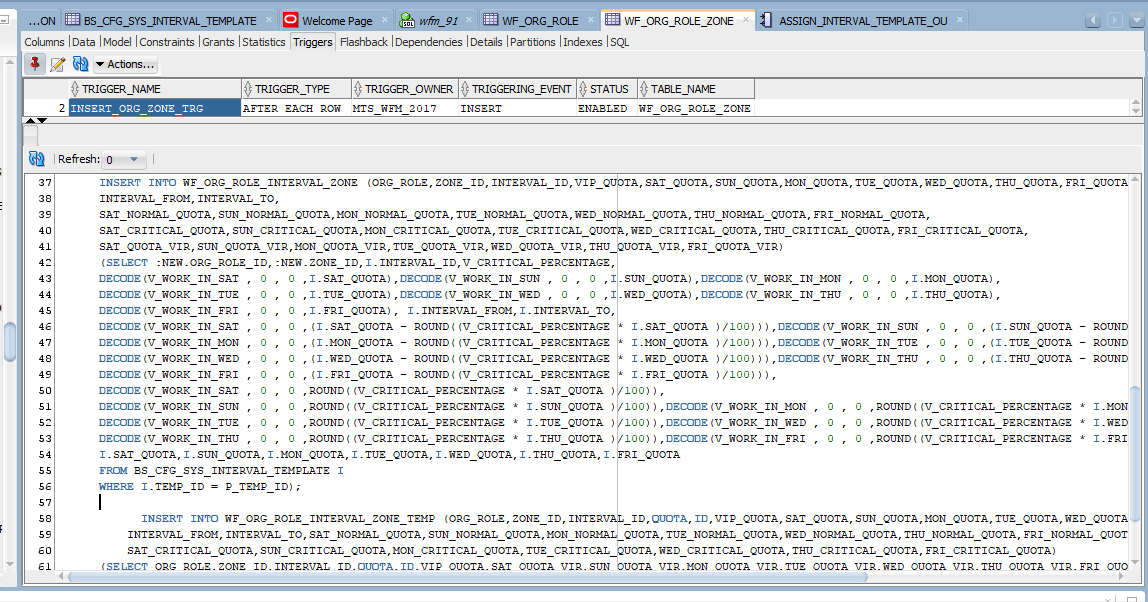


📄 Sources:
   - (CR-2024-152)WFM FO Scheduling - Modify Time Intervals Confi
   - (CR-2025-220)WFM Automatic Scheduling Enhancement CR (V0.2).
   - (PM-2024-126)WFM Scheduling Portal - FO Maintenance FRS (V0.
   - CR-2025-229 TECH DOC WFM Automatic Scheduling Enhancement CR


In [2]:
ask("What is the automatic scheduling enhancement?")

In [ ]:
launch_gui()

* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://fd0e8d80c76212a4ad.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


✅ Groq (openai/gpt-oss-120b)
✅ Groq (openai/gpt-oss-120b)


✅ Test Set: 20 questions
🚀 Starting Full Evaluation...
📊 Total: 20 questions

[1/20] What is the automatic scheduling enhancement?
Category: Scheduling

📊 Retrieval:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        0.50
   Latency:    0.10s
✅ Groq (openai/gpt-oss-120b)

🤖 Answer:
----------------------------------------
**Automatic‑Scheduling Enhancement – Summary**

The enhancement adds a **window‑based, first‑available‑slot algorithm** that is applied to all FO (Fiber‑Optic) work orders (installation, maintenance, critical and re‑open). Its key elements are:

| Aspect | What the enhancement does | Source |
|-----...

📊 Metrics:
   Faithfulness: 0.35
   Relevance:    0.83
   Latency:      2.40s
   Images:       2

🖼️ Process Flows:
   CR: CR-2025-220 | Score: 0.462


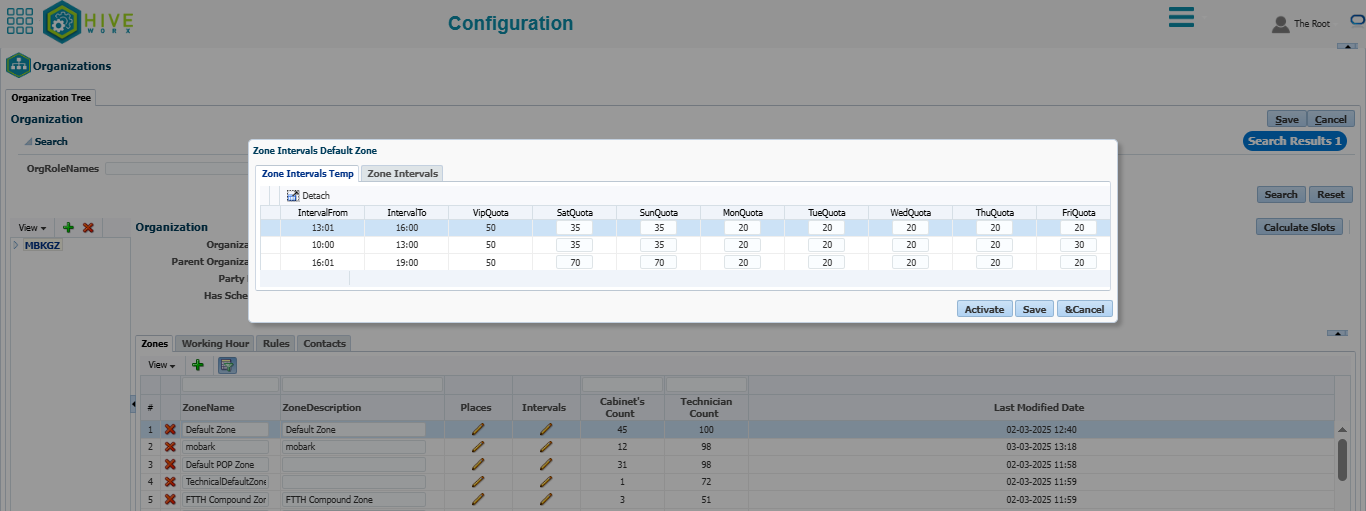

   CR: CR-2025-220 | Score: 0.462


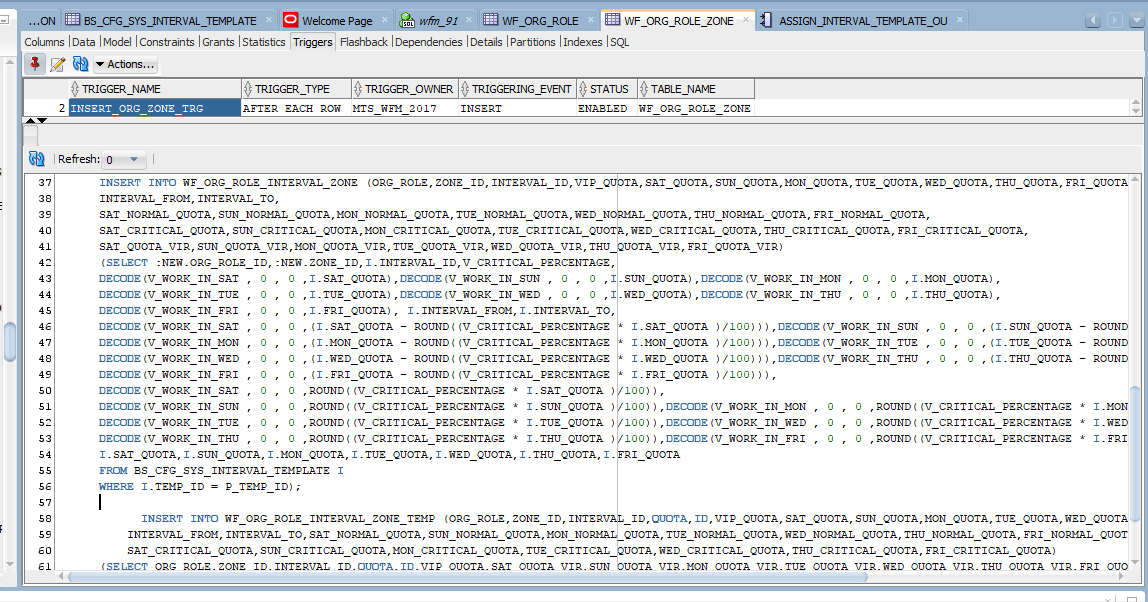


📄 Sources:
   - (CR-2024-152)WFM FO Scheduling - Modify Time Intervals 
   - (CR-2025-220)WFM Automatic Scheduling Enhancement CR (V
   - (PM-2024-126)WFM Scheduling Portal - FO Maintenance FRS

[2/20] How does WFM handle no free slots in scheduling?
Category: Scheduling

📊 Retrieval:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        0.50
   Latency:    0.05s
✅ Groq (openai/gpt-oss-120b)

🤖 Answer:
----------------------------------------
When the automatic scheduler cannot find any free time‑slot for a work order, WFM follows a defined “no‑free‑slots” flow:

1. **Automatic scheduling attempt** – WFM scans the first available time interval (within the configurable horizon, initially 5 days) for a free normal slot. If the order is mar...

📊 Metrics:
   Faithfulness: 0.44
   Relevance:    0.56
   Latency:      1.85s
   Images:       2

🖼️ Process Flows:
   CR: CR-2025-220 | Score: 0.488


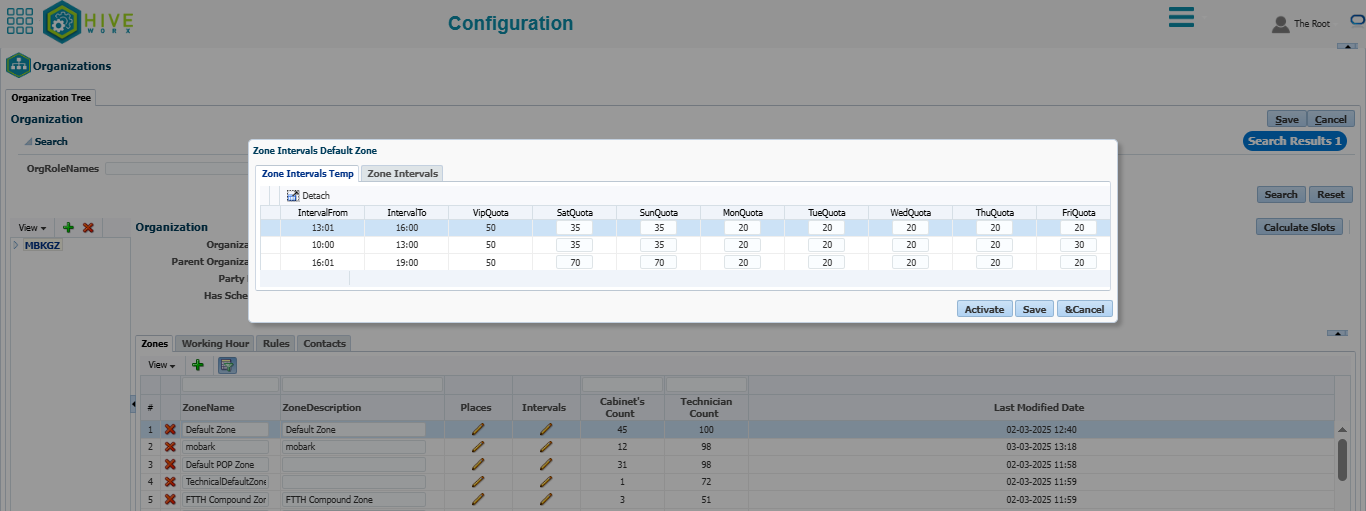

   CR: CR-2025-220 | Score: 0.488


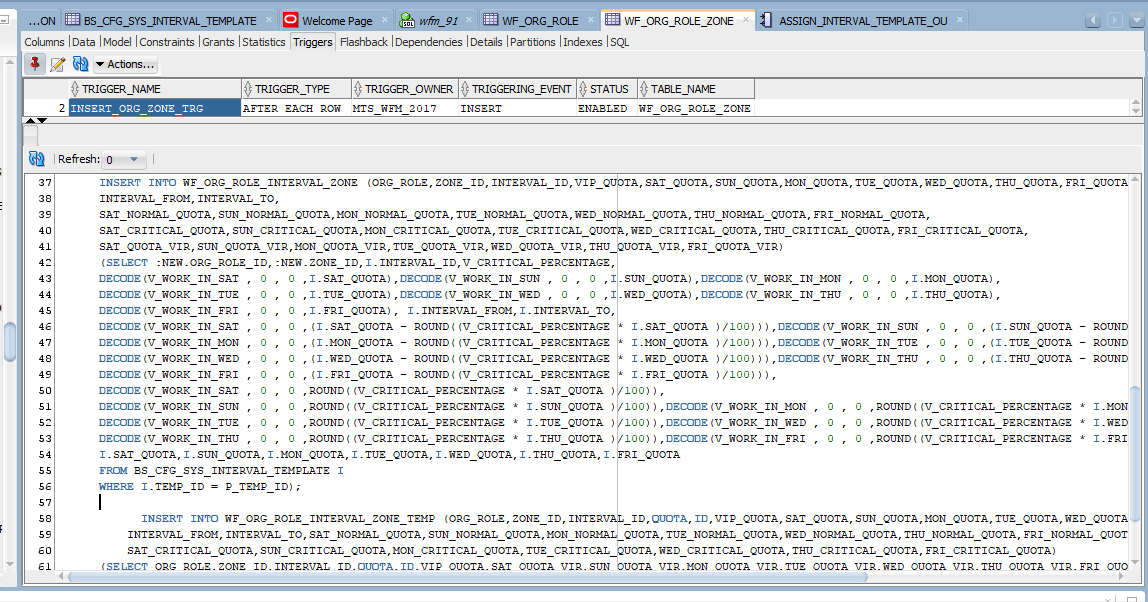


📄 Sources:
   - (PM-2024-126)WFM Scheduling Portal - FO Maintenance FRS
   - (CR-2025-220)WFM Automatic Scheduling Enhancement CR (V

[3/20] What are the time slot configuration rules?
Category: Scheduling

📊 Retrieval:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        1.00
   Latency:    0.03s
✅ Groq (openai/gpt-oss-120b)

🤖 Answer:
----------------------------------------
**Time‑slot configuration is governed by a strict permission model and a defined set of slots:**

1. **Separate permissions for each action**  
   * *Increase time slots* – a permission that allows a user to add new slots to the schedule.  
   * *Decrease time slots* – a permission that allows a use...

📊 Metrics:
   Faithfulness: 0.39
   Relevance:    0.71
   Latency:      1.93s
   Images:       0

📄 Sources:
   - (CR-2024-152)WFM FO Scheduling - Modify Time Intervals 
   - (PM-2024-126)WFM Scheduling Portal - FO Maintenance FRS

[4/20] How does automatic scheduling work for maintenance orders?
Category: Sched

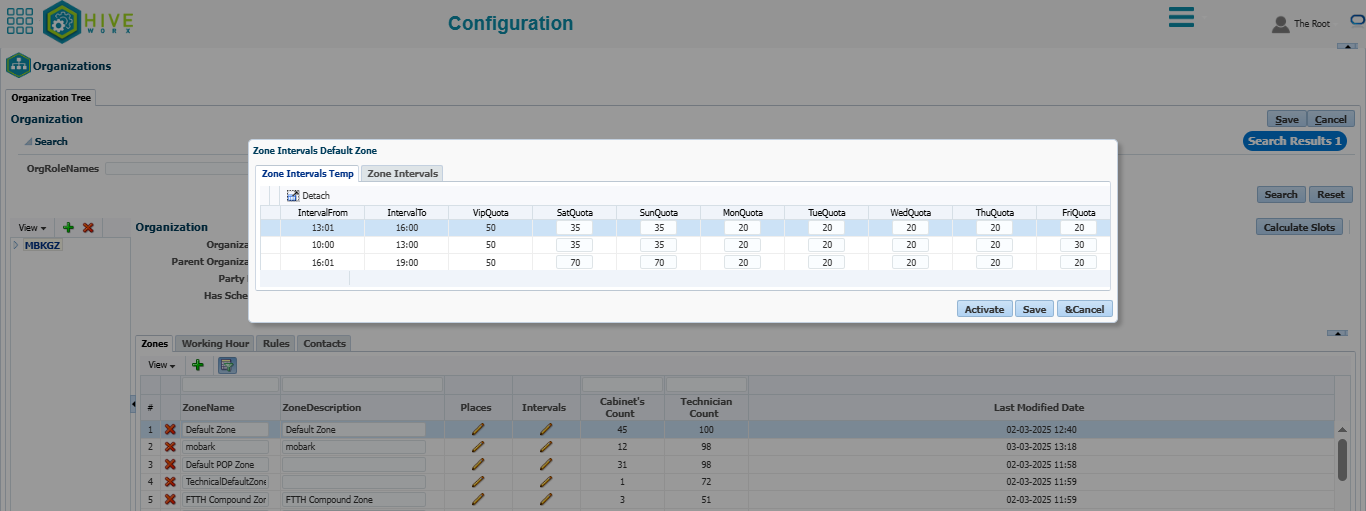

   CR: CR-2025-220 | Score: 0.328


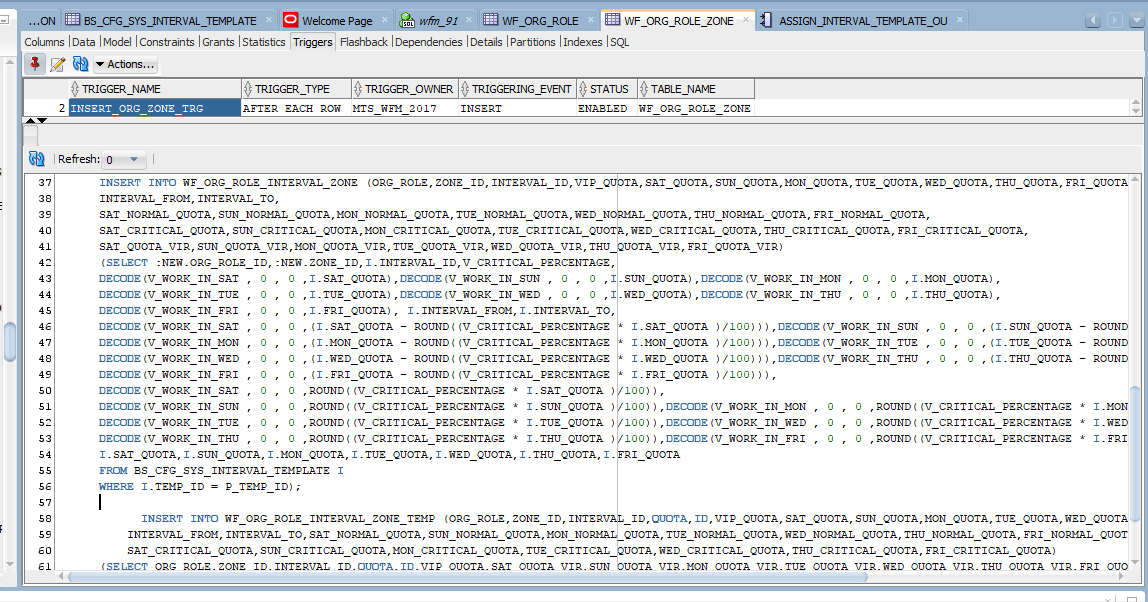


📄 Sources:
   - (PM-2024-126)WFM Scheduling Portal - FO Maintenance FRS
   - CR-2025-229 WFM Automatic Scheduling Enhancement CR Ame
   - (CR-2025-220)WFM Automatic Scheduling Enhancement CR (V

[5/20] What is the CS scheduling reports amendment?
Category: Scheduling

📊 Retrieval:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        0.33
   Latency:    0.03s
✅ Groq (openai/gpt-oss-120b)

🤖 Answer:
----------------------------------------
**CS Scheduling Reports Amendment**

The amendment to the CS (Customer Service) scheduling reports introduces three new data elements that are now included in the output of the scheduling‑related reports:

| New field | What it shows |
|-----------|---------------|
| **End‑to‑End Time** | The total ...

📊 Metrics:
   Faithfulness: 0.36
   Relevance:    0.86
   Latency:      1.28s
   Images:       0

📄 Sources:
   - (CR-2024-133)WFM CS Scheduling Reports Amendment2 (V0.3
   - CR-2025-229 WFM Automatic Scheduling Enhancement CR Ame
   - (CR-2024-103)WF

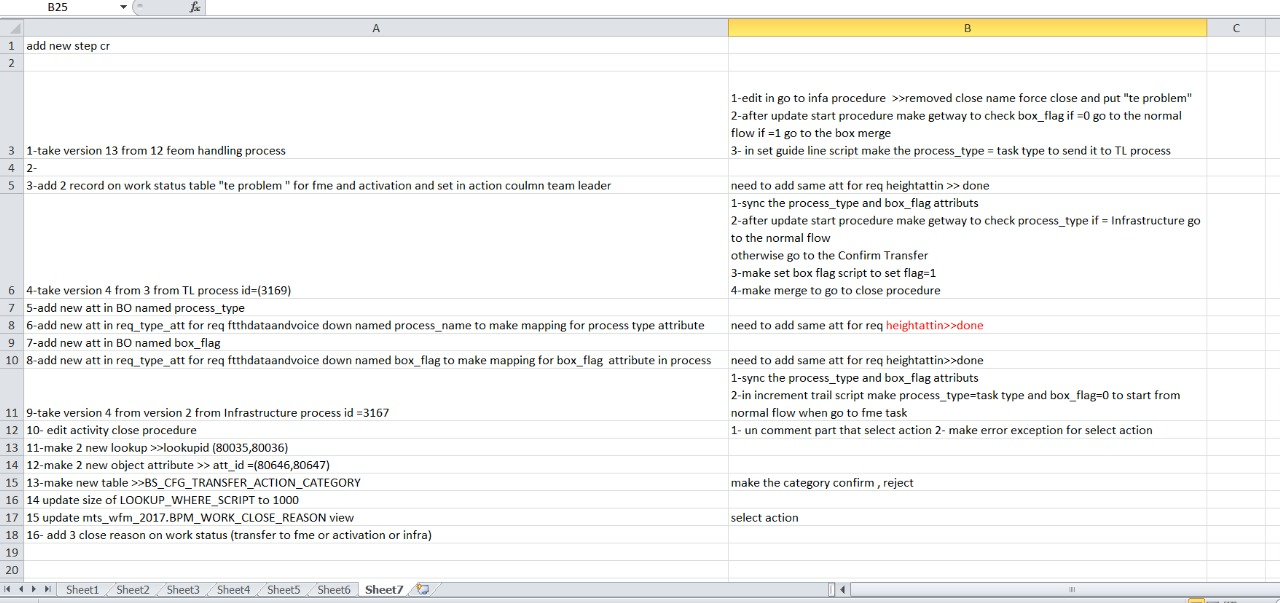

   CR: PM-2024-168 | Score: 0.556


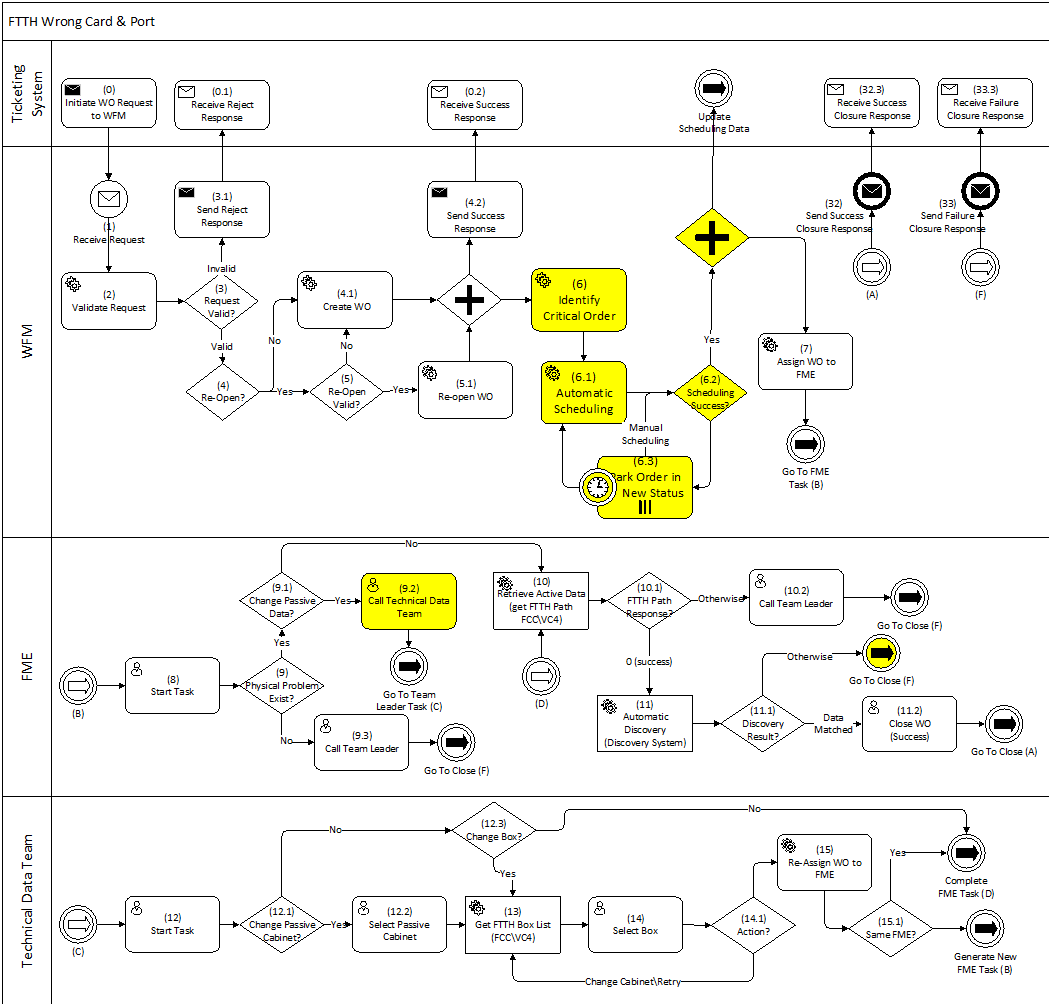


📄 Sources:
   - PM-2024-168   WFM PH2 FO Technical Maintenance BPD (V3.
   - WFM - CS FTTH Maintenance Reporting(V0.5).docx
   - (CR-2025-_222) Technical_Solution for FTTH_Maintenance_

[7/20] How to handle ONT status response in FTTH?
Category: Maintenance

📊 Retrieval:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        1.00
   Latency:    0.04s
✅ Groq (openai/gpt-oss-120b)

🤖 Answer:
----------------------------------------
**Handling the ONT‑status response in the FTTH integration is done by branching on the MSAN Vendor ID that is read from **`getlineinfo`** and then evaluating the vendor‑specific attribute that reports the ONT state.**  

| MSAN Vendor | Vendor ID (from `getlineinfo`) | Attribute to read | Value that...

📊 Metrics:
   Faithfulness: 0.26
   Relevance:    0.62
   Latency:      6.87s
   Images:       2

🖼️ Process Flows:
   CR: CR-2025-222 | Score: 0.402


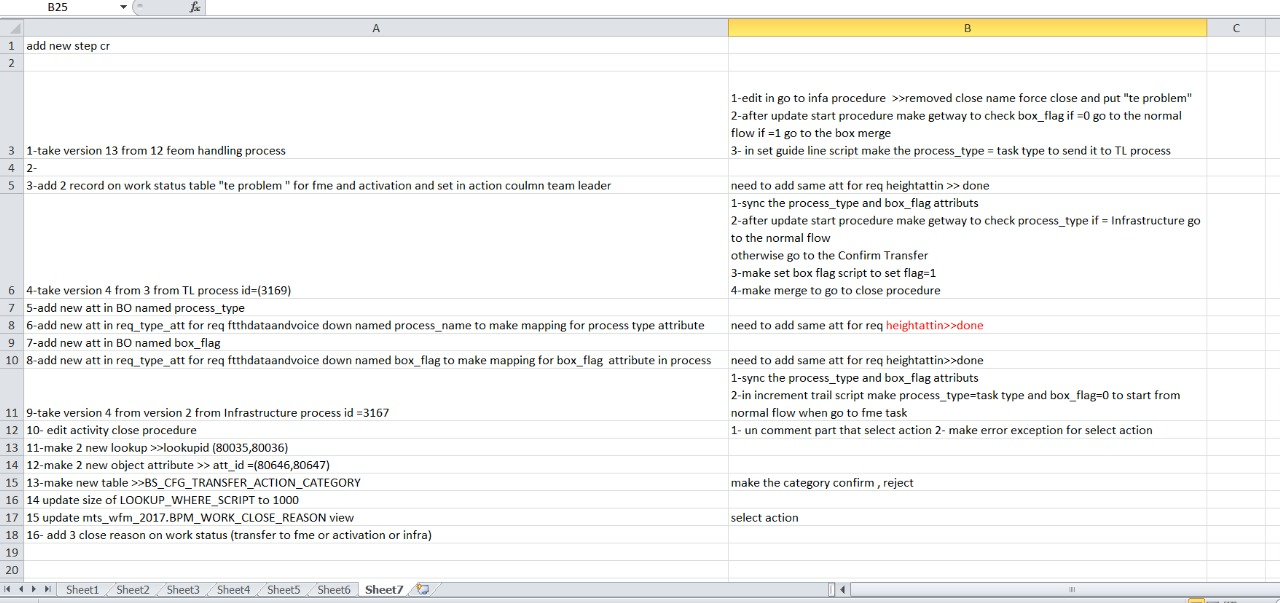

   CR: CR-2025-222 | Score: 0.276


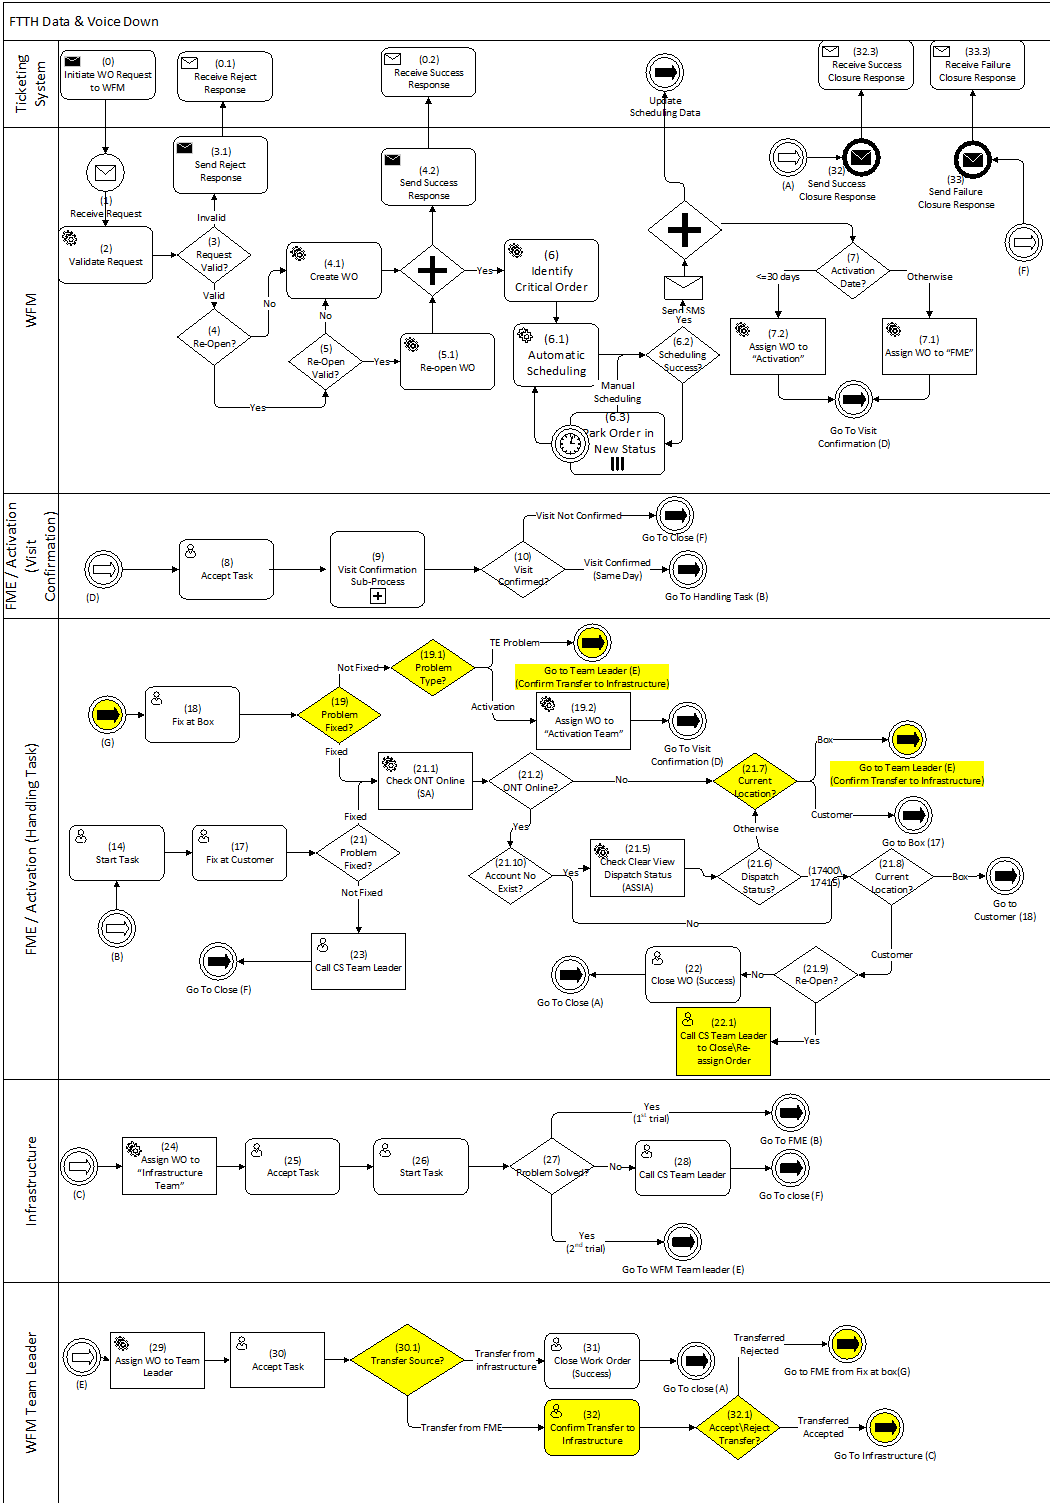


📄 Sources:
   - (PM-2025-225) FTTH_Maintenance_-Handle_ONT_Status_Respo
   - (CR-2025-_222)_FTTH_Maintenance_-_Add_New_step_On_WFM_W

[8/20] What is enterprise maintenance in WFM?
Category: Maintenance

📊 Retrieval:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        1.00
   Latency:    0.03s
⚠️ Groq openai/gpt-oss-120b: Error code: 429 - {'error': {'message': 'Rate limi
✅ Groq (openai/gpt-oss-20b)

🤖 Answer:
----------------------------------------
Enterprise maintenance in WFM refers to the project phase that focuses on maintaining enterprise‑level assets and processes. It is represented by the **Software Quality Control** team and involves the development and amendment of WFM workflows for technical maintenance visits (e.g., the FO team’s “W...

📊 Metrics:
   Faithfulness: 0.43
   Relevance:    0.67
   Latency:      7.51s
   Images:       2

🖼️ Process Flows:
   CR: PM-2024-168 | Score: 0.542


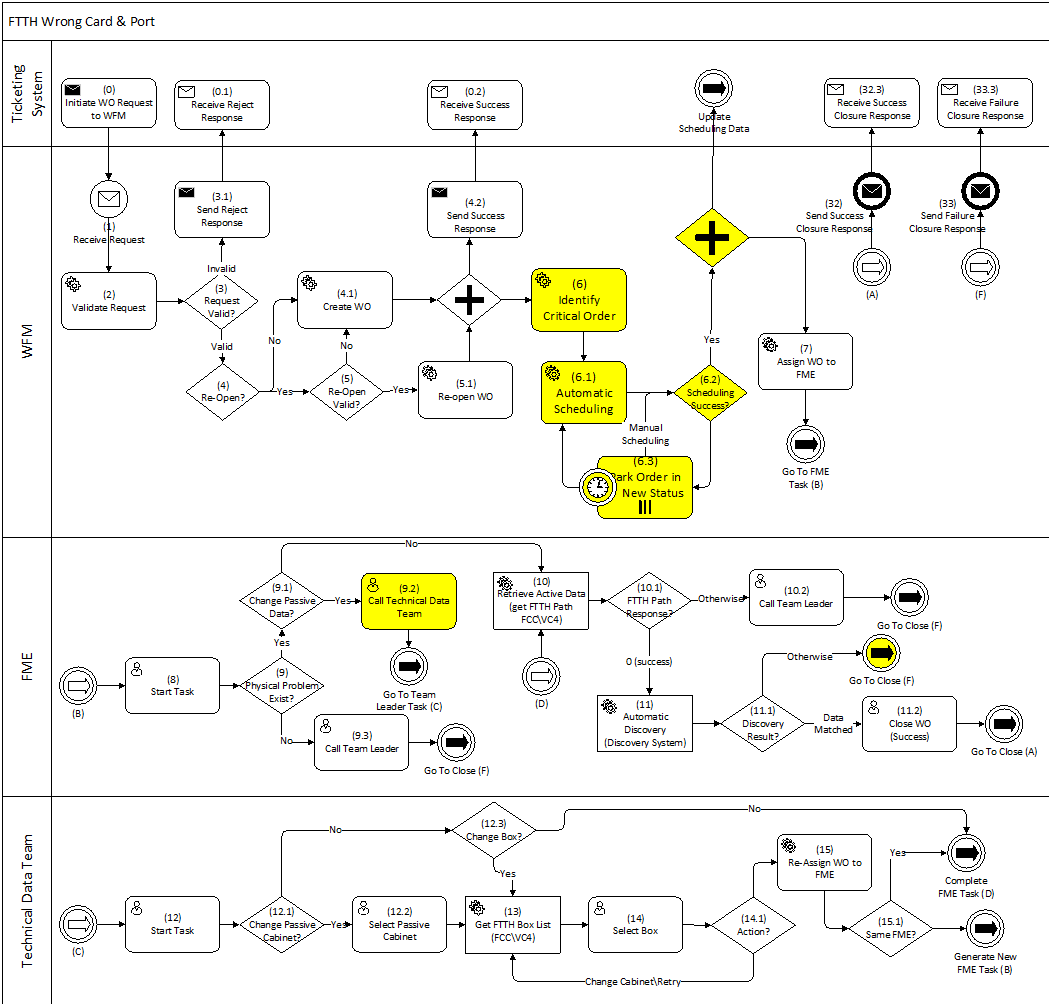

   CR: PM-2024-168 | Score: 0.542


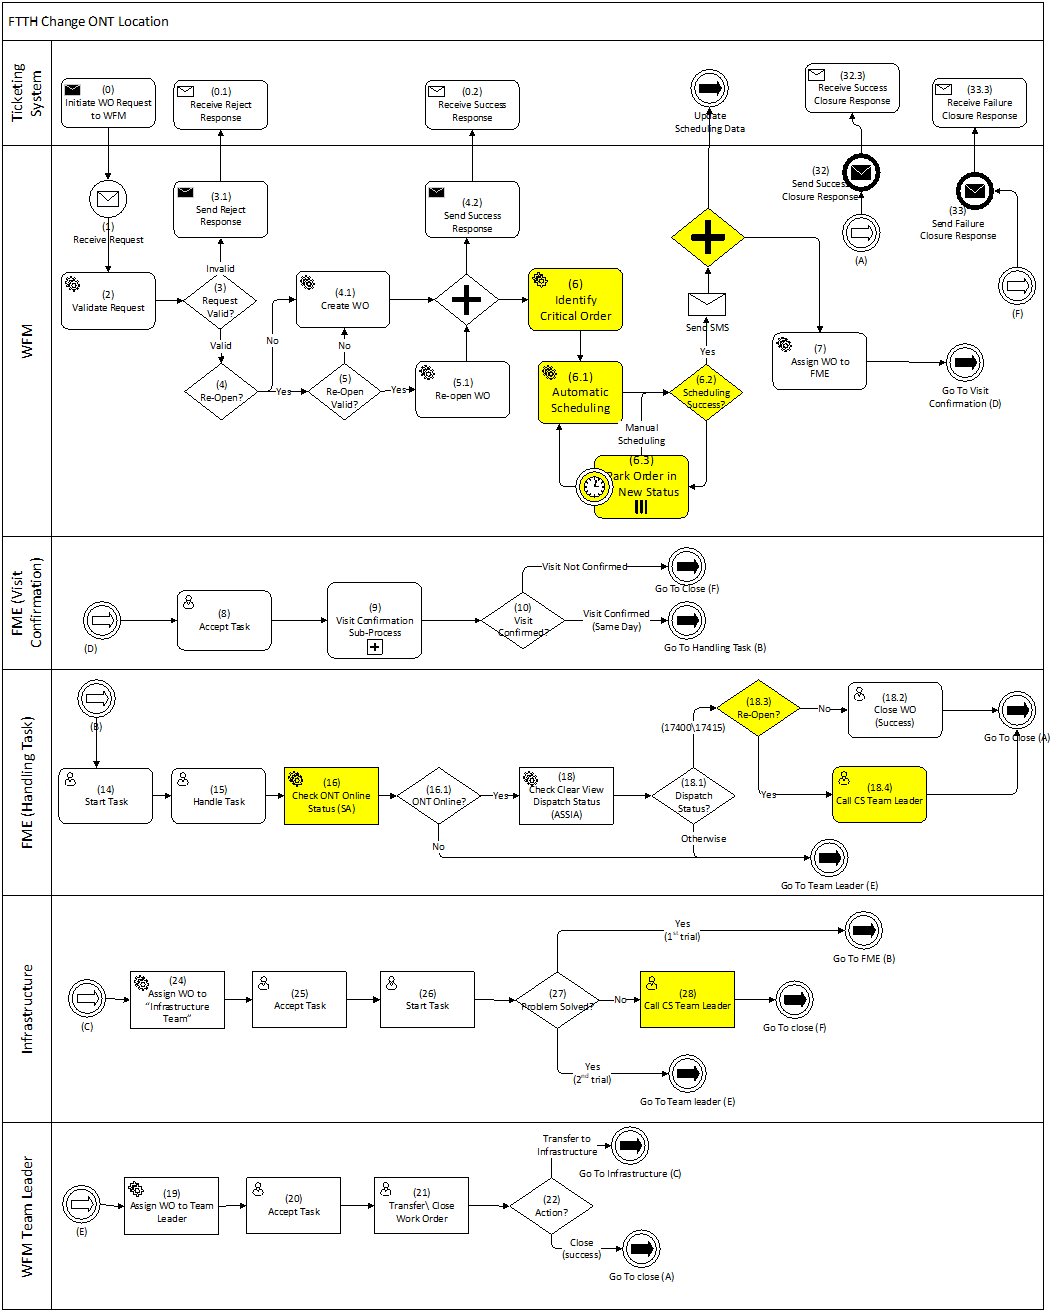


📄 Sources:
   - WFM - Enterprise Maintenance ATPs (1.0).docx
   - PM-2024-168   WFM PH2 FO Technical Maintenance BPD (V3.
   - (CR-2025-_222) Technical_Solution for FTTH_Maintenance_

[9/20] How to remove cabinet task from FME?
Category: Maintenance

📊 Retrieval:
   Recall@5:  0.00
   Precision:  0.00
   MRR:        0.00
   Latency:    0.03s
✅ Groq (openai/gpt-oss-120b)

🤖 Answer:
----------------------------------------
**To remove the cabinet task from the FME’s work‑list you must terminate the “Fix‑at‑Cabinet” flow by supplying a close‑reason.**  

1. **Add a gateway after the “Fix At Cabinet” step** (see *Source 1*).  
   - The gateway checks the variable **`fme_close_reason`**.  

2. **If `fme_close_reason` is ...

📊 Metrics:
   Faithfulness: 0.23
   Relevance:    0.71
   Latency:      1.98s
   Images:       2

🖼️ Process Flows:
   CR: CR-2025-222 | Score: 0.288


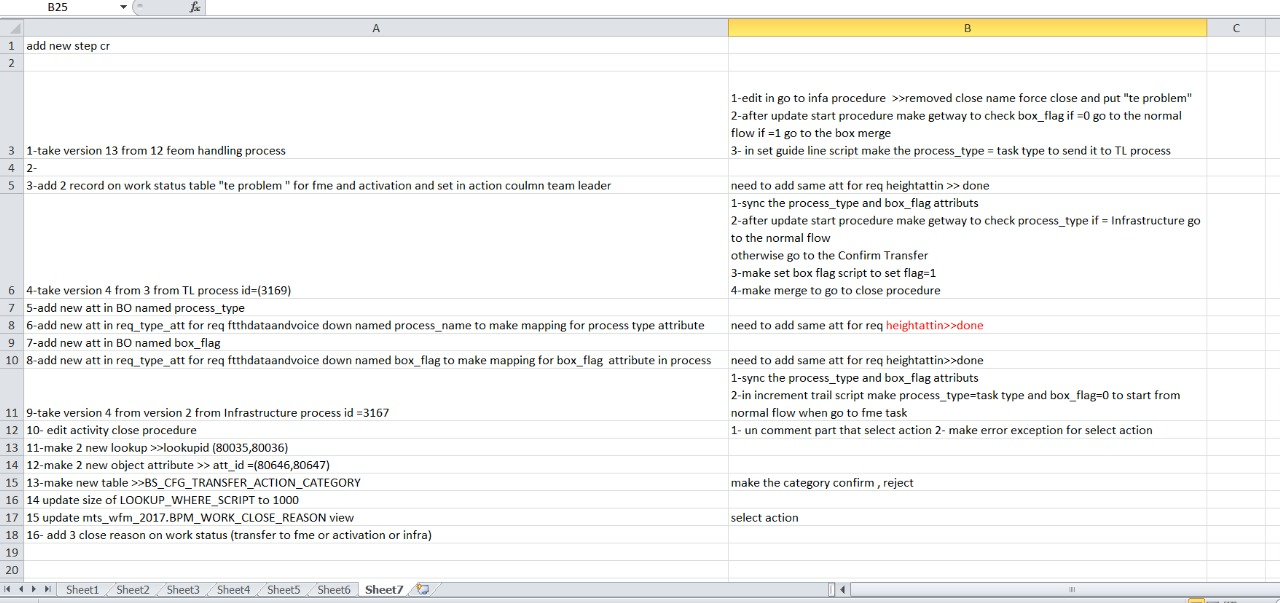

   CR: CR-2025-222 | Score: 0.202


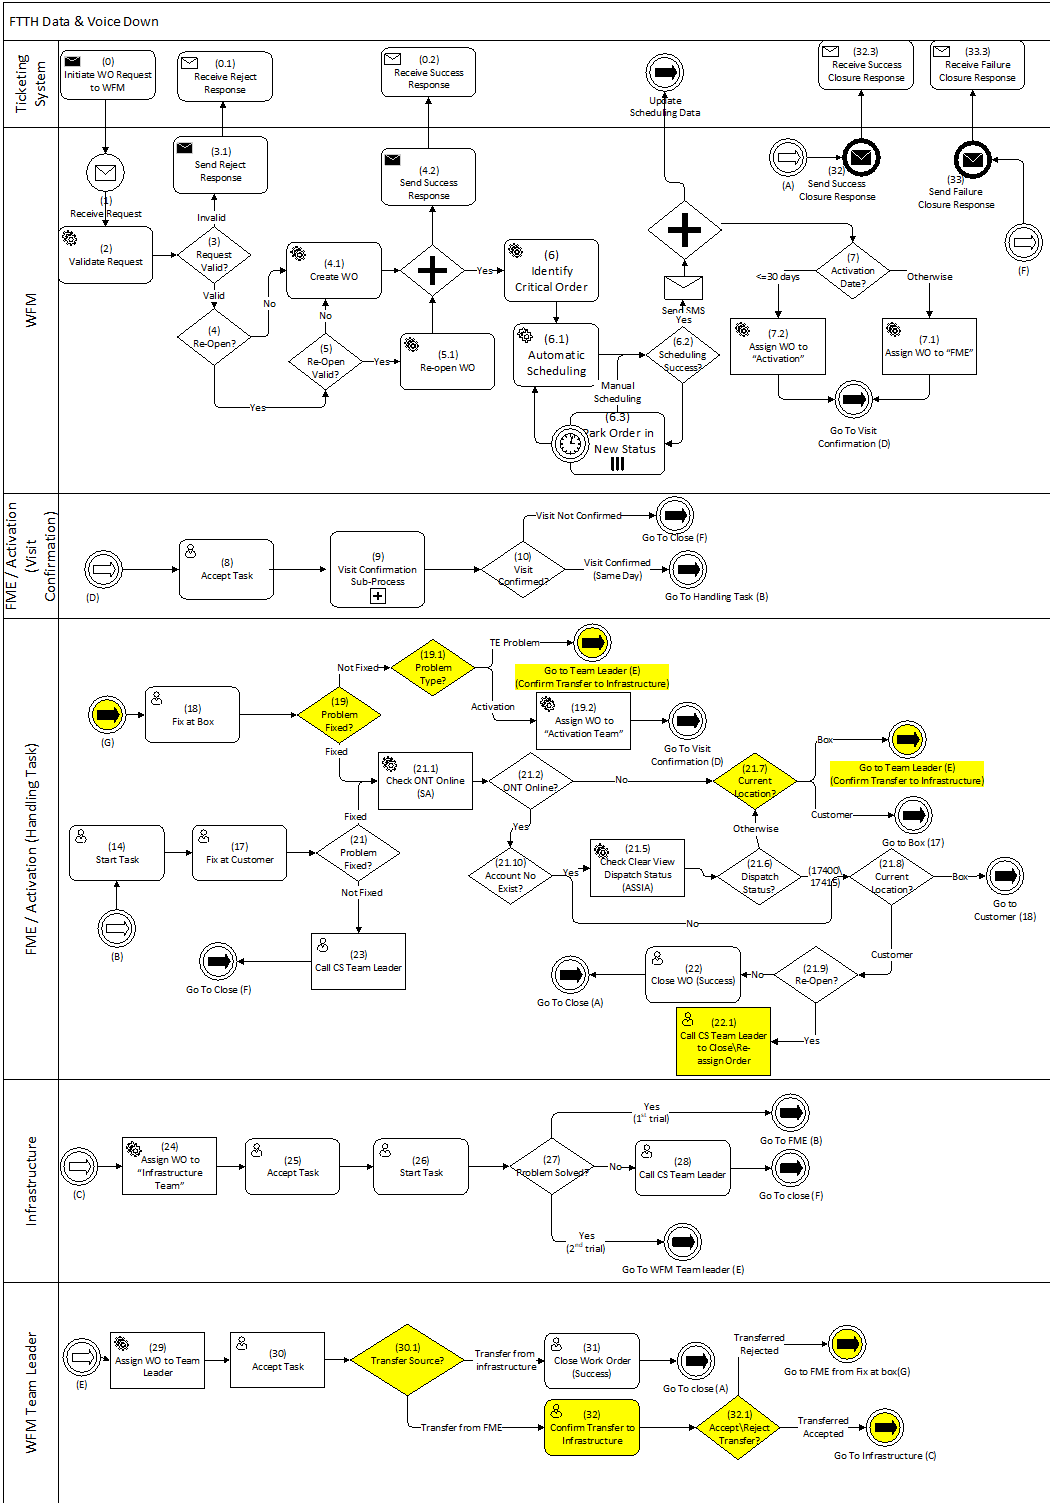


📄 Sources:
   - Technical_Solution for Add_Cables_Task CR.docx
   - (CR-2025-_222)_FTTH_Maintenance_-_Add_New_step_On_WFM_W

[10/20] What is reserve activation no free port?
Category: Installation

📊 Retrieval:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        0.50
   Latency:    0.15s
✅ Groq (openai/gpt-oss-120b)

🤖 Answer:
----------------------------------------
**Reserve Activation – “No Free Port”**  

In the WFM (Work‑Force Management) reservation‑activation flow, *“no free port”* is the specific error condition that occurs when the system is asked to activate a new service (e.g., an FTTH new‑subscriber request) but it cannot find any available physical ...

📊 Metrics:
   Faithfulness: 0.29
   Relevance:    0.57
   Latency:      8.65s
   Images:       2

🖼️ Process Flows:
   CR: CR-2024-164 | Score: 0.203


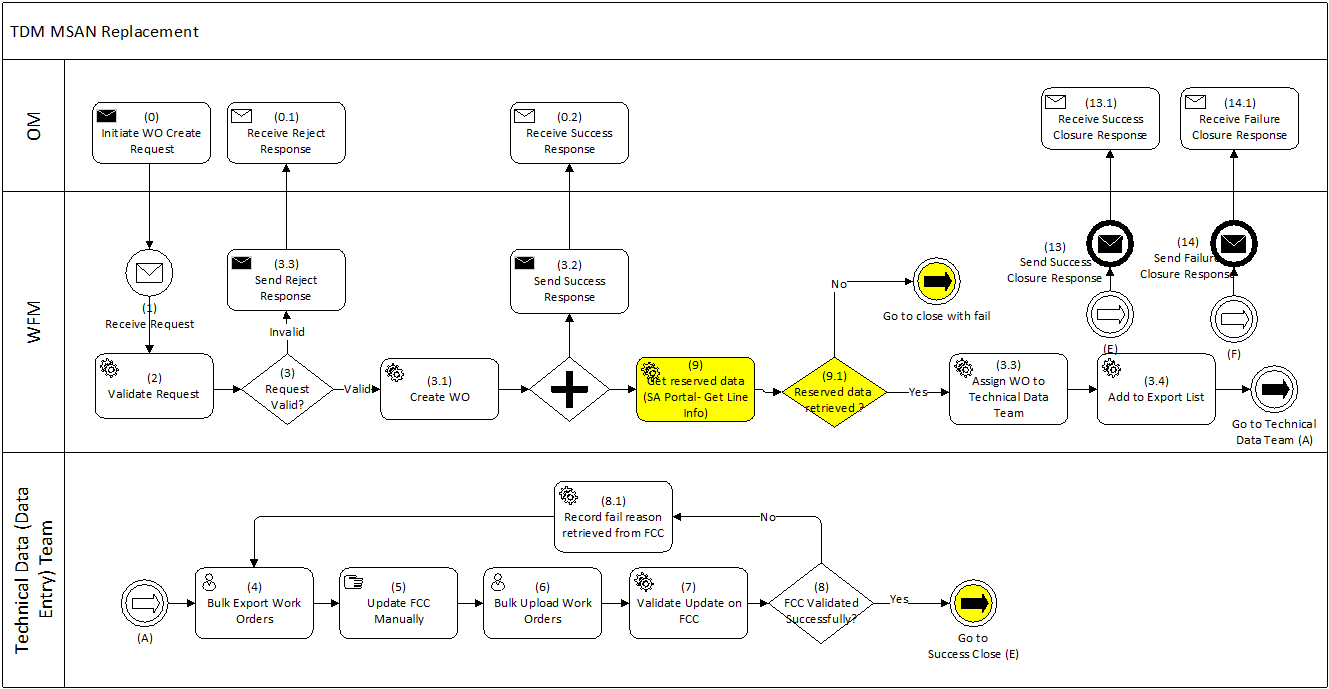

   CR: CR-2024-164 | Score: 0.203


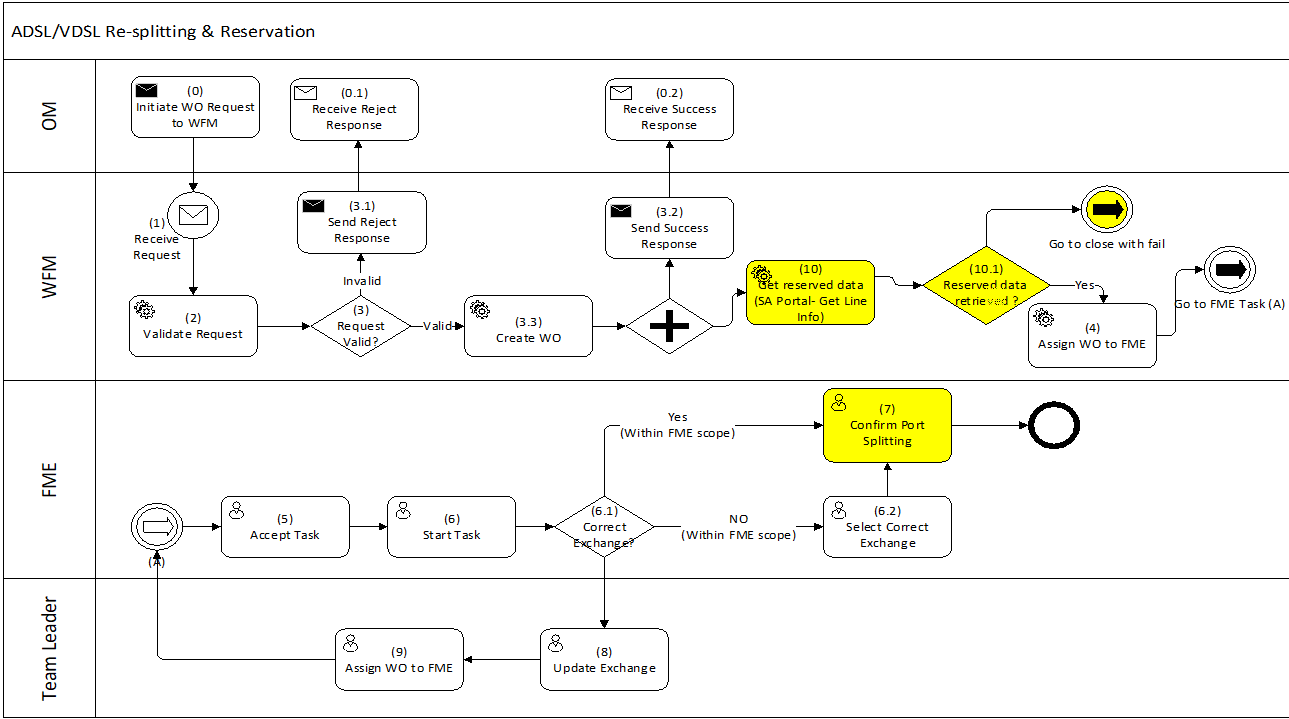


📄 Sources:
   - CR-2025-230_WFM_Reserve_Activation_No_free_port_amendme
   - Technical_Solution for WFM Reserve Activation.docx
   - (CR-2024-164)_WFM_SA_-_Remove_Reservation_Activity_from
   - CR-2025-226 WFM Reserve Activation - No free port(FTTH 

[11/20] How does FTTH migration work for unreached customers?
Category: Installation

📊 Retrieval:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        1.00
   Latency:    0.03s
✅ Groq (openai/gpt-oss-120b)

🤖 Answer:
----------------------------------------
**FTTH migration for customers that cannot be reached (unreachable, visit‑refused, or any other failure during manual scheduling/visit‑confirmation) follows a strict, multi‑step workflow that forces the technical validation to be completed before the order can be closed with a customer‑related failu...

📊 Metrics:
   Faithfulness: 0.28
   Relevance:    0.38
   Latency:      10.21s
   Images:       1

🖼️ Process Flows:
   CR: PM-2024-173 | Score: 0.436


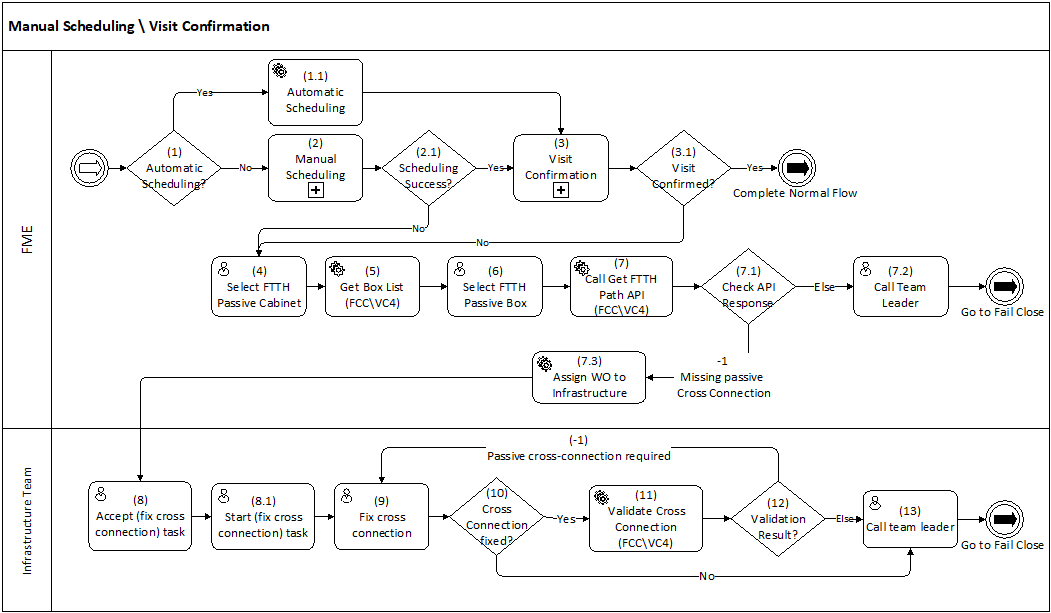


📄 Sources:
   - WFM FTTH Migration Un Reached  Rejected Customers CR (v
   - CR-2025-230_WFM_Reserve_Activation_No_free_port_amendme

[12/20] What is the priority flag for installation orders?
Category: Installation

📊 Retrieval:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        1.00
   Latency:    0.03s
✅ Groq (openai/gpt-oss-120b)

🤖 Answer:
----------------------------------------
The installation‑order work‑order priority is driven by the **detractor flag**:

* **Detractor flag = 0** → Work‑order priority = **Normal**  
* **Detractor flag = 1** → Work‑order priority = **Critical**  

Thus the priority flag is a binary flag (0 = Normal, 1 = Critical).

📊 Metrics:
   Faithfulness: 0.25
   Relevance:    0.50
   Latency:      10.46s
   Images:       2

🖼️ Process Flows:
   CR: PM-2025-212 | Score: 0.39


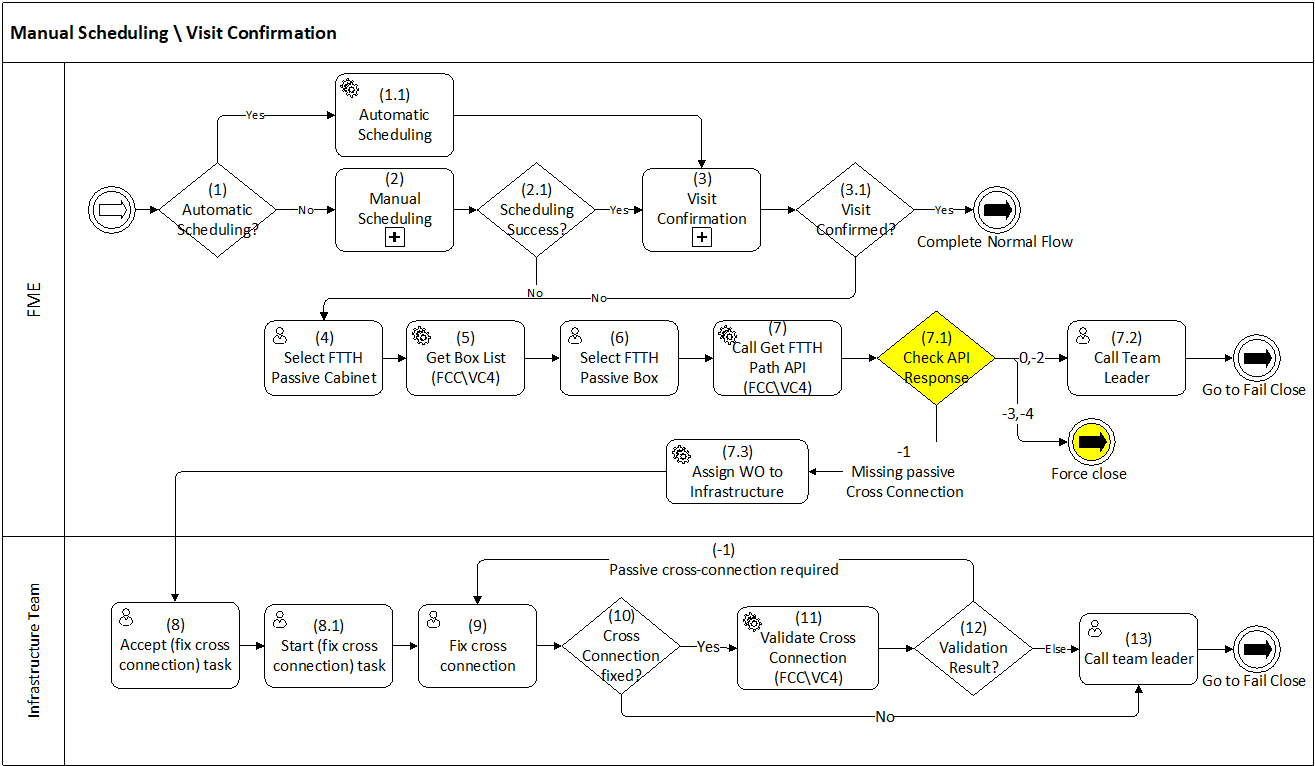

   CR: CR-2025-238 | Score: 0.296


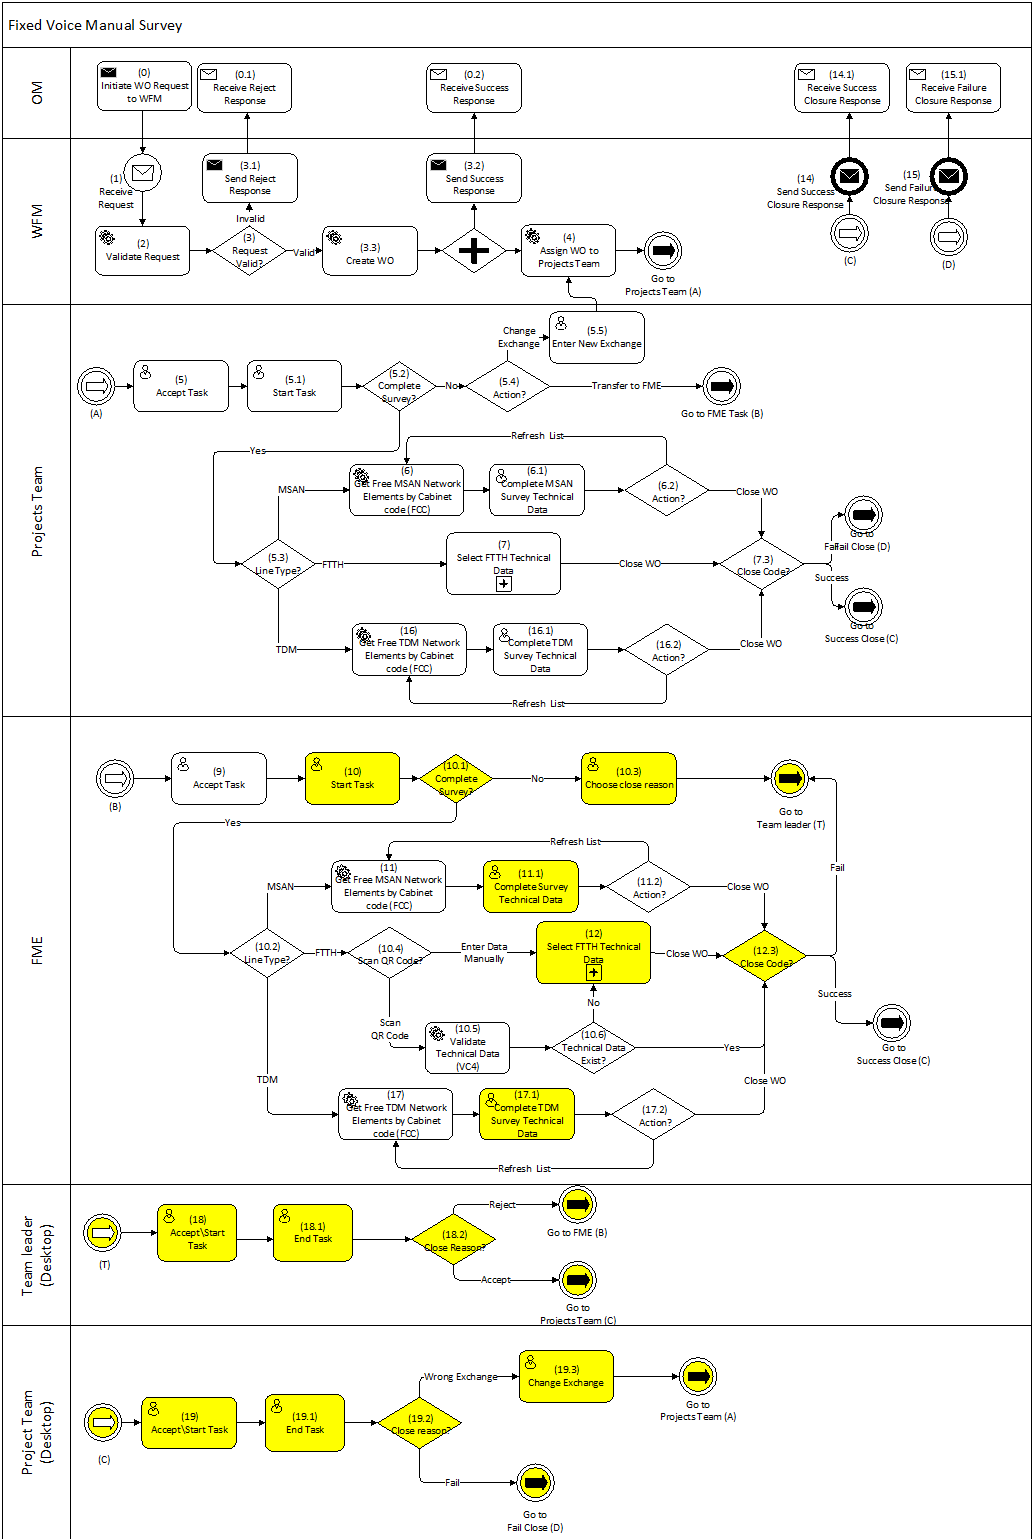


📄 Sources:
   - (CR-2026-251) WFM Add Priority flag to installation ord
   - WFM FTTH Migration Un Reached  Rejected Customers CR (v
   - PM-2025-212  WFM_FTTH_Migration_Un_Reached_Rejected_Cus
   - (CR-2025-238) WFM FV Manual Survey - Add Team Leader Va

[13/20] How to fix cross connection in WFM?
Category: Service_Activation

📊 Retrieval:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        1.00
   Latency:    0.03s
✅ Groq (openai/gpt-oss-120b)

🤖 Answer:
----------------------------------------
**Fixing a cross‑connection in WFM – step‑by‑step**

1. **Initiate the FCC call**  
   - The WFM process starts with a system call to the FCC service (GetFTTHPath). This request retrieves the FTTH cross‑connection information for the subscriber line【Source 1】.

2. **Validate the FCC response**  
   ...

📊 Metrics:
   Faithfulness: 0.29
   Relevance:    0.43
   Latency:      10.08s
   Images:       0

📄 Sources:
   - CR-2024-157_WFM_SA_Fix_cross-connection_CR_(V0.2).docx
   - (CR-2024-165) W

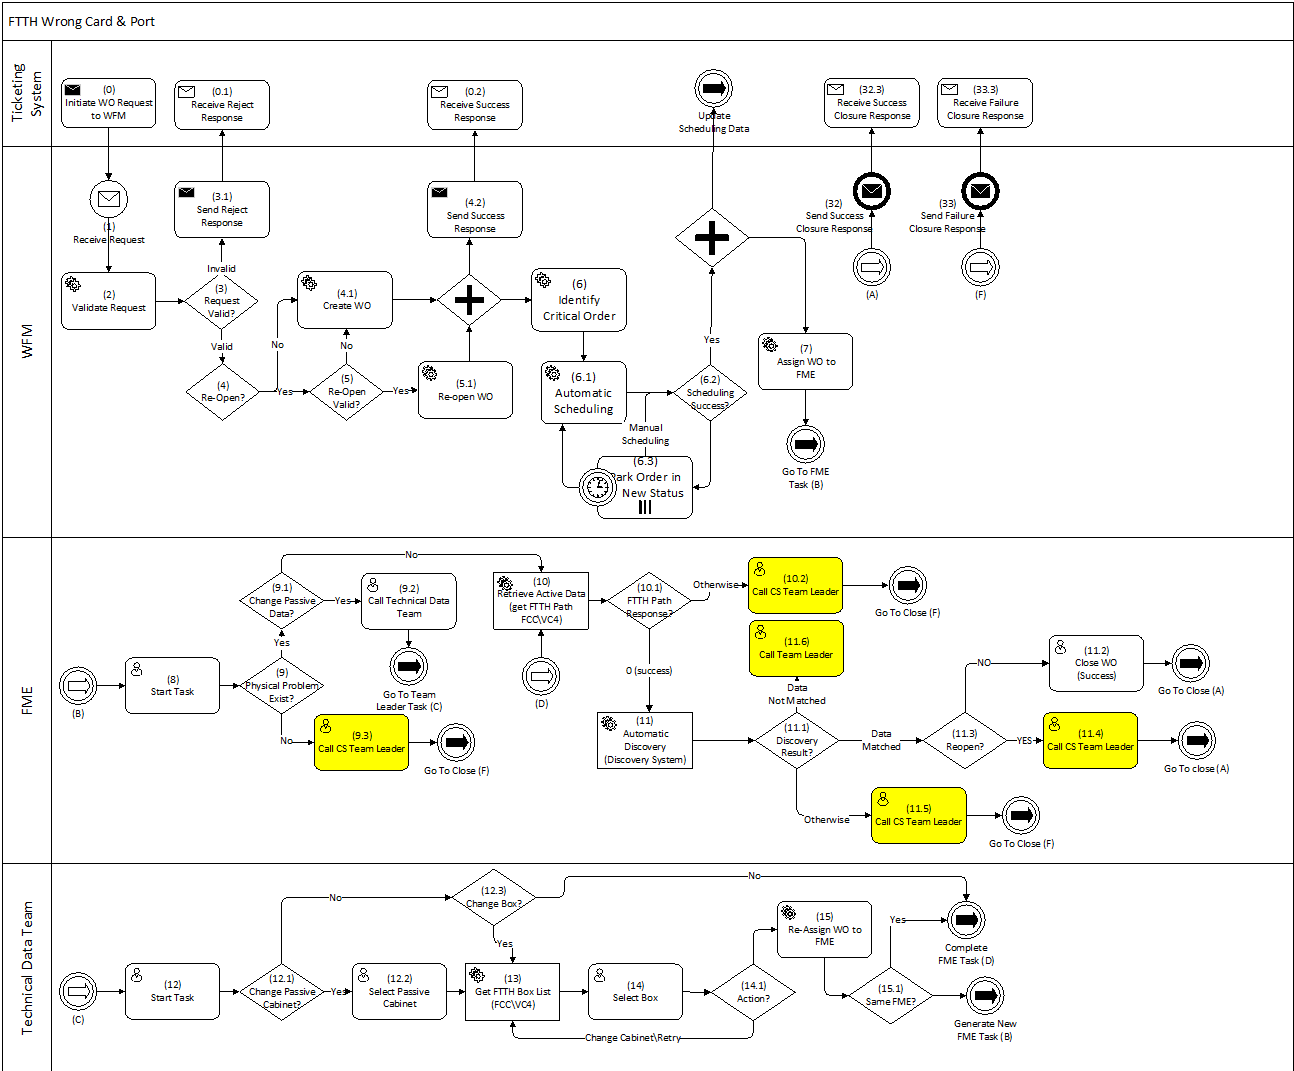


📄 Sources:
   - CR-2025-214   Remove permission for all FME to close Re
   - (CR-2026-265) FTTH WCAP Re-open work orders(0.2) .docx

[19/20] How to add temp assigned serials to pending tasks?
Category: Work_Orders

📊 Retrieval:
   Recall@5:  1.00
   Precision:  0.20
   MRR:        0.50
   Latency:    0.02s
✅ Groq (openai/gpt-oss-120b)

🤖 Answer:
----------------------------------------
**Steps to add Temp Assigned Serial numbers to Pending Tasks in the WFM Assignment & Dispatch module**

1. **Locate the “Task Queue” page**  
   - Open the **Assignment and Dispatch** module and navigate to the **Task Queue** screen. This is the central view where both *Pending* and *Assigned* tasks...

📊 Metrics:
   Faithfulness: 0.33
   Relevance:    0.75
   Latency:      8.95s
   Images:       0

📄 Sources:
   - Test Scenarios of Amendment Add temp assigned serials t
   - CR-2025-228 WFM - Add temp assigned serials to pendinga
   - CR-2025-233 WFM - Amedment Add temp assigned serials to

[20/20] What

In [3]:
import time
import re
import numpy as np
import os
import json

os.makedirs("evaluation", exist_ok=True)

MODELS_TO_TRY = [
    "models/gemini-3.5-flash",
    "models/gemini-3.6-flash",
    "models/gemini-3.7-flash",
    "models/gemini-3.8-flash",
]

GROQ_MODELS = [
    "openai/gpt-oss-120b",  # ← تعديل
    "openai/gpt-oss-20b",
    "qwen/qwen3.8-27b",
]

test_set = [
    {"question": "What is the automatic scheduling enhancement?",
     "relevant_crs": ["CR-2025-220"], "category": "Scheduling"},
    {"question": "How does WFM handle no free slots in scheduling?",
     "relevant_crs": ["CR-2025-220"], "category": "Scheduling"},
    {"question": "What are the time slot configuration rules?",
     "relevant_crs": ["CR-2024-152"], "category": "Scheduling"},
    {"question": "How does automatic scheduling work for maintenance orders?",
     "relevant_crs": ["PM-2024-126"], "category": "Scheduling"},
    {"question": "What is the CS scheduling reports amendment?",
     "relevant_crs": ["CR-2024-103"], "category": "Scheduling"},
    {"question": "What is the FTTH maintenance process flow?",
     "relevant_crs": ["PM-2024-168"], "category": "Maintenance"},
    {"question": "How to handle ONT status response in FTTH?",
     "relevant_crs": ["PM-2025-225"], "category": "Maintenance"},
    {"question": "What is enterprise maintenance in WFM?",
     "relevant_crs": ["CR-2025-209"], "category": "Maintenance"},
    {"question": "How to remove cabinet task from FME?",
     "relevant_crs": ["PM-2025-216"], "category": "Maintenance"},
    {"question": "What is reserve activation no free port?",
     "relevant_crs": ["CR-2025-226"], "category": "Installation"},
    {"question": "How does FTTH migration work for unreached customers?",
     "relevant_crs": ["PM-2024-173"], "category": "Installation"},
    {"question": "What is the priority flag for installation orders?",
     "relevant_crs": ["CR-2026-251"], "category": "Installation"},
    {"question": "How to fix cross connection in WFM?",
     "relevant_crs": ["CR-2024-157"], "category": "Service_Activation"},
    {"question": "What is wrong card and port CR?",
     "relevant_crs": ["CR-2024-166"], "category": "Service_Activation"},
    {"question": "How to remove reservation activity from WFM?",
     "relevant_crs": ["CR-2024-164"], "category": "Service_Activation"},
    {"question": "What is KPI report for team leader?",
     "relevant_crs": ["CR-2025-218"], "category": "Dashboard_Reports"},
    {"question": "What is WFM operations monitoring dashboard?",
     "relevant_crs": ["CR-2024-131"], "category": "Dashboard_Reports"},
    {"question": "What is force close work order in customer care portal?",
     "relevant_crs": ["CR-2023-83"], "category": "Work_Orders"},
    {"question": "How to add temp assigned serials to pending tasks?",
     "relevant_crs": ["CR-2025-228"], "category": "Work_Orders"},
    {"question": "What is desktop users login modification?",
     "relevant_crs": ["CR-2023-76"], "category": "User_Management"},
]

print(f"✅ Test Set: {len(test_set)} questions")

def generate_answer_gemini(query: str, chunks: list) -> dict:
    
    context = ""
    for i, chunk in enumerate(chunks, 1):
        context += f"\n[Source {i}]\n{chunk['text'][:700]}\n"
    
    prompt = f"""
You are a WFM expert assistant.
Answer ONLY from provided sources.
Be specific and detailed.
Start answer directly.

SOURCES:
{context}

QUESTION: {query}

ANSWER:
"""
    
    # جرب Groq الأول
    for groq_model in GROQ_MODELS:  # ← loop على كل الـ models
        try:
            response = groq_client.chat.completions.create(
                model=groq_model,  # ← تعديل
                messages=[
                    {"role": "system",
                     "content": "You are a WFM expert assistant."},
                    {"role": "user", "content": prompt}
                ],
                max_tokens=1000,
                temperature=0.3
            )
            print(f"✅ Groq ({groq_model})")
            answer = response.choices[0].message.content
            images = get_related_images_smart(query, chunks)
            return {
                "answer":     answer,
                "images":     images,
                "num_images": len(images)
            }
        except Exception as e:
            print(f"⚠️ Groq {groq_model}: {str(e)[:50]}")
            continue
    
    # لو Groq فشل جرب Gemini
    for model_name in MODELS_TO_TRY:
        try:
            response = gemini_client.models.generate_content(
                model=model_name,
                contents=prompt
            )
            time.sleep(2)
            print(f"✅ Gemini ({model_name})")
            images = get_related_images_smart(query, chunks)
            return {
                "answer":     response.text,
                "images":     images,
                "num_images": len(images)
            }
        except Exception as e:
            error_str = str(e)
            print(f"⚠️ Gemini {model_name}: {error_str[:40]}")
            if "429" in error_str:
                print("   ⏳ Waiting 60s...")
                time.sleep(60)
            continue
    
    return {
        "answer":     "❌ Models غير متاحة",
        "images":     [],
        "num_images": 0
    }

def run_full_evaluation(test_set, k=5):
    
    retrieval_results = []
    answer_results    = []
    
    print("🚀 Starting Full Evaluation...")
    print(f"📊 Total: {len(test_set)} questions")
    print("=" * 60)
    
    for i, test in enumerate(test_set):
        
        query    = test["question"]
        relevant = test["relevant_crs"]
        category = test["category"]
        
        print(f"\n{'='*60}")
        print(f"[{i+1}/{len(test_set)}] {query}")
        print(f"Category: {category}")
        print(f"{'='*60}")
        
        ret_start     = time.time()
        chunks        = hybrid_search(query, top_k=k, category=category)
        ret_lat       = time.time() - ret_start
        retrieved_crs = [c["metadata"]["cr_number"] for c in chunks]
        hits          = sum(1 for r in relevant if r in retrieved_crs)
        recall        = hits / len(relevant)
        precision     = hits / k
        mrr           = 0
        for rank, cr in enumerate(retrieved_crs, 1):
            if cr in relevant:
                mrr = 1 / rank
                break
        
        retrieval_results.append({
            "question":  query, "category":  category,
            "recall":    round(recall, 3),
            "precision": round(precision, 3),
            "mrr":       round(mrr, 3),
            "latency":   round(ret_lat, 3),
            "retrieved": retrieved_crs,
            "relevant":  relevant
        })
        
        print(f"\n📊 Retrieval:")
        print(f"   Recall@{k}:  {recall:.2f}")
        print(f"   Precision:  {precision:.2f}")
        print(f"   MRR:        {mrr:.2f}")
        print(f"   Latency:    {ret_lat:.2f}s")
        
        ans_start     = time.time()
        result        = generate_answer_gemini(query, chunks)
        ans_lat       = time.time() - ans_start
        answer        = result["answer"]
        context_words = set(" ".join([c["text"] for c in chunks]).lower().split())
        answer_words  = set(answer.lower().split())
        faithfulness  = min(len(context_words & answer_words) / max(len(answer_words), 1), 1.0)
        query_words   = set(query.lower().split())
        relevance     = min(len(query_words & answer_words) / max(len(query_words), 1), 1.0)
        
        answer_results.append({
            "question":     query, "category": category,
            "answer":       answer[:500],
            "faithfulness": round(faithfulness, 3),
            "relevance":    round(relevance, 3),
            "latency":      round(ans_lat, 3),
            "num_images":   result["num_images"]
        })
        
        print(f"\n🤖 Answer:")
        print("-" * 40)
        print(answer[:300] + "..." if len(answer) > 300 else answer)
        print(f"\n📊 Metrics:")
        print(f"   Faithfulness: {faithfulness:.2f}")
        print(f"   Relevance:    {relevance:.2f}")
        print(f"   Latency:      {ans_lat:.2f}s")
        print(f"   Images:       {result['num_images']}")
        
        if result["images"]:
            print(f"\n🖼️ Process Flows:")
            for img in result["images"]:
                print(f"   CR: {img['cr']} | Score: {img['score']}")
                try:
                    display(IPImage(filename=img['path'], width=400))
                except:
                    pass
        
        print("\n📄 Sources:")
        seen = set()
        for chunk in chunks:
            fname = chunk['metadata']['filename']
            if fname not in seen:
                print(f"   - {fname[:55]}")
                seen.add(fname)
        
        with open("evaluation/partial_results.json",
                  "w", encoding="utf-8") as f:
            json.dump({
                "completed": i+1, "total": len(test_set),
                "retrieval_details": retrieval_results,
                "answer_details": answer_results
            }, f, ensure_ascii=False, indent=2)
    
    print("\n" + "=" * 60)
    print("📊 FINAL RESULTS")
    print("=" * 60)
    
    avg_recall    = np.mean([r["recall"]       for r in retrieval_results])
    avg_precision = np.mean([r["precision"]    for r in retrieval_results])
    avg_mrr       = np.mean([r["mrr"]          for r in retrieval_results])
    avg_ret_lat   = np.mean([r["latency"]      for r in retrieval_results])
    avg_faith     = np.mean([r["faithfulness"] for r in answer_results])
    avg_rel       = np.mean([r["relevance"]    for r in answer_results])
    avg_ans_lat   = np.mean([r["latency"]      for r in answer_results])
    
    print(f"\n🔍 RETRIEVAL (k={k}):")
    print(f"   Recall@{k}:    {avg_recall:.3f}")
    print(f"   Precision@{k}: {avg_precision:.3f}")
    print(f"   MRR:           {avg_mrr:.3f}")
    print(f"   Latency:       {avg_ret_lat:.3f}s")
    
    print(f"\n🤖 ANSWER QUALITY:")
    print(f"   Faithfulness:  {avg_faith:.3f}")
    print(f"   Relevance:     {avg_rel:.3f}")
    print(f"   Latency:       {avg_ans_lat:.3f}s")
    
    print(f"\n📁 BY CATEGORY:")
    categories = set(r["category"] for r in retrieval_results)
    for cat in sorted(categories):
        cat_res    = [r for r in retrieval_results if r["category"] == cat]
        cat_recall = np.mean([r["recall"] for r in cat_res])
        cat_mrr    = np.mean([r["mrr"]    for r in cat_res])
        print(f"   {cat:<25} Recall: {cat_recall:.2f} | MRR: {cat_mrr:.2f}")
    
    final = {
        "summary": {
            "retrieval": {
                "recall":    round(avg_recall, 3),
                "precision": round(avg_precision, 3),
                "mrr":       round(avg_mrr, 3),
                "latency":   round(avg_ret_lat, 3)
            },
            "answer_quality": {
                "faithfulness": round(avg_faith, 3),
                "relevance":    round(avg_rel, 3),
                "latency":      round(avg_ans_lat, 3)
            }
        },
        "by_category": {
            cat: {
                "recall": round(np.mean([r["recall"] for r in retrieval_results if r["category"] == cat]), 3),
                "mrr":    round(np.mean([r["mrr"]    for r in retrieval_results if r["category"] == cat]), 3)
            }
            for cat in categories
        },
        "retrieval_details": retrieval_results,
        "answer_details":    answer_results
    }
    
    with open("evaluation/full_evaluation.json",
              "w", encoding="utf-8") as f:
        json.dump(final, f, ensure_ascii=False, indent=2)
    
    print("\n✅ Saved!")
    return final

eval_results = run_full_evaluation(test_set, k=5)

In [4]:
# لود النتائج المحفوظة
with open("evaluation/full_evaluation.json", "r",
          encoding="utf-8") as f:
    final = json.load(f)

print("=" * 60)
print("📊 FINAL EVALUATION RESULTS")
print("=" * 60)

print(f"\n🔍 RETRIEVAL:")
for k, v in final["summary"]["retrieval"].items():
    print(f"   {k}: {v}")

print(f"\n🤖 ANSWER QUALITY:")
for k, v in final["summary"]["answer_quality"].items():
    print(f"   {k}: {v}")

print(f"\n📁 BY CATEGORY:")
for cat, metrics in final["by_category"].items():
    print(f"   {cat:<25} Recall: {metrics['recall']:.2f} | MRR: {metrics['mrr']:.2f}")

📊 FINAL EVALUATION RESULTS

🔍 RETRIEVAL:
   recall: 0.8
   precision: 0.16
   mrr: 0.667
   latency: 0.048

🤖 ANSWER QUALITY:
   faithfulness: 0.322
   relevance: 0.662
   latency: 6.556

📁 BY CATEGORY:
   Service_Activation        Recall: 0.33 | MRR: 0.33
   Maintenance               Recall: 0.75 | MRR: 0.75
   Scheduling                Recall: 1.00 | MRR: 0.67
   Work_Orders               Recall: 0.50 | MRR: 0.25
   Dashboard_Reports         Recall: 1.00 | MRR: 1.00
   User_Management           Recall: 1.00 | MRR: 1.00
   Installation              Recall: 1.00 | MRR: 0.83


In [6]:
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor
from pptx.enum.text import PP_ALIGN
import os

# ============================================
# 🎨 Colors
# ============================================
COLORS = {
    "primary":    RGBColor(0x1A, 0x73, 0xE8),
    "secondary":  RGBColor(0x34, 0xA8, 0x53),
    "accent":     RGBColor(0xFB, 0xBC, 0x04),
    "danger":     RGBColor(0xEA, 0x43, 0x35),
    "dark":       RGBColor(0x20, 0x20, 0x20),
    "white":      RGBColor(0xFF, 0xFF, 0xFF),
    "light_blue": RGBColor(0xE8, 0xF0, 0xFE),
    "gray":       RGBColor(0x5F, 0x63, 0x68),  # ← صح
}

prs = Presentation()
prs.slide_width  = Inches(13.33)
prs.slide_height = Inches(7.5)

# ============================================
# 🛠️ Helper Functions
# ============================================
def add_slide(prs, layout_idx=6):
    layout = prs.slide_layouts[layout_idx]
    return prs.slides.add_slide(layout)

def add_textbox(slide, text, left, top, width, height,
                font_size=18, bold=False, color=None,
                align=PP_ALIGN.LEFT, bg_color=None):
    txBox = slide.shapes.add_textbox(
        Inches(left), Inches(top),
        Inches(width), Inches(height)
    )
    tf = txBox.text_frame
    tf.word_wrap = True
    p   = tf.paragraphs[0]
    p.alignment = align
    run = p.add_run()
    run.text           = text
    run.font.size      = Pt(font_size)
    run.font.bold      = bold
    run.font.color.rgb = color or COLORS["dark"]
    if bg_color:
        fill = txBox.fill
        fill.solid()
        fill.fore_color.rgb = bg_color
    return txBox

def add_rect(slide, left, top, width, height, color):
    shape = slide.shapes.add_shape(
        1,
        Inches(left), Inches(top),
        Inches(width), Inches(height)
    )
    shape.fill.solid()
    shape.fill.fore_color.rgb = color
    shape.line.color.rgb      = color
    return shape

def add_bullet_box(slide, title, bullets,
                   left, top, width, height,
                   title_color=None, bg_color=None):
    if bg_color:
        rect = slide.shapes.add_shape(
            1, Inches(left), Inches(top),
            Inches(width), Inches(height)
        )
        rect.fill.solid()
        rect.fill.fore_color.rgb = bg_color
        rect.line.color.rgb      = bg_color
    
    add_textbox(
        slide, title,
        left+0.1, top+0.1, width-0.2, 0.4,
        font_size=14, bold=True,
        color=title_color or COLORS["primary"]
    )
    
    txBox = slide.shapes.add_textbox(
        Inches(left+0.1), Inches(top+0.55),
        Inches(width-0.2), Inches(height-0.7)
    )
    tf = txBox.text_frame
    tf.word_wrap = True
    
    for i, bullet in enumerate(bullets):
        p = tf.paragraphs[0] if i == 0 else tf.add_paragraph()
        p.text           = f"• {bullet}"
        p.font.size      = Pt(12)
        p.font.color.rgb = COLORS["dark"]
        p.space_after    = Pt(4)

# ============================================
# 📑 SLIDE 1: Title
# ============================================
slide1 = add_slide(prs)
add_rect(slide1, 0, 0, 13.33, 7.5, COLORS["primary"])
add_rect(slide1, 0, 5.5, 13.33, 2.0, RGBColor(0x0D, 0x47, 0xA1))

add_textbox(
    slide1,
    "WFM Intelligent Document Assistant",
    0.5, 1.5, 12.33, 1.2,
    font_size=36, bold=True,
    color=COLORS["white"],
    align=PP_ALIGN.CENTER
)
add_textbox(
    slide1,
    "RAG-Based Question Answering System for WFM Change Requests",
    0.5, 2.9, 12.33, 0.8,
    font_size=20,
    color=RGBColor(0xBB, 0xDE, 0xFB),
    align=PP_ALIGN.CENTER
)

tags = ["📄 143 Documents", "🔍 Hybrid Search",
        "🤖 Groq + Gemini AI", "🖼️ Image Search"]
for i, tag in enumerate(tags):
    add_textbox(
        slide1, tag,
        1.5 + i*2.6, 4.2, 2.3, 0.5,
        font_size=13, bold=True,
        color=COLORS["white"],
        align=PP_ALIGN.CENTER,
        bg_color=RGBColor(0x1A, 0x73, 0xE8)
    )

add_textbox(
    slide1, "MTS-IT | AI Internship Program | 2025",
    0.5, 6.5, 12.33, 0.5,
    font_size=14,
    color=RGBColor(0xBB, 0xDE, 0xFB),
    align=PP_ALIGN.CENTER
)

# ============================================
# 📑 SLIDE 2: Problem Statement
# ============================================
slide2 = add_slide(prs)
add_rect(slide2, 0, 0, 13.33, 1.2, COLORS["primary"])
add_textbox(
    slide2, "🔴 Problem Statement",
    0.3, 0.2, 10, 0.8,
    font_size=28, bold=True,
    color=COLORS["white"]
)

problems = [
    ("📁 Hundreds of Files",
     ["Multiple CRs with many documents",
      "Word + Excel + PDFs",
      "Hard to find specific info"]),
    ("⏰ Time Consuming",
     ["Manual search takes hours",
      "CRs accumulating since 2014",
      "New CRs added frequently"]),
    ("❌ No Smart Search",
     ["No semantic understanding",
      "Keyword search misses context",
      "No cross-document search"]),
]

for i, (title, bullets) in enumerate(problems):
    add_bullet_box(
        slide2, title, bullets,
        0.3 + i*4.3, 1.5, 4.0, 2.5,
        title_color=COLORS["danger"],
        bg_color=RGBColor(0xFF, 0xEB, 0xEE)
    )

add_textbox(slide2, "⬇️", 6.2, 4.1, 1, 0.5,
            font_size=24, align=PP_ALIGN.CENTER)

add_rect(slide2, 1.0, 4.6, 11.33, 1.5, RGBColor(0xE8, 0xF5, 0xE9))
add_textbox(
    slide2,
    "💡 Solution: Build an Intelligent RAG System that answers questions from WFM documents automatically",
    1.2, 4.7, 11, 1.2,
    font_size=16, bold=True,
    color=COLORS["secondary"],
    align=PP_ALIGN.CENTER
)

# ============================================
# 📑 SLIDE 3: Solution Overview
# ============================================
slide3 = add_slide(prs)
add_rect(slide3, 0, 0, 13.33, 1.2, COLORS["secondary"])
add_textbox(
    slide3, "✅ Solution: RAG System",
    0.3, 0.2, 10, 0.8,
    font_size=28, bold=True,
    color=COLORS["white"]
)

steps = [
    ("📄", "Documents\n(143 files)"),
    ("✂️", "Chunking\n(957 chunks)"),
    ("🧠", "Embedding\n(MiniLM)"),
    ("🗄️", "ChromaDB\n(HNSW)"),
    ("🔍", "Hybrid\nSearch"),
    ("🤖", "Groq AI\nAnswer"),
]

for i, (icon, label) in enumerate(steps):
    add_rect(slide3, 0.5 + i*2.1, 1.8, 1.8, 1.5, COLORS["light_blue"])
    add_textbox(
        slide3, icon,
        0.5 + i*2.1, 1.9, 1.8, 0.6,
        font_size=24, align=PP_ALIGN.CENTER
    )
    add_textbox(
        slide3, label,
        0.5 + i*2.1, 2.5, 1.8, 0.7,
        font_size=11, bold=True,
        color=COLORS["primary"],
        align=PP_ALIGN.CENTER
    )
    if i < len(steps)-1:
        add_textbox(
            slide3, "→",
            2.1 + i*2.1, 2.3, 0.3, 0.5,
            font_size=20, bold=True,
            color=COLORS["primary"],
            align=PP_ALIGN.CENTER
        )

features = [
    ("🔍 Hybrid Search",   "Dense + BM25 + RRF fusion"),
    ("🖼️ Image Search",   "Smart process flow retrieval"),
    ("📁 10 Categories",  "Domain-based filtering"),
    ("🎨 Gradio GUI",     "User-friendly chat interface"),
]

for i, (title, desc) in enumerate(features):
    add_bullet_box(
        slide3, title, [desc],
        0.3 + i*3.2, 4.0, 3.0, 2.0,
        title_color=COLORS["primary"],
        bg_color=COLORS["light_blue"]
    )

# ============================================
# 📑 SLIDE 4: Data Pipeline
# ============================================
slide4 = add_slide(prs)
add_rect(slide4, 0, 0, 13.33, 1.2, RGBColor(0x6A, 0x1B, 0x9A))
add_textbox(
    slide4, "📊 Data Processing Pipeline",
    0.3, 0.2, 10, 0.8,
    font_size=28, bold=True,
    color=COLORS["white"]
)

stats = [
    ("Total Files\nRead",          "500+", COLORS["primary"]),
    ("After Cleaning\n(no WL)",    "236",  COLORS["secondary"]),
    ("After Dedup\n(unique)",       "143",  COLORS["accent"]),
    ("Text Chunks\nin DB",          "957",  COLORS["danger"]),
    ("Process Flow\nImages",        "41",   RGBColor(0x6A, 0x1B, 0x9A)),
]

for i, (label, value, color) in enumerate(stats):
    add_rect(slide4, 0.3 + i*2.6, 1.5, 2.3, 1.8, color)
    add_textbox(
        slide4, value,
        0.3 + i*2.6, 1.6, 2.3, 0.9,
        font_size=36, bold=True,
        color=COLORS["white"],
        align=PP_ALIGN.CENTER
    )
    add_textbox(
        slide4, label,
        0.3 + i*2.6, 2.5, 2.3, 0.7,
        font_size=11,
        color=COLORS["white"],
        align=PP_ALIGN.CENTER
    )

add_textbox(
    slide4, "📁 10 Document Categories:",
    0.3, 3.5, 5, 0.4,
    font_size=14, bold=True,
    color=COLORS["primary"]
)

cats = [
    "📅 Scheduling (28)",   "🔧 Maintenance (27)",
    "🏗️ Installation (22)", "📊 Dashboard (16)",
    "📋 Work Orders (16)",  "⚡ Service Activation (9)",
    "👤 User Mgmt (9)",     "🌐 Network (8)",
    "📱 Device Mgmt (4)",   "📌 Other (4)",
]

for i, cat in enumerate(cats):
    col = i // 5
    row = i % 5
    add_textbox(
        slide4, cat,
        0.3 + col*6.5, 4.0 + row*0.6, 6.0, 0.5,
        font_size=12, color=COLORS["dark"]
    )

# ============================================
# 📑 SLIDE 5: Technical Architecture
# ============================================
slide5 = add_slide(prs)
add_rect(slide5, 0, 0, 13.33, 1.2, RGBColor(0x0D, 0x47, 0xA1))
add_textbox(
    slide5, "⚙️ Technical Architecture",
    0.3, 0.2, 10, 0.8,
    font_size=28, bold=True,
    color=COLORS["white"]
)

components = [
    {
        "title": "🧠 Embedding",
        "items": ["Model: MiniLM-L6-v2",
                  "Dimensions: 384",
                  "Local (Offline)",
                  "No API needed"],
        "color": RGBColor(0xE3, 0xF2, 0xFD)
    },
    {
        "title": "🗄️ Vector DB",
        "items": ["ChromaDB",
                  "HNSW Index",
                  "Cosine Similarity",
                  "Abstraction Layer*"],
        "color": RGBColor(0xE8, 0xF5, 0xE9)
    },
    {
        "title": "🔍 Search",
        "items": ["Dense (Semantic)",
                  "BM25 (Keyword)",
                  "RRF Fusion",
                  "Category Filter"],
        "color": RGBColor(0xFF, 0x8E, 0x57)  # ← صح
    },
    {
        "title": "🤖 Generation",
        "items": ["Groq (Primary)",
                  "Gemini (Backup)",
                  "GPT-OSS-120B",
                  "Smart Fallback"],
        "color": RGBColor(0xFC, 0xE4, 0xEC)
    },
]

for i, comp in enumerate(components):
    add_bullet_box(
        slide5,
        comp["title"],
        comp["items"],
        0.3 + i*3.2, 1.5, 3.0, 3.5,
        title_color=COLORS["primary"],
        bg_color=comp["color"]
    )

add_textbox(
    slide5,
    "* Abstraction Layer: Easy to switch from ChromaDB to Qdrant/Pinecone without changing code",
    0.3, 5.3, 12.5, 0.5,
    font_size=11, color=COLORS["gray"]
)

add_rect(slide5, 0.3, 5.9, 12.5, 1.2, RGBColor(0xF3, 0xE5, 0xF5))
add_textbox(
    slide5,
    "✂️ Chunking: Structure-Aware | 500 tokens | 50 overlap | Tables→Markdown | Images→Semantic Search",
    0.5, 6.0, 12, 0.9,
    font_size=13, bold=True,
    color=RGBColor(0x6A, 0x1B, 0x9A)
)

# ============================================
# 📑 SLIDE 6: Evaluation Results
# ============================================
slide6 = add_slide(prs)
add_rect(slide6, 0, 0, 13.33, 1.2, COLORS["secondary"])
add_textbox(
    slide6, "📊 Evaluation Results (20 Questions)",
    0.3, 0.2, 10, 0.8,
    font_size=28, bold=True,
    color=COLORS["white"]
)

add_textbox(
    slide6, "🔍 Retrieval Quality",
    0.3, 1.4, 6, 0.4,
    font_size=16, bold=True,
    color=COLORS["primary"]
)

retrieval_metrics = [
    ("Recall@5",    "0.80", "✅", COLORS["secondary"]),
    ("Precision@5", "0.16", "⚠️", COLORS["accent"]),
    ("MRR",         "0.67", "✅", COLORS["secondary"]),
    ("Latency",     "0.05s","✅", COLORS["secondary"]),
]

for i, (metric, value, icon, color) in enumerate(retrieval_metrics):
    add_rect(slide6, 0.3 + i*3.0, 1.9, 2.7, 1.3, color)
    add_textbox(
        slide6, f"{icon} {value}",
        0.3 + i*3.0, 2.0, 2.7, 0.7,
        font_size=24, bold=True,
        color=COLORS["white"],
        align=PP_ALIGN.CENTER
    )
    add_textbox(
        slide6, metric,
        0.3 + i*3.0, 2.7, 2.7, 0.4,
        font_size=11,
        color=COLORS["white"],
        align=PP_ALIGN.CENTER
    )

add_textbox(
    slide6, "📁 By Category (Recall@5)",
    0.3, 3.4, 6, 0.4,
    font_size=16, bold=True,
    color=COLORS["primary"]
)

categories_data = [
    ("Scheduling",         1.00, 0.67),
    ("Dashboard Reports",  1.00, 1.00),
    ("User Management",    1.00, 1.00),
    ("Installation",       1.00, 0.83),
    ("Maintenance",        0.75, 0.75),
    ("Work Orders",        0.50, 0.25),
    ("Service Activation", 0.33, 0.33),
]

for i, (cat, recall, mrr) in enumerate(categories_data):
    col = i // 4
    row = i % 4
    color = (COLORS["secondary"] if recall >= 0.9
             else COLORS["accent"] if recall >= 0.6
             else COLORS["danger"])
    add_rect(slide6, 0.3 + col*6.5, 3.9 + row*0.75, 0.3, 0.5, color)
    add_textbox(
        slide6,
        f"{cat:<22} Recall: {recall:.2f} | MRR: {mrr:.2f}",
        0.7 + col*6.5, 3.95 + row*0.75, 5.8, 0.4,
        font_size=12, color=COLORS["dark"]
    )

# ============================================
# 📑 SLIDE 7: Demo
# ============================================
slide7 = add_slide(prs)
add_rect(slide7, 0, 0, 13.33, 1.2, RGBColor(0x37, 0x47, 0x4F))
add_textbox(
    slide7, "🎨 System Demo - Gradio GUI",
    0.3, 0.2, 10, 0.8,
    font_size=28, bold=True,
    color=COLORS["white"]
)

add_rect(slide7, 0.3, 1.4, 8.5, 5.5, COLORS["light_blue"])
add_textbox(
    slide7, "💬 Chat Interface",
    0.5, 1.5, 7, 0.4,
    font_size=14, bold=True,
    color=COLORS["primary"]
)

chat_items = [
    ("👤 User",
     "What is the automatic scheduling enhancement?",
     COLORS["primary"]),
    ("🤖 Bot",
     "The enhancement adds a window-based algorithm...\n• X-days configurable window (3 for install, 5 for maintenance)\n• Critical order handling with fallback slots\n• No free slots → Park order + Email notification",
     COLORS["secondary"]),
]

for i, (role, text, color) in enumerate(chat_items):
    add_rect(slide7, 0.5, 2.1 + i*1.8, 7.5, 1.5,
             COLORS["white"])
    add_textbox(
        slide7, f"{role}:",
        0.6, 2.15 + i*1.8, 1.5, 0.3,
        font_size=11, bold=True, color=color
    )
    add_textbox(
        slide7, text,
        0.6, 2.45 + i*1.8, 7.3, 1.1,
        font_size=11, color=COLORS["dark"]
    )

add_rect(slide7, 9.0, 1.4, 4.0, 5.5, RGBColor(0xF8, 0xF9, 0xFA))
add_textbox(
    slide7, "✨ Features",
    9.1, 1.5, 3.8, 0.4,
    font_size=14, bold=True,
    color=COLORS["primary"]
)

features_list = [
    "🖼️ Process Flow Images",
    "📄 Document Sources",
    "📁 Category Filter",
    "💡 Example Questions",
    "🔄 Clear Chat Button",
    "⚡ Fast Response (~6s)",
]

for i, feat in enumerate(features_list):
    add_textbox(
        slide7, feat,
        9.1, 2.1 + i*0.7, 3.8, 0.5,
        font_size=12, color=COLORS["dark"]
    )

# ============================================
# 📑 SLIDE 8: Challenges & Solutions
# ============================================
slide8 = add_slide(prs)
add_rect(slide8, 0, 0, 13.33, 1.2, COLORS["danger"])
add_textbox(
    slide8, "🚧 Challenges & Solutions",
    0.3, 0.2, 10, 0.8,
    font_size=28, bold=True,
    color=COLORS["white"]
)

challenges = [
    ("❌ 236 files with duplicates & WL files",
     "✅ Smart deduplication → 143 clean files",
     RGBColor(0xFF, 0xEB, 0xEE)),
    ("❌ SQL Code screenshots mixed with Process Flows",
     "✅ Color analysis filter (brightness + variety)",
     RGBColor(0xFF, 0x8E, 0x57)),
    ("❌ Gemini API Rate Limiting (429 errors)",
     "✅ Groq API (Primary) + Gemini (Backup)",
     RGBColor(0xE8, 0xF5, 0xE9)),
    ("❌ Images not related to answers",
     "✅ Semantic Image Search (Embedding-based)",
     RGBColor(0xE3, 0xF2, 0xFD)),
    ("❌ Hard to switch Vector DB later",
     "✅ Abstraction Layer (ChromaDB → Qdrant ready)",
     RGBColor(0xF3, 0xE5, 0xF5)),
]

for i, (challenge, solution, color) in enumerate(challenges):
    add_rect(slide8, 0.3, 1.5 + i*1.1, 12.5, 0.95, color)
    add_textbox(
        slide8, challenge,
        0.5, 1.55 + i*1.1, 6, 0.4,
        font_size=12, bold=True,
        color=COLORS["danger"]
    )
    add_textbox(
        slide8, solution,
        6.8, 1.55 + i*1.1, 6, 0.4,
        font_size=12, bold=True,
        color=COLORS["secondary"]
    )

# ============================================
# 📑 SLIDE 9: Future Work
# ============================================
slide9 = add_slide(prs)
add_rect(slide9, 0, 0, 13.33, 1.2, RGBColor(0x0D, 0x47, 0xA1))
add_textbox(
    slide9, "🚀 Future Improvements",
    0.3, 0.2, 10, 0.8,
    font_size=28, bold=True,
    color=COLORS["white"]
)

future_items = [
    ("🧠", "Better Embedding",
     "BGE-M3 for Arabic+English\nHigher accuracy (1024d)",
     RGBColor(0xE3, 0xF2, 0xFD)),
    ("📐", "Larger Chunks",
     "500→750 tokens\nMore complete context",
     RGBColor(0xE8, 0xF5, 0xE9)),
    ("⚖️", "LLM-as-Judge",
     "Replace word overlap\nSemantic evaluation",
     RGBColor(0xFF, 0xDE, 0x7D)),  # ← صح
    ("🔍", "OCR for Images",
     "Filter code screenshots\nBetter image relevance",
     RGBColor(0xFC, 0xE4, 0xEC)),
    ("🗄️", "Upgrade to Qdrant",
     "Better metadata filtering\nAbstraction Layer ready",
     RGBColor(0xF3, 0xE5, 0xF5)),
    ("☁️", "Cloud Deployment",
     "Deploy on internal server\nAuto-update on new CRs",
     RGBColor(0xE0, 0xF7, 0xFA)),
]

for i, (icon, title, desc, color) in enumerate(future_items):
    col = i % 3
    row = i // 3
    add_bullet_box(
        slide9,
        f"{icon} {title}",
        [desc],
        0.3 + col*4.3, 1.5 + row*2.8, 4.0, 2.5,
        title_color=COLORS["primary"],
        bg_color=color
    )

# ============================================
# 📑 SLIDE 10: Summary
# ============================================
slide10 = add_slide(prs)
add_rect(slide10, 0, 0, 13.33, 7.5, COLORS["primary"])
add_rect(slide10, 0, 5.5, 13.33, 2.0, RGBColor(0x0D, 0x47, 0xA1))

add_textbox(
    slide10, "🎯 Key Takeaways",
    0.5, 0.5, 12.33, 0.8,
    font_size=32, bold=True,
    color=COLORS["white"],
    align=PP_ALIGN.CENTER
)

takeaways = [
    "✅ Successfully built RAG system for 143 WFM documents",
    "✅ Hybrid Search (Dense + BM25 + RRF) achieves 80% Recall@5",
    "✅ Retrieval latency only 0.05s - extremely fast",
    "✅ Smart image search with semantic matching",
    "✅ Abstraction layer enables easy DB switching",
    "✅ User-friendly Gradio GUI for end users",
    "✅ Groq + Gemini dual LLM for reliability",
]

for i, item in enumerate(takeaways):
    add_textbox(
        slide10, item,
        1.0, 1.5 + i*0.56, 11.33, 0.5,
        font_size=14, color=COLORS["white"]
    )

add_textbox(
    slide10,
    '"From hundreds of unstructured documents to instant intelligent answers"',
    0.5, 6.0, 12.33, 0.7,
    font_size=16, bold=True,
    color=RGBColor(0xBB, 0xDE, 0xFB),
    align=PP_ALIGN.CENTER
)

# ============================================
# 💾 Save
# ============================================
output_path = r"D:\internship\rag\WFM_RAG_Presentation.pptx"
prs.save(output_path)

print("✅ Presentation created!")
print(f"📁 Saved: {output_path}")
print(f"📊 Slides: {len(prs.slides)}")
slides_info = [
    "1. Title Slide",
    "2. Problem Statement",
    "3. Solution Overview",
    "4. Data Pipeline",
    "5. Technical Architecture",
    "6. Evaluation Results",
    "7. Demo GUI",
    "8. Challenges & Solutions",
    "9. Future Improvements",
    "10. Key Takeaways"
]
for s in slides_info:
    print(f"   {s}")

✅ Presentation created!
📁 Saved: D:\internship\rag\WFM_RAG_Presentation.pptx
📊 Slides: 10
   1. Title Slide
   2. Problem Statement
   3. Solution Overview
   4. Data Pipeline
   5. Technical Architecture
   6. Evaluation Results
   7. Demo GUI
   8. Challenges & Solutions
   9. Future Improvements
   10. Key Takeaways
